In [52]:

# STEP 5.1: Load and validate modeling artifacts

from pathlib import Path
from scipy import sparse
import numpy as np
import pandas as pd
import joblib

# Artifacts are stored within the Model Development folder
artifact_dir = Path("../Model Development/artifacts")

# Load processed feature matrices
X_train_processed = sparse.load_npz(
    artifact_dir / "X_train_processed.npz"
)

X_test_processed = sparse.load_npz(
    artifact_dir / "X_test_processed.npz"
)

# Load fraud labels
y_train = np.load(artifact_dir / "y_train.npy")
y_test = np.load(artifact_dir / "y_test.npy")

# Load fitted preprocessing pipeline
# Only load serialized objects from your own trusted files.
preprocessor = joblib.load(
    artifact_dir / "preprocessor.joblib"
)

# Load encoded feature names
processed_feature_names = np.load(
    artifact_dir / "processed_feature_names.npy",
    allow_pickle=False
)

# Load metadata
metadata_train = pd.read_csv(
    artifact_dir / "metadata_train.csv",
    parse_dates=["timestamp"]
)

metadata_test = pd.read_csv(
    artifact_dir / "metadata_test.csv",
    parse_dates=["timestamp"]
)

print(" MODEL ARTIFACT VALIDATION")
print("-" * 50)

print("Training features:", X_train_processed.shape)
print("Testing features:", X_test_processed.shape)

print("\nTraining labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("\nEncoded feature count:", len(processed_feature_names))

print("\nTRAINING FRAUD DISTRIBUTION")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTESTING FRAUD DISTRIBUTION")
print(pd.Series(y_test).value_counts().sort_index())

# Validate artifacts
assert X_train_processed.shape == (94500, 42)
assert X_test_processed.shape == (31500, 42)

assert len(y_train) == 94500
assert len(y_test) == 31500

assert y_train.sum() == 2514
assert y_test.sum() == 838

assert len(processed_feature_names) == 42

assert len(metadata_train) == len(y_train)
assert len(metadata_test) == len(y_test)



 MODEL ARTIFACT VALIDATION
--------------------------------------------------
Training features: (94500, 42)
Testing features: (31500, 42)

Training labels: (94500,)
Testing labels: (31500,)

Encoded feature count: 42

TRAINING FRAUD DISTRIBUTION
0    91986
1     2514
Name: count, dtype: int64

TESTING FRAUD DISTRIBUTION
0    30662
1      838
Name: count, dtype: int64


In [53]:

# STEP 5.2: Train Logistic Regression baseline

from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
import warnings

# Initialize Logistic Regression
logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    solver="lbfgs",
    random_state=42
)

print(" LOGISTIC REGRESSION TRAINING")
print("-" * 50)

# Train model using training data only
with warnings.catch_warnings(record=True) as caught_warnings:
    warnings.simplefilter("always", ConvergenceWarning)

    logistic_model.fit(
        X_train_processed,
        y_train
    )

# Check convergence warnings
convergence_warnings = [
    warning for warning in caught_warnings
    if issubclass(warning.category, ConvergenceWarning)
]

print("Model training completed.")

print("\nMODEL INFORMATION")
print("Algorithm: Logistic Regression")
print("Class weighting:", logistic_model.class_weight)
print("Maximum iterations:", logistic_model.max_iter)
print("Iterations used:", logistic_model.n_iter_[0])
print("Number of features:", logistic_model.n_features_in_)

print("\nConvergence warnings:", len(convergence_warnings))

if convergence_warnings:
    print("Model may require further optimization.")
else:
    print("No convergence warnings detected.")

# Generate predictions and fraud probabilities
logistic_predictions = logistic_model.predict(
    X_test_processed
)

logistic_probabilities = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

print("\nTest predictions:", len(logistic_predictions))
print("Fraud probability scores:", len(logistic_probabilities))



 LOGISTIC REGRESSION TRAINING
--------------------------------------------------
Model training completed.

MODEL INFORMATION
Algorithm: Logistic Regression
Class weighting: balanced
Maximum iterations: 1000
Iterations used: 36
Number of features: 42

Convergence warnings: 0
No convergence warnings detected.

Test predictions: 31500
Fraud probability scores: 31500


 LOGISTIC REGRESSION EVALUATION
--------------------------------------------------


,Metric,Score
0,Accuracy,0.9303
1,Precision,0.2582
2,Recall,0.8640
3,F1-score,0.3976
4,ROC-AUC,0.9394



CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       1.00      0.93      0.96     30662
       Fraud       0.26      0.86      0.40       838

    accuracy                           0.93     31500
   macro avg       0.63      0.90      0.68     31500
weighted avg       0.98      0.93      0.95     31500


CONFUSION MATRIX COUNTS
True Negatives: 28582
False Positives: 2080
False Negatives: 114
True Positives: 724


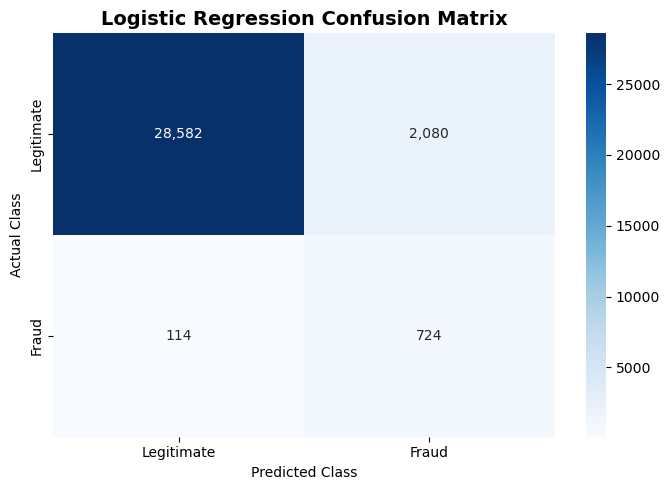

In [54]:

# STEP 5.3: Logistic Regression Performance Evaluation

import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Calculate evaluation metrics
logistic_accuracy = accuracy_score(
    y_test, logistic_predictions
)

logistic_precision = precision_score(
    y_test, logistic_predictions, zero_division=0
)

logistic_recall = recall_score(
    y_test, logistic_predictions, zero_division=0
)

logistic_f1 = f1_score(
    y_test, logistic_predictions, zero_division=0
)

logistic_roc_auc = roc_auc_score(
    y_test, logistic_probabilities
)

print(" LOGISTIC REGRESSION EVALUATION")
print("-" * 50)

# Display model metrics
logistic_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Score": [
        logistic_accuracy,
        logistic_precision,
        logistic_recall,
        logistic_f1,
        logistic_roc_auc
    ]
})

display(logistic_metrics.round(4))

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        logistic_predictions,
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_test,
    logistic_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

print("\nCONFUSION MATRIX COUNTS")
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

# Visualize confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt=",d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title(
    "Logistic Regression Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()


##### Findings — Logistic Regression Evaluation

The Logistic Regression baseline was evaluated on 31,500 held-out transactions using the default classification threshold of 0.50.

**Evaluation results:**

| Metric | Score |
|---|---:|
| Accuracy | 93.03% |
| Precision | 25.82% |
| Recall | 86.40% |
| F1-score | 0.3976 |
| ROC-AUC | 0.9394 |

**Confusion matrix findings:**

- True negatives: 28,582
- False positives: 2,080
- False negatives: 114
- True positives: 724

**Business interpretation:**

The model identifies 86.40% of fraudulent transactions but produces a substantial number of false-positive alerts.

Although its accuracy is 93.03%, this metric alone does not adequately describe performance because fraud represents only 2.66% of transactions.

The ROC-AUC score suggests strong discrimination between fraudulent and legitimate transactions on the current test split.

**Conclusion:** Logistic Regression provides a useful fraud detection baseline with high recall, but precision and operational alert burden require further improvement.

In [55]:

# STEP 5.4: Train Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest model
random_forest_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

print("RANDOM FOREST TRAINING")
print("-" * 50)

# Train on training data only
random_forest_model.fit(
    X_train_processed,
    y_train
)

print("Model training completed.")

print("\nMODEL INFORMATION")
print("Algorithm: Random Forest")
print("Number of trees:", random_forest_model.n_estimators)
print("Maximum depth:", random_forest_model.max_depth)
print("Class weighting:", random_forest_model.class_weight)
print("Number of features:", random_forest_model.n_features_in_)

# Generate predictions at the default threshold
rf_predictions = random_forest_model.predict(
    X_test_processed
)

# Generate fraud probability scores
rf_probabilities = random_forest_model.predict_proba(
    X_test_processed
)[:, 1]

print("\nTest predictions:", len(rf_predictions))
print("Fraud probability scores:", len(rf_probabilities))

# Validate predictions
assert len(rf_predictions) == len(y_test)
assert len(rf_probabilities) == len(y_test)

assert (
    (rf_probabilities >= 0)
    & (rf_probabilities <= 1)
).all()



RANDOM FOREST TRAINING
--------------------------------------------------
Model training completed.

MODEL INFORMATION
Algorithm: Random Forest
Number of trees: 300
Maximum depth: 10
Class weighting: balanced_subsample
Number of features: 42

Test predictions: 31500
Fraud probability scores: 31500


RANDOM FOREST EVALUATION
--------------------------------------------------


,Metric,Score
0,Accuracy,0.9486
1,Precision,0.3198
2,Recall,0.8258
3,F1-score,0.4610
4,ROC-AUC,0.9317



CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       1.00      0.95      0.97     30662
       Fraud       0.32      0.83      0.46       838

    accuracy                           0.95     31500
   macro avg       0.66      0.89      0.72     31500
weighted avg       0.98      0.95      0.96     31500


CONFUSION MATRIX COUNTS
True Negatives: 29190
False Positives: 1472
False Negatives: 146
True Positives: 692


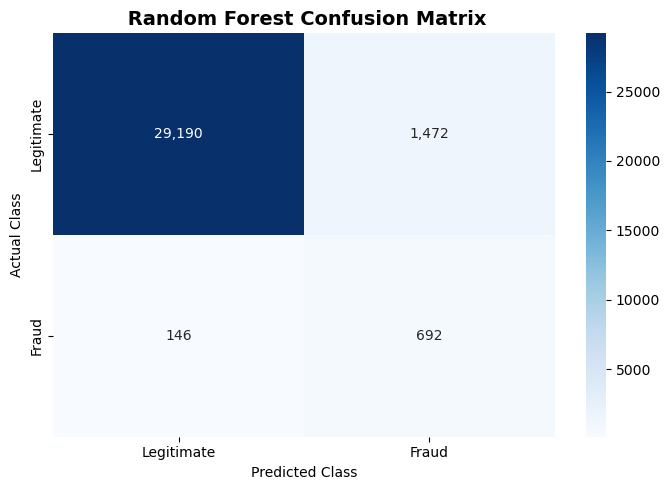

In [56]:

# STEP 5.5: Random Forest Performance Evaluation


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Calculate Random Forest metrics
rf_accuracy = accuracy_score(
    y_test, rf_predictions
)

rf_precision = precision_score(
    y_test, rf_predictions, zero_division=0
)

rf_recall = recall_score(
    y_test, rf_predictions, zero_division=0
)

rf_f1 = f1_score(
    y_test, rf_predictions, zero_division=0
)

rf_roc_auc = roc_auc_score(
    y_test, rf_probabilities
)

# Create evaluation summary
rf_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Score": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1,
        rf_roc_auc
    ]
})

print("RANDOM FOREST EVALUATION")
print("-" * 50)

display(rf_metrics.round(4))

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        rf_predictions,
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    )
)

# Calculate confusion matrix
rf_cm = confusion_matrix(
    y_test,
    rf_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = rf_cm.ravel()

print("\nCONFUSION MATRIX COUNTS")
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

# Visualize confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt=",d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title(
    " Random Forest Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()


##### Findings — Random Forest Performance Evaluation

The Random Forest classifier was evaluated on 31,500 held-out transactions using the default 0.50 threshold.

**Performance results:**

| Metric | Random Forest |
|---|---:|
| Accuracy | 94.86% |
| Precision | 31.98% |
| Recall | 82.58% |
| F1-score | 0.4610 |
| ROC-AUC | 0.9317 |

**Confusion matrix:**

- True negatives: 29,190
- False positives: 1,472
- False negatives: 146
- True positives: 692

**Comparison with Logistic Regression:**

Random Forest produces 608 fewer false-positive alerts, representing a 29.2% reduction compared with Logistic Regression.

However, it misses 32 additional fraudulent transactions.

Random Forest achieves higher precision and F1-score, while Logistic Regression achieves higher recall and ROC-AUC.

**Business interpretation:**

Random Forest may reduce unnecessary fraud investigations, while Logistic Regression offers stronger fraud coverage at the default classification threshold.

**Conclusion:**

Both models are promising baseline candidates. Final selection should consider fraud detection targets, review capacity, probability thresholds, and additional leakage-safe validation.

 MODEL PERFORMANCE COMPARISON
--------------------------------------------------


,Metric,Logistic Regression,Random Forest
0,Precision,0.2582,0.3198
1,Recall,0.8640,0.8258
2,F1-score,0.3976,0.4610
3,ROC-AUC,0.9394,0.9317


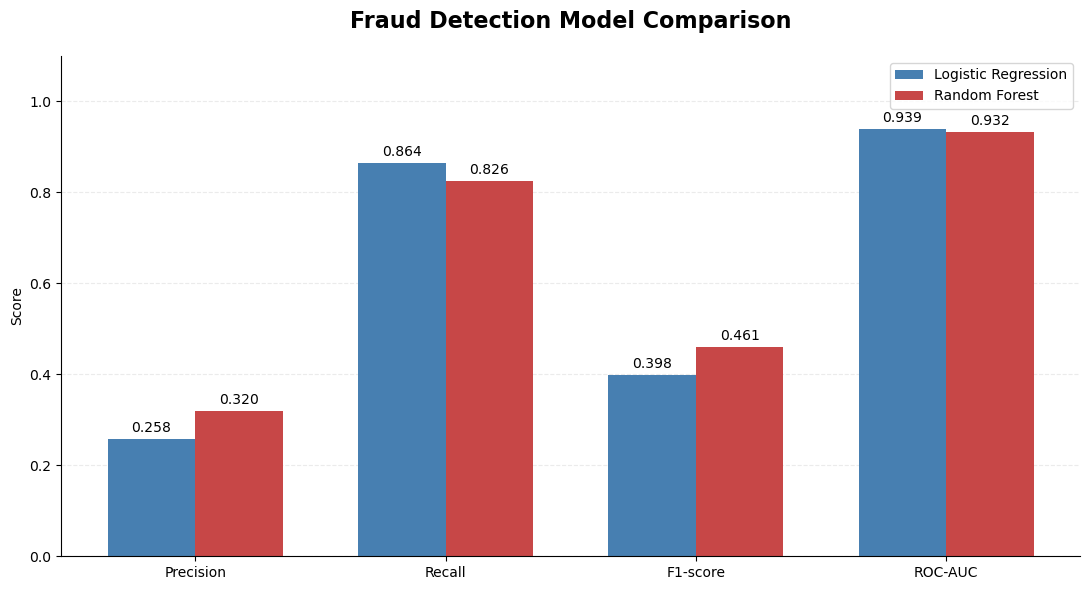

In [57]:

# STEP 5.6: Logistic Regression vs Random Forest Comparison


comparison = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1-score", "ROC-AUC"],
    "Logistic Regression": [
        logistic_precision,
        logistic_recall,
        logistic_f1,
        logistic_roc_auc
    ],
    "Random Forest": [
        rf_precision,
        rf_recall,
        rf_f1,
        rf_roc_auc
    ]
})

print(" MODEL PERFORMANCE COMPARISON")
print("-" * 50)

display(comparison.round(4))

# Create grouped bar chart
x = np.arange(len(comparison))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars_lr = ax.bar(
    x - width / 2,
    comparison["Logistic Regression"],
    width,
    label="Logistic Regression",
    color="#477FB1"
)

bars_rf = ax.bar(
    x + width / 2,
    comparison["Random Forest"],
    width,
    label="Random Forest",
    color="#C74747"
)

for bars in [bars_lr, bars_rf]:
    for bar in bars:
        ax.annotate(
            f"{bar.get_height():.3f}",
            (bar.get_x() + bar.get_width() / 2,
             bar.get_height()),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=10
        )

ax.set_title(
    "Fraud Detection Model Comparison",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(comparison["Metric"])
ax.set_ylim(0, 1.1)
ax.legend()

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


##### Findings — Logistic Regression vs Random Forest

Both fraud classification models were evaluated using the same 31,500 held-out transactions.

**Key findings:**

- Logistic Regression achieves higher recall (86.40%) and ROC-AUC (0.9394).
- Random Forest achieves higher precision (31.98%) and F1-score (0.4610).
- Random Forest produces 608 fewer false-positive alerts.
- Logistic Regression correctly identifies 32 additional fraudulent transactions.

**Business interpretation:**

Logistic Regression provides stronger fraud detection coverage at the default threshold, while Random Forest reduces the burden of unnecessary fraud investigations.

**Conclusion:**

Both models remain viable candidates. Random Forest has the better F1-score at the default threshold, but Logistic Regression demonstrates stronger recall and ROC-AUC. Further validation is required before selecting a production model.

 PRECISION-RECALL ANALYSIS
--------------------------------------------------


,Model,Average Precision
0,Logistic Regression,0.7102
1,Random Forest,0.5914


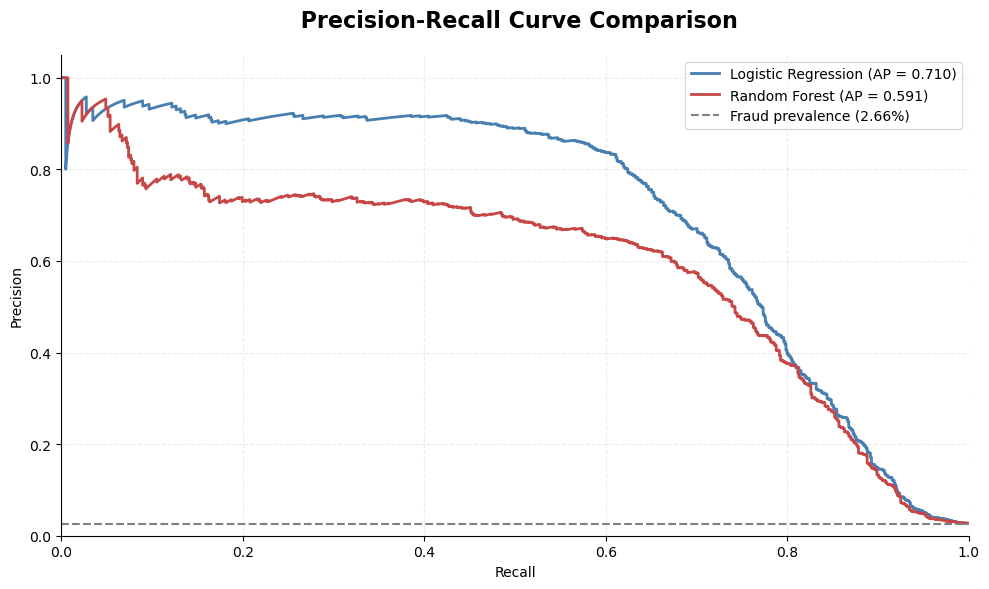

In [58]:

# STEP 5.7: Precision-Recall Curve Analysis


from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# Logistic Regression precision-recall curve
lr_precision, lr_recall, lr_thresholds = (
    precision_recall_curve(
        y_test,
        logistic_probabilities
    )
)

# Random Forest precision-recall curve
rf_precision_curve, rf_recall_curve, rf_thresholds = (
    precision_recall_curve(
        y_test,
        rf_probabilities
    )
)

# Calculate Average Precision
lr_ap = average_precision_score(
    y_test,
    logistic_probabilities
)

rf_ap = average_precision_score(
    y_test,
    rf_probabilities
)

print(" PRECISION-RECALL ANALYSIS")
print("-" * 50)

ap_summary = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Average Precision": [
        lr_ap,
        rf_ap
    ]
})

display(ap_summary.round(4))

# Plot precision-recall curves
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    lr_recall,
    lr_precision,
    color="#477FB1",
    linewidth=2,
    label=f"Logistic Regression (AP = {lr_ap:.3f})"
)

ax.plot(
    rf_recall_curve,
    rf_precision_curve,
    color="#C74747",
    linewidth=2,
    label=f"Random Forest (AP = {rf_ap:.3f})"
)

# Baseline precision = fraud prevalence
baseline = y_test.mean()

ax.axhline(
    baseline,
    color="gray",
    linestyle="--",
    label=f"Fraud prevalence ({baseline:.2%})"
)

ax.set_title(
    " Precision-Recall Curve Comparison",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)

ax.grid(alpha=0.25, linestyle="--")
ax.set_axisbelow(True)
ax.legend(loc="upper right")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


##### Findings — Precision–Recall Curve Analysis

The precision–recall curves of Logistic Regression and Random Forest were evaluated using the held-out test dataset.

**Results:**

| Model | Average Precision |
|---|---:|
| Logistic Regression | 0.7102 |
| Random Forest | 0.5914 |

**Key findings:**

- Logistic Regression achieves higher Average Precision than Random Forest.
- Logistic Regression maintains higher precision across much of the observed recall range.
- Random Forest's higher F1-score at threshold 0.50 does not establish superiority across other thresholds.
- Both models outperform the baseline fraud prevalence of 2.66%.

**Business implications:**

Logistic Regression appears promising for ranking transactions by fraud risk, potentially helping Finlora prioritize investigations.

**Conclusion:** Logistic Regression demonstrates stronger Average Precision, making it a promising candidate for threshold-based fraud risk prioritization.


TOP 15 BASELINE LOGISTIC REGRESSION COEFFICIENTS


,Feature,Coefficient,Absolute Coefficient
0,log_spending_ratio,1.2261,1.2261
1,transaction_velocity_1h,0.9075,0.9075
2,merchant_category_Gambling/Gaming,0.7500,0.7500
3,is_cross_border,0.6984,0.6984
4,is_new_device_Known,-0.6369,0.6369
5,is_new_device_New,0.5909,0.5909
6,merchant_category_Travel,-0.4761,0.4761
7,merchant_category_Subscription/SaaS,0.4045,0.4045
8,is_new_device_Unknown,-0.3871,0.3871
9,device_info_missing,-0.3871,0.3871


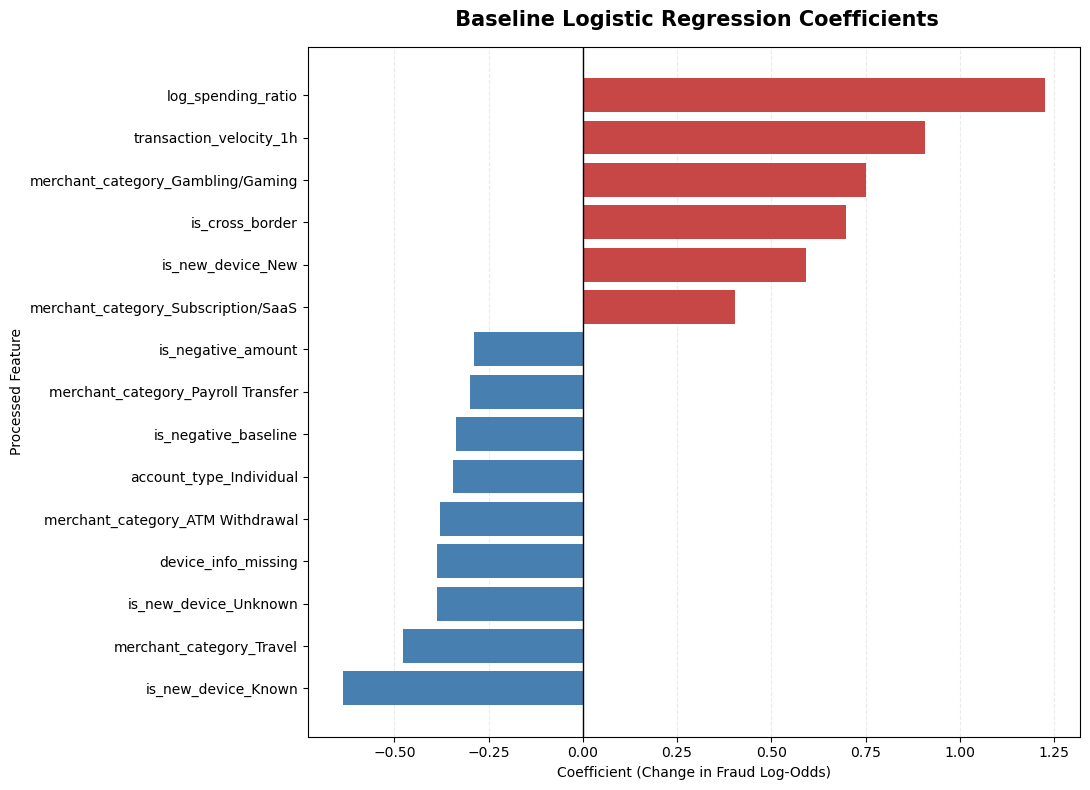

In [59]:

# STEP 5.8: BASELINE Logistic Regression coefficients


# Original fitted preprocessing pipeline
baseline_feature_names = preprocessor.get_feature_names_out()

# Original Logistic Regression baseline model
baseline_lr_values = logistic_model.coef_[0]

# Verify feature alignment
assert len(baseline_feature_names) == len(baseline_lr_values)

# Build coefficient table
baseline_lr_coefficients = pd.DataFrame({
    "Feature": baseline_feature_names,
    "Coefficient": baseline_lr_values
})

# Remove preprocessing prefixes
baseline_lr_coefficients["Feature"] = (
    baseline_lr_coefficients["Feature"]
    .str.replace(r"^[^_]+__", "", regex=True)
)

# Calculate absolute coefficient magnitude
baseline_lr_coefficients["Absolute Coefficient"] = (
    baseline_lr_coefficients["Coefficient"].abs()
)

# Sort by absolute magnitude
baseline_lr_coefficients = (
    baseline_lr_coefficients
    .sort_values(
        "Absolute Coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nTOP 15 BASELINE LOGISTIC REGRESSION COEFFICIENTS")

display(
    baseline_lr_coefficients.head(15).round(4)
)

# Plot top 15 coefficients
top_lr = (
    baseline_lr_coefficients.head(15)
    .sort_values("Coefficient")
)

colors = [
    "#C74747" if value > 0 else "#477FB1"
    for value in top_lr["Coefficient"]
]

plt.figure(figsize=(11, 8))

plt.barh(
    top_lr["Feature"],
    top_lr["Coefficient"],
    color=colors
)

plt.axvline(0, color="black", linewidth=1)

plt.title(
    " Baseline Logistic Regression Coefficients",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("Coefficient (Change in Fraud Log-Odds)")
plt.ylabel("Processed Feature")

plt.grid(axis="x", alpha=0.25, linestyle="--")
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()



##### Findings — Baseline Logistic Regression Coefficient Analysis

Coefficients were extracted from Finlora's original Logistic Regression baseline model trained using the stratified random training split.

**Strongest positive associations:**

| Feature | Coefficient |
|---|---:|
| Log spending ratio | +1.2261 |
| Transaction velocity | +0.9075 |
| Gambling/Gaming merchant category | +0.7500 |
| Cross-border activity | +0.6984 |
| New-device activity | +0.5909 |

**Notable negative associations:**

- Known-device category: −0.6369
- Travel merchant category: −0.4761
- Unknown-device category: −0.3871
- Missing device information: −0.3871
- ATM Withdrawal merchant category: −0.3790

**Comparison with baseline Random Forest:**

Both baseline models highlight transaction velocity and spending deviation as important fraud-risk signals.

Random Forest places greater emphasis on transaction amount, while Logistic Regression highlights conditional associations involving merchant category, cross-border activity, and device novelty.

**Business interpretation:**

Behavioral anomalies appear central to fraud detection, while device, geographic, and merchant-related information provides additional context.

**Limitations:**

Coefficient magnitudes depend on scaling and categorical encoding. Correlated predictors can affect individual coefficients. Model coefficients are not causal effects.

**Conclusion:**

The baseline Logistic Regression findings broadly agree with the baseline Random Forest results and earlier EDA observations, particularly regarding velocity and spending deviation.

BASELINE RANDOM FOREST FEATURE IMPORTANCE
-----------------------------------------------------------------

TOP 15 BASELINE RANDOM FOREST FEATURES


,Feature,Importance
0,transaction_velocity_1h,0.3773
1,log_spending_ratio,0.3443
2,signed_log_amount,0.0809
3,merchant_category_Payroll Transfer,0.0298
4,merchant_category_Wire Transfer,0.0215
5,hour_sin,0.0135
6,hour_cos,0.0132
7,account_type_Business,0.0132
8,account_type_Individual,0.0116
9,is_new_device_New,0.0090



TOTAL IMPORTANCE: 1.0


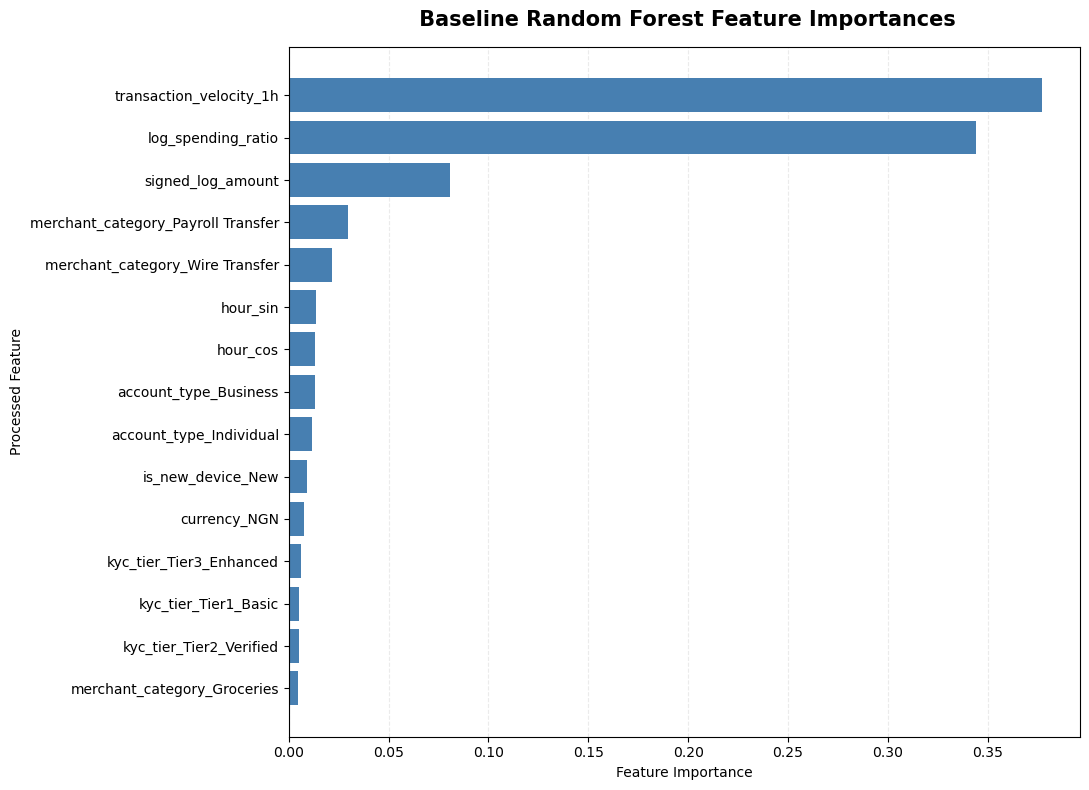

In [60]:

# STEP 5.9: BASELINE Random Forest feature importance


print("BASELINE RANDOM FOREST FEATURE IMPORTANCE")
print("-" * 65)

# Use the ORIGINAL fitted preprocessing pipeline
baseline_feature_names = preprocessor.get_feature_names_out()

# Use the  Random Forest baseline model
baseline_rf_importances = random_forest_model.feature_importances_

# Verify alignment
assert len(baseline_feature_names) == len(baseline_rf_importances)

# Create importance table
baseline_rf_feature_importance = pd.DataFrame({
    "Feature": baseline_feature_names,
    "Importance": baseline_rf_importances
})

# Remove preprocessing prefixes
baseline_rf_feature_importance["Feature"] = (
    baseline_rf_feature_importance["Feature"]
    .str.replace(r"^[^_]+__", "", regex=True)
)

# Rank features
baseline_rf_feature_importance = (
    baseline_rf_feature_importance
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

print("\nTOP 15 BASELINE RANDOM FOREST FEATURES")

display(
    baseline_rf_feature_importance.head(15).round(4)
)

print(
    "\nTOTAL IMPORTANCE:",
    round(baseline_rf_feature_importance["Importance"].sum(), 4)
)

# Plot the top 15 features
top_15 = (
    baseline_rf_feature_importance.head(15)
    .sort_values("Importance", ascending=True)
)

plt.figure(figsize=(11, 8))

plt.barh(
    top_15["Feature"],
    top_15["Importance"],
    color="#477FB1"
)

plt.title(
    " Baseline Random Forest Feature Importances",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("Feature Importance")
plt.ylabel("Processed Feature")

plt.grid(axis="x", alpha=0.25, linestyle="--")
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()




##### Findings — Baseline Random Forest Feature Importance

Feature importance was extracted from the original Random Forest baseline model trained using the stratified random training split.

**Top five features:**

| Feature | Importance |
|---|---:|
| Transaction velocity (1 hour) | 0.3773 |
| Log spending ratio | 0.3443 |
| Signed log transaction amount | 0.0809 |
| Payroll Transfer merchant category | 0.0298 |
| Wire Transfer merchant category | 0.0215 |

**Key findings:**

- Transaction velocity is the strongest predictor according to impurity-based importance.
- Spending deviation is the second most important feature.
- Transaction amount contributes additional predictive information.
- Merchant categories and transaction timing have smaller importance scores.
- The top three features account for approximately 80.25% of total importance.

**Agreement with earlier analysis:**

The baseline feature importance results reinforce the EDA and ablation findings that transaction velocity and spending deviation are dominant fraud detection signals.

**Limitations:**

Random Forest importance reflects contributions to tree-splitting decisions. It does not measure causation or indicate whether a feature increases or decreases fraud risk. Historical availability of the spending baseline still requires verification

**Conclusion:**

The original Random Forest baseline model relies heavily on recent transaction activity, spending deviation, and transaction amount.

BASELINE CROSS-MODEL COMPARISON
------------------------------------------------------------

BASELINE GROUPED FEATURE COMPARISON


,Feature_Group,RF_Importance,LR_Abs_Coefficient,RF_Rank,LR_Rank
0,transaction_velocity_1h,0.3773,0.9075,1,4
1,log_spending_ratio,0.3443,1.2261,2,3
2,signed_log_amount,0.0809,0.0889,3,13
3,merchant_category,0.0799,3.6824,4,1
4,transaction_hour,0.0268,0.0278,5,14
5,account_type,0.0247,0.4331,6,9
6,kyc_tier,0.0164,0.5877,7,6
7,currency,0.0157,0.5728,8,7
8,channel,0.0149,0.5613,9,8
9,is_new_device,0.0144,1.6149,10,2


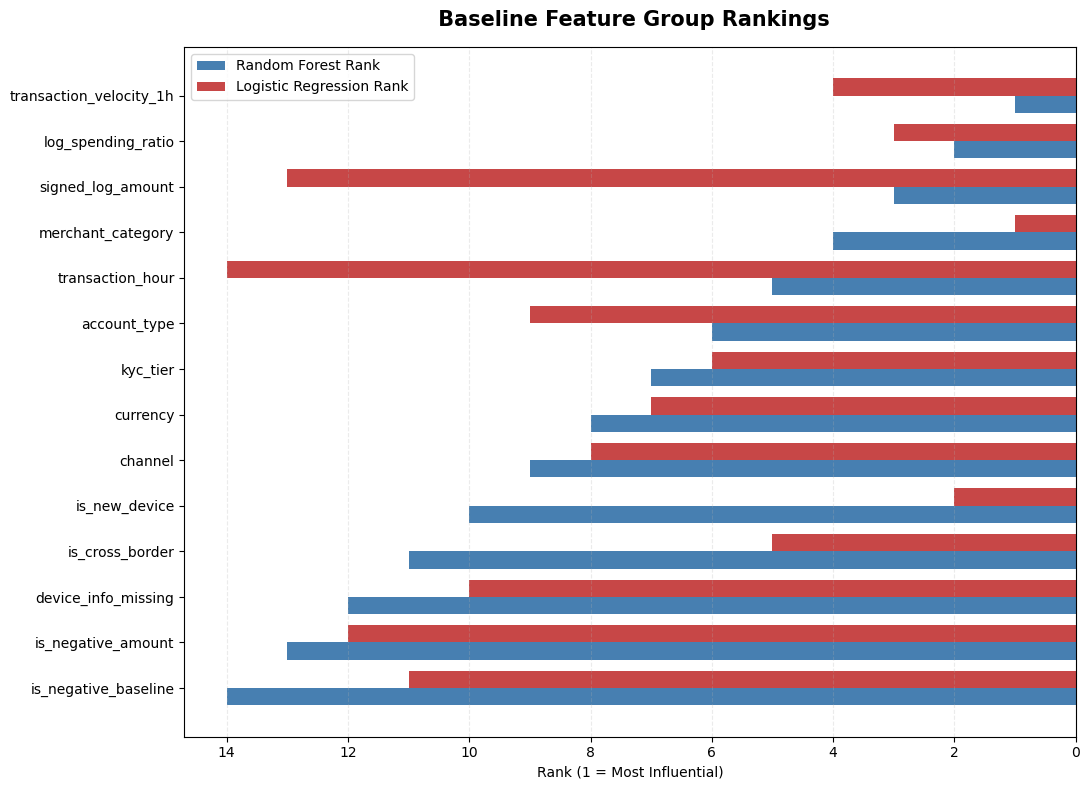

In [61]:

# STEP 5.10 : BASELINE cross-model feature comparison


print("BASELINE CROSS-MODEL COMPARISON")
print("-" * 60)

feature_names = preprocessor.get_feature_names_out()

comparison = pd.DataFrame({
    "Feature": feature_names,
    "RF_Importance": random_forest_model.feature_importances_,
    "LR_Abs_Coefficient": np.abs(logistic_model.coef_[0])
})

# Remove preprocessing prefixes
comparison["Feature"] = comparison["Feature"].str.replace(
    r"^[^_]+__",
    "",
    regex=True
)

def get_feature_group(feature):
    categorical_groups = [
        "merchant_category",
        "is_new_device",
        "account_type",
        "kyc_tier",
        "currency",
        "channel"
    ]

    for group in categorical_groups:
        if feature.startswith(group + "_"):
            return group

    if feature in ["hour_sin", "hour_cos"]:
        return "transaction_hour"

    return feature

comparison["Feature_Group"] = comparison["Feature"].apply(
    get_feature_group
)

grouped_importance = (
    comparison
    .groupby("Feature_Group", as_index=False)
    .agg(
        RF_Importance=("RF_Importance", "sum"),
        LR_Abs_Coefficient=("LR_Abs_Coefficient", "sum")
    )
)

# Rank features within each model
grouped_importance["RF_Rank"] = (
    grouped_importance["RF_Importance"]
    .rank(ascending=False, method="min")
    .astype(int)
)

grouped_importance["LR_Rank"] = (
    grouped_importance["LR_Abs_Coefficient"]
    .rank(ascending=False, method="min")
    .astype(int)
)

grouped_importance = (
    grouped_importance
    .sort_values("RF_Rank")
    .reset_index(drop=True)
)

print("\nBASELINE GROUPED FEATURE COMPARISON")
display(grouped_importance.round(4))

# Plot rank comparison
plot_data = grouped_importance.sort_values(
    "RF_Rank", ascending=False
)

y = np.arange(len(plot_data))
bar_height = 0.38

fig, ax = plt.subplots(figsize=(11, 8))

ax.barh(
    y - bar_height / 2,
    plot_data["RF_Rank"],
    bar_height,
    label="Random Forest Rank",
    color="#477FB1"
)

ax.barh(
    y + bar_height / 2,
    plot_data["LR_Rank"],
    bar_height,
    label="Logistic Regression Rank",
    color="#C74747"
)

ax.set_yticks(y)
ax.set_yticklabels(plot_data["Feature_Group"])
ax.invert_xaxis()

ax.set_title(
    " Baseline Feature Group Rankings",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Rank (1 = Most Influential)")
ax.legend()
ax.grid(axis="x", alpha=0.25, linestyle="--")

plt.tight_layout()
plt.show()



##### Findings — Baseline Cross-Model Feature Comparison

The original baseline Random Forest and Logistic Regression models were compared using feature importance scores and grouped absolute coefficient magnitudes.

**Key findings:**

- Transaction velocity ranks first in Random Forest and fourth in the grouped Logistic Regression comparison.
- Spending deviation ranks second in Random Forest and third in grouped Logistic Regression.
- Transaction amount ranks third in Random Forest but thirteenth in Logistic Regression.
- Merchant category ranks fourth in Random Forest and first under the grouped Logistic Regression method.
- Device novelty and cross-border activity receive greater prominence in Logistic Regression.
- Transaction channel receives relatively low importance rankings in both models.

**Agreement with exploratory data analysis:**

The models' emphasis on transaction velocity and spending deviation agrees with the earlier EDA findings that rapid account activity and unusually large spending deviations are associated with elevated fraud rates.

**Business interpretation:**

The baseline models rely heavily on behavioral transaction patterns. Transaction amount, device novelty, geographic activity, and merchant information provide additional context for risk assessment.


**Conclusion:**

Both baseline models emphasize transaction velocity and spending deviation. These findings support the development of interpretable fraud-review explanations, subject to further historical feature validation.

In [62]:

# STEP 5.11: BASELINE-informed manual fraud-rule evaluation



print("BASELINE MANUAL RULE EVALUATION")
print("-" * 60)

# Reconstruct the ORIGINAL stratified test dataset
# in the same order used by the baseline models.
baseline_rule_data = (
    cleaned_data
    .set_index("transaction_id")
    .loc[metadata_test["transaction_id"]]
    .reset_index()
    .copy()
)

# Verify alignment with original test labels
assert np.array_equal(
    baseline_rule_data["is_fraud"].to_numpy(),
    y_test
), "Baseline test labels are misaligned!"

ratio = baseline_rule_data["amount_to_avg_ratio"]

# Candidate rules based on baseline model findings
baseline_rule_definitions = {
    "Positive transaction velocity":
        baseline_rule_data["transaction_velocity_1h"] > 0,

    "Spending ratio > 10":
        ratio > 10,

    "New device AND ratio > 10":
        (
            (baseline_rule_data["is_new_device"] == 1)
            & (ratio > 10)
        ),

    "Cross-border AND ratio > 10":
        (
            (baseline_rule_data["is_cross_border"] == 1)
            & (ratio > 10)
        ),

    "Gambling/Gaming AND ratio > 10":
        (
            baseline_rule_data["merchant_category"].eq(
                "Gambling/Gaming"
            )
            & (ratio > 10)
        ),

    "Payroll/Wire AND ratio > 10":
        (
            baseline_rule_data["merchant_category"].isin(
                ["Payroll Transfer", "Wire Transfer"]
            )
            & (ratio > 10)
        )
}

baseline_rule_results = []

y_true = baseline_rule_data["is_fraud"].astype(int)

for rule_name, rule_predictions in baseline_rule_definitions.items():

    predicted = rule_predictions.fillna(False).astype(int)

    tp = int(((predicted == 1) & (y_true == 1)).sum())
    fp = int(((predicted == 1) & (y_true == 0)).sum())
    fn = int(((predicted == 0) & (y_true == 1)).sum())

    baseline_rule_results.append({
        "Rule": rule_name,
        "Precision": precision_score(
            y_true, predicted, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predicted, zero_division=0
        ),
        "True Positives": tp,
        "False Positives": fp,
        "False Negatives": fn,
        "Total Alerts": tp + fp
    })

baseline_rule_summary = pd.DataFrame(
    baseline_rule_results
)

print("\nBASELINE TEST TRANSACTIONS:", len(y_true))
print("BASELINE TEST FRAUD CASES:", int(y_true.sum()))

print("\nCANDIDATE MANUAL RULE PERFORMANCE")

display(
    baseline_rule_summary.round({
        "Precision": 4,
        "Recall": 4
    })
)

# Validate counts
assert all(
    baseline_rule_summary["True Positives"]
    + baseline_rule_summary["False Negatives"]
    == int(y_true.sum())
)

assert all(
    baseline_rule_summary["True Positives"]
    + baseline_rule_summary["False Positives"]
    == baseline_rule_summary["Total Alerts"]
)




BASELINE MANUAL RULE EVALUATION
------------------------------------------------------------

BASELINE TEST TRANSACTIONS: 31500
BASELINE TEST FRAUD CASES: 838

CANDIDATE MANUAL RULE PERFORMANCE


,Rule,Precision,Recall,True Positives,False Positives,False Negatives,Total Alerts
0,Positive transaction velocity,0.9246,0.3950,331,27,507,358
1,Spending ratio > 10,0.1856,0.4487,376,1650,462,2026
2,New device AND ratio > 10,0.3333,0.0215,18,36,820,54
3,Cross-border AND ratio > 10,0.2439,0.0119,10,31,828,41
4,Gambling/Gaming AND ratio > 10,0.0000,0.0000,0,4,838,4
5,Payroll/Wire AND ratio > 10,0.2070,0.3103,260,996,578,1256


##### Findings — Baseline-Informed Manual Fraud-Review Rules

Six candidate manual-review rules were evaluated using Finlora's original stratified random test dataset of 31,500 transactions, including 838 fraudulent cases.

**Key results:**

- Positive transaction velocity: 92.46% precision, 39.50% recall, and 358 total alerts.
- Spending ratio greater than 10: 18.56% precision, 44.87% recall, and 2,026 alerts.
- New device combined with high spending: 33.33% precision, 2.15% recall, and 54 alerts.
- Cross-border activity combined with high spending: 24.39% precision, 1.19% recall, and 41 alerts.
- Gambling/Gaming combined with high spending: 0% precision and recall, with four alerts.
- Payroll/Wire Transfer combined with high spending: 20.70% precision, 31.03% recall, and 1,256 alert.

**Conclusion:**

Positive transaction velocity is the strongest standalone candidate for a high-priority investigation trigger. Other signals may help analysts understand transaction context, but they should not replace the machine learning model or automatically determine fraud.

#### 5.25 — Baseline Model: Analyst-Facing Fraud Risk Explanations

**Objective:** Explain why Finlora may identify a transaction as potentially suspicious, using clear language grounded in the original baseline models.

##### How Finlora assesses transaction risk

Finlora evaluates transaction behavior and contextual information to help analysts identify activity that may require further review.

The baseline models place particular emphasis on recent account transaction activity and spending amounts that differ substantially from an account's reference spending level.

Other factors, including device novelty, cross-border activity, and merchant information, may provide supporting context.

##### Suggested analyst messages

**Recent transaction activity**

"One or more earlier transactions were recorded on this account within the previous hour. Review the sequence of activity for unusual patterns."

**Unusual spending deviation**

"This transaction amount is substantially different from the account's reference spending level. Review the transaction against the customer's known activity."

**New device**

"This transaction was initiated using a device marked as new for the account. Consider verifying whether the account holder recognizes the device."

**Cross-border activity**

"This transaction involves cross-border activity. Review the location and payment context alongside other available risk indicators."

**Merchant-category context**

"The merchant category provides additional information for reviewing this transaction. Assess it alongside the transaction amount and account history."

**Important limitations:** The spending baseline still requires historical validation, model scores are not yet calibrated probabilities, and the proposed review rules require further independent testing before deployment.


BASELINE ROC-AUC SCORES


,Model,ROC-AUC
0,Logistic Regression,0.9394
1,Random Forest,0.9317


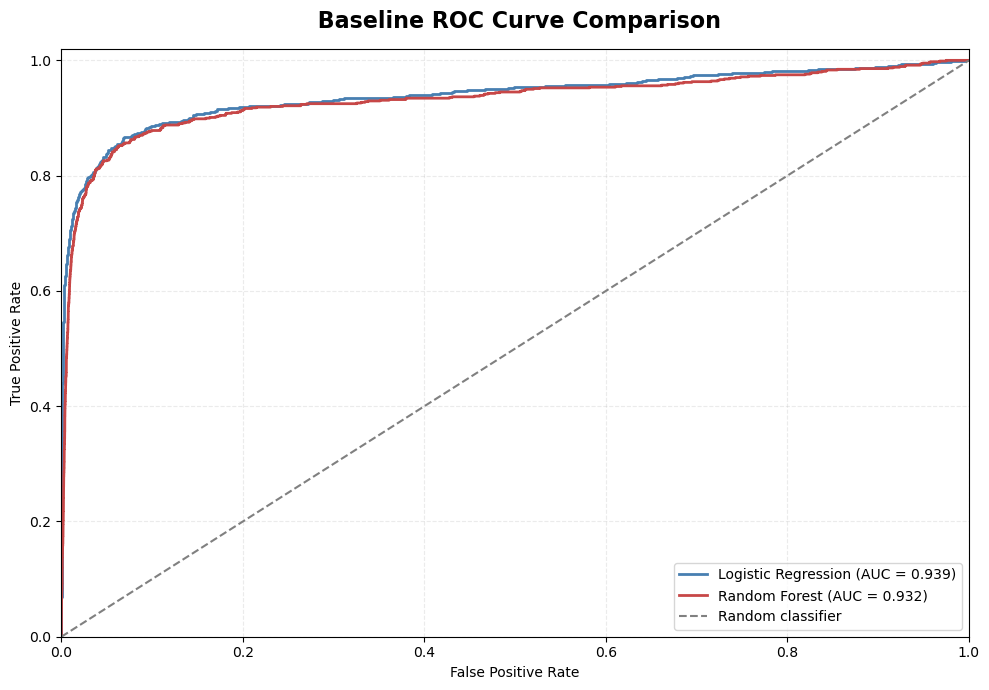

In [63]:

# STEP 5.12: Baseline ROC curve comparison


from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)


# Generate scores from the ORIGINAL baseline models
baseline_lr_scores = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

baseline_rf_scores = random_forest_model.predict_proba(
    X_test_processed
)[:, 1]

# Calculate ROC curves
lr_fpr, lr_tpr, _ = roc_curve(
    y_test,
    baseline_lr_scores
)

rf_fpr, rf_tpr, _ = roc_curve(
    y_test,
    baseline_rf_scores
)

# Calculate ROC-AUC
baseline_lr_auc = roc_auc_score(
    y_test,
    baseline_lr_scores
)

baseline_rf_auc = roc_auc_score(
    y_test,
    baseline_rf_scores
)

roc_summary = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "ROC-AUC": [
        baseline_lr_auc,
        baseline_rf_auc
    ]
})

print("\nBASELINE ROC-AUC SCORES")
display(roc_summary.round(4))

# Plot ROC curves
plt.figure(figsize=(10, 7))

plt.plot(
    lr_fpr,
    lr_tpr,
    label=f"Logistic Regression (AUC = {baseline_lr_auc:.3f})",
    linewidth=2,
    color="#477FB1"
)

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {baseline_rf_auc:.3f})",
    linewidth=2,
    color="#C74747"
)

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    color="gray",
    label="Random classifier"
)

plt.title(
    " Baseline ROC Curve Comparison",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.legend(loc="lower right")
plt.grid(alpha=0.25, linestyle="--")

plt.tight_layout()
plt.show()



##### Findings — Baseline ROC Curve Comparison

The original Logistic Regression and Random Forest baseline models were evaluated using the same stratified test dataset containing 31,500 transactions.

**Results:**

| Model | ROC-AUC |
|---|---:|
| Logistic Regression | 0.9394 |
| Random Forest | 0.9317 |

**Key findings:**

- Both models demonstrate strong discrimination between fraudulent and legitimate transactions.
- Logistic Regression achieves slightly higher ROC-AUC than Random Forest.
- Both ROC curves lie substantially above the random-classifier reference line.
- The models exhibit broadly similar ROC performance.

**Business interpretation:**

Logistic Regression demonstrates a small advantage in overall discrimination. However, precision, recall, and investigation workload are more directly relevant when choosing an operational threshold.


**Conclusion:**

Both baseline models demonstrate promising ROC performance, with Logistic Regression performing slightly better. Threshold selection requires additional precision–recall and workload analysis.


BASELINE AVERAGE PRECISION


,Model,Average Precision
0,Logistic Regression,0.7102
1,Random Forest,0.5914


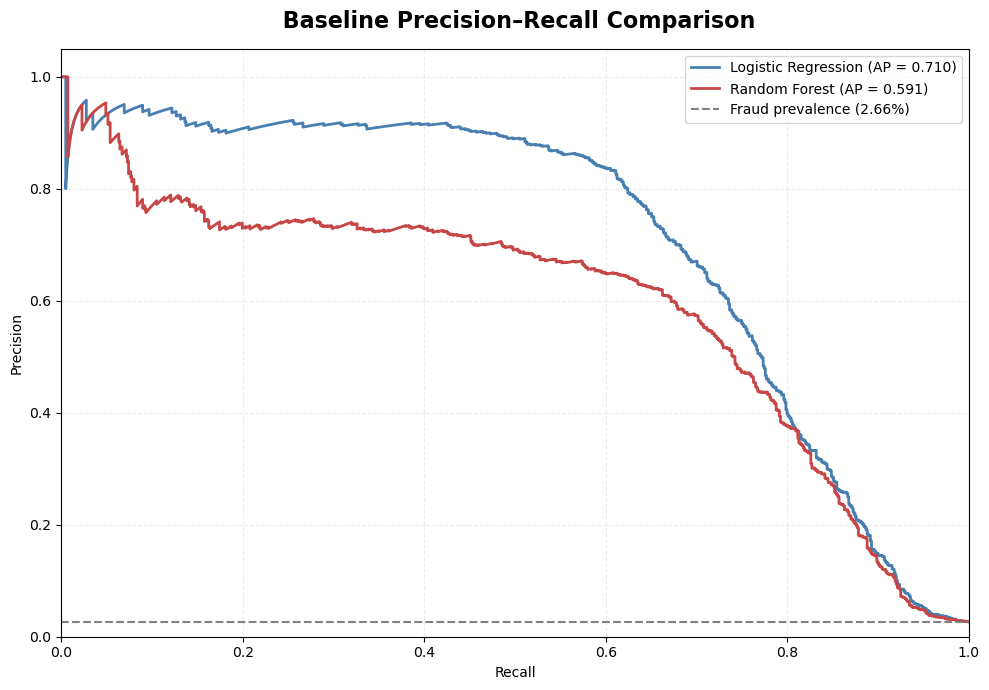

In [64]:

# STEP 5.13: Baseline precision-recall curve comparison


from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)



#  Baseline scores 
lr_precision, lr_recall, _ = precision_recall_curve(
    y_test,
    baseline_lr_scores
)

rf_precision, rf_recall, _ = precision_recall_curve(
    y_test,
    baseline_rf_scores
)

# Calculate Average Precision
lr_ap = average_precision_score(
    y_test,
    baseline_lr_scores
)

rf_ap = average_precision_score(
    y_test,
    baseline_rf_scores
)

ap_summary = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Average Precision": [lr_ap, rf_ap]
})

print("\nBASELINE AVERAGE PRECISION")
display(ap_summary.round(4))

# Plot
plt.figure(figsize=(10, 7))

plt.plot(
    lr_recall,
    lr_precision,
    color="#477FB1",
    linewidth=2,
    label=f"Logistic Regression (AP = {lr_ap:.3f})"
)

plt.plot(
    rf_recall,
    rf_precision,
    color="#C74747",
    linewidth=2,
    label=f"Random Forest (AP = {rf_ap:.3f})"
)

plt.axhline(
    y_test.mean(),
    color="gray",
    linestyle="--",
    label=f"Fraud prevalence ({y_test.mean():.2%})"
)

plt.title(
    " Baseline Precision–Recall Comparison",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.legend(loc="upper right")
plt.grid(alpha=0.25, linestyle="--")

plt.tight_layout()
plt.show()


##### Findings — Baseline Precision–Recall Comparison

The original Logistic Regression and Random Forest baseline models were evaluated on the stratified test dataset containing 31,500 transactions.

**Results:**

| Model | Average Precision |
|---|---:|
| Logistic Regression | 0.7102 |
| Random Forest | 0.5914 |

**Key findings:**

- Logistic Regression achieves higher Average Precision.
- Logistic Regression maintains higher precision across much of the observed recall range.
- Both models outperform the fraud prevalence baseline of 2.66%.
- The Random Forest's higher precision at the default 0.50 threshold does not establish better performance across other operating thresholds.

**Business interpretation:**

Logistic Regression appears more promising for ranking transactions by fraud risk, while the operational decision depends on the trade-off between fraud recall and investigation workload.

**Conclusion:**

Logistic Regression is the provisional preferred baseline model. Further operating-point and workload analysis is required before recommending a threshold for Finlora's analyst workflow.

In [65]:

# STEP 5.14: Select thresholds for target fraud recall


def select_recall_thresholds(y_true, probabilities, model_name):
    precision, recall, thresholds = precision_recall_curve(
        y_true, probabilities
    )

    results = []

    for target_recall in [0.70, 0.80, 0.90]:

        # Precision/recall arrays include one extra endpoint.
        # Match each threshold to its corresponding metrics.
        valid_indices = np.where(
            recall[:-1] >= target_recall
        )[0]

        if len(valid_indices) == 0:
            continue

        # Highest threshold that still achieves target recall
        idx = valid_indices[-1]
        threshold = thresholds[idx]

        # Generate predictions using selected threshold
        predictions = (
            probabilities >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true, predictions, labels=[0, 1]
        ).ravel()

        achieved_recall = tp / (tp + fn)
        achieved_precision = (
            tp / (tp + fp) if (tp + fp) > 0 else 0
        )

        results.append({
            "Model": model_name,
            "Target Recall": f"{target_recall:.0%}",
            "Threshold": threshold,
            "Achieved Recall": achieved_recall,
            "Precision": achieved_precision,
            "True Positives": tp,
            "False Positives": fp,
            "False Negatives": fn,
            "Total Alerts": tp + fp
        })

    return results


# Select thresholds for both validation models
threshold_results = []

threshold_results += select_recall_thresholds(
    y_val,
    logistic_val_probabilities,
    "Logistic Regression"
)

threshold_results += select_recall_thresholds(
    y_val,
    rf_val_probabilities,
    "Random Forest"
)

threshold_summary = pd.DataFrame(threshold_results)

print("RECALL-BASED THRESHOLD SELECTION")
print("-" * 55)

display(
    threshold_summary.round({
        "Threshold": 4,
        "Achieved Recall": 4,
        "Precision": 4
    })
)

print("\nVALIDATION CHECKS")

assert len(threshold_summary) == 6

for _, row in threshold_summary.iterrows():
    target = float(row["Target Recall"].strip("%")) / 100
    assert row["Achieved Recall"] >= target - 1e-10



RECALL-BASED THRESHOLD SELECTION
-------------------------------------------------------


,Model,Target Recall,Threshold,Achieved Recall,Precision,True Positives,False Positives,False Negatives,Total Alerts
0,Logistic Regression,70%,0.8848,0.7018,0.6513,353,189,150,542
1,Logistic Regression,80%,0.7055,0.8012,0.4026,403,598,100,1001
2,Logistic Regression,90%,0.3185,0.9006,0.1574,453,2425,50,2878
3,Random Forest,70%,0.7055,0.7018,0.5456,353,294,150,647
4,Random Forest,80%,0.5627,0.8012,0.3731,403,677,100,1080
5,Random Forest,90%,0.2461,0.9006,0.1050,453,3863,50,4316



VALIDATION CHECKS


##### Findings — Validation-Based Fraud Threshold Selection

The Logistic Regression and Random Forest models were evaluated on 18,900 validation transactions containing 503 fraudulent cases.

Thresholds were selected to achieve at least 70%, 80%, and 90% fraud recall.

**Key findings:**

- Logistic Regression achieves higher precision at all three target recall levels.
- At 70% recall, Logistic Regression generates 189 false positives, compared with 294 for Random Forest.
- At 80% recall, Logistic Regression generates 598 false positives, compared with 677 for Random Forest.
- At 90% recall, Logistic Regression generates 2,425 false positives, compared with 3,863 for Random Forest.
- Increasing recall from 80% to 90% substantially increases investigation workload.

**Business implications:**

Logistic Regression appears more efficient at prioritizing transactions for review when both models are compared at equivalent fraud detection targets.

An 80% recall operating point may offer a practical starting point for further evaluation, subject to Finlora's investigation capacity and risk tolerance.

**Conclusion:** Logistic Regression demonstrates a stronger validation precision–recall trade-off across the investigated recall targets, but final model and threshold selection require additional validation.

In [66]:

# STEP 5.15: Threshold operating points and analyst workload


# Adjustable business assumptions
minutes_per_alert = 10
productive_hours_per_analyst = 6

# Reconstruct the dates represented by the original random test set
test_dates = pd.to_datetime(
    raw_test["timestamp"],
    utc=True
)

start_date = test_dates.min().normalize()
end_date = test_dates.max().normalize()

calendar_days = (end_date - start_date).days + 1

# Original random test set contains 25% of all transactions
sample_multiplier = len(cleaned_data) / len(y_test)

# Reuse the FIXED validation-selected threshold test results
workload_summary = test_threshold_summary.copy()

# Observed workload in the random test sample
workload_summary["Sample Alerts/Day"] = (
    workload_summary["Total Alerts"] / calendar_days
)

# Illustrative estimate for full transaction volume
workload_summary["Estimated Alerts/Day"] = (
    workload_summary["Sample Alerts/Day"]
    * sample_multiplier
)

workload_summary["Estimated False Positives/Day"] = (
    workload_summary["False Positives"]
    / calendar_days
    * sample_multiplier
)

# Investigation workload assumptions
workload_summary["Investigation Hours/Day"] = (
    workload_summary["Estimated Alerts/Day"]
    * minutes_per_alert
    / 60
)

workload_summary["Analyst FTE Needed"] = (
    workload_summary["Investigation Hours/Day"]
    / productive_hours_per_analyst
)

# Display clear operating-point comparison
output_columns = [
    "Model",
    "Target Recall",
    "Threshold",
    "Test Recall",
    "Test Precision",
    "Total Alerts",
    "Estimated Alerts/Day",
    "Estimated False Positives/Day",
    "Investigation Hours/Day",
    "Analyst FTE Needed"
]

print("\nWORKLOAD ASSUMPTIONS")
print("Test period:", start_date.date(), "to", end_date.date())
print("Calendar days:", calendar_days)
print("Test sample multiplier:", sample_multiplier)
print("Minutes per alert:", minutes_per_alert)
print(
    "Productive hours per analyst/day:",
    productive_hours_per_analyst
)

print("\nTHRESHOLD OPERATING-POINT TABLE")

display(
    workload_summary[output_columns].round(2)
)

# Integrity checks
assert calendar_days > 0
assert sample_multiplier > 0
assert (workload_summary["Estimated Alerts/Day"] >= 0).all()





WORKLOAD ASSUMPTIONS
Test period: 2025-02-01 to 2026-08-30
Calendar days: 576
Test sample multiplier: 4.0
Minutes per alert: 10
Productive hours per analyst/day: 6

THRESHOLD OPERATING-POINT TABLE


,Model,Target Recall,Threshold,Test Recall,Test Precision,Total Alerts,Estimated Alerts/Day,Estimated False Positives/Day,Investigation Hours/Day,Analyst FTE Needed
0,Logistic Regression,70%,0.88,0.70,0.66,887,6.16,2.09,1.03,0.17
1,Logistic Regression,80%,0.71,0.79,0.42,1588,11.03,6.40,1.84,0.31
2,Logistic Regression,90%,0.32,0.90,0.16,4800,33.33,28.10,5.56,0.93
3,Random Forest,70%,0.71,0.69,0.55,1052,7.31,3.27,1.22,0.20
4,Random Forest,80%,0.56,0.80,0.38,1784,12.39,7.71,2.06,0.34
5,Random Forest,90%,0.25,0.91,0.11,7052,48.97,43.65,8.16,1.36


##### Findings — Fraud Thresholds and Analyst Workload

The previously selected validation thresholds were evaluated on the original held-out test dataset, and their alert volumes were converted into illustrative daily investigation workload estimates.

**Assumptions:**

- Historical period: 576 calendar days
- Random test sample: 25% of transactions
- Investigation time: 10 minutes per alert
- Productive analyst time: 6 hours per day

**Logistic Regression findings:**

| Target Recall | Test Recall | Precision | Estimated Alerts/Day | Analyst FTE |
|---|---:|---:|---:|---:|
| 70% | 69.93% | 66.07% | 6.16 | 0.17 |
| 80% | 79.47% | 41.94% | 11.03 | 0.31 |
| 90% | 89.86% | 15.69% | 33.33 | 0.93 |

**Key findings:**

- Logistic Regression generates fewer alerts than Random Forest at each nominal recall target.
- Higher recall substantially increases investigation workload.
- Increasing the Logistic Regression operating point from approximately 80% to 90% recall adds 87 detected fraud cases but also 3,125 false-positive alerts in the test sample.
- The nominal 80% recall setting provides a promising balance between fraud detection and alert workload.

**Preliminary recommendation:**

Retain Logistic Regression's validation-selected threshold of approximately 0.7055 as a candidate operating point for further evaluation.

**Limitations:**

- The threshold applies to the validation-trained model version.
- The achieved test recall is 79.47%, slightly below the 80% target.
- Daily workload and staffing figures are illustrative averages, not observed production workload.
- Threshold and staffing decisions require operational capacity information and independent validation.
- Historical availability of the 30-day spending baseline remains unverified.

**Conclusion:**

A nominal 80% recall setting is a reasonable provisional choice for further investigation, while a 90% setting would require significantly greater fraud-review capacity.

In [67]:

# STEP 5.16: Machine learning vs manual rules



# Use previously calculated workload assumptions
# calendar_days, sample_multiplier, minutes_per_alert

# Machine learning operating points
ml_comparison = workload_summary[
    [
        "Model",
        "Target Recall",
        "Test Precision",
        "Test Recall",
        "Total Alerts"
    ]
].copy()

ml_comparison["Method"] = (
    "ML: " + ml_comparison["Model"]
    + " (" + ml_comparison["Target Recall"] + " target)"
)

ml_comparison = ml_comparison.rename(columns={
    "Test Precision": "Precision",
    "Test Recall": "Recall"
})

ml_comparison = ml_comparison[
    ["Method", "Precision", "Recall", "Total Alerts"]
]

# Baseline-informed manual rules
rule_comparison = baseline_rule_summary[
    ["Rule", "Precision", "Recall", "Total Alerts"]
].copy()

rule_comparison["Method"] = (
    "Rule: " + rule_comparison["Rule"]
)

rule_comparison = rule_comparison[
    ["Method", "Precision", "Recall", "Total Alerts"]
]

# Combine results
ml_vs_rules = pd.concat(
    [ml_comparison, rule_comparison],
    ignore_index=True
)

# Apply the same full-volume assumptions
ml_vs_rules["Estimated Alerts/Day"] = (
    ml_vs_rules["Total Alerts"]
    / calendar_days
    * sample_multiplier
)

ml_vs_rules["Investigation Hours/Day"] = (
    ml_vs_rules["Estimated Alerts/Day"]
    * minutes_per_alert
    / 60
)

print("\nMODEL AND RULE COMPARISON")

display(
    ml_vs_rules.round({
        "Precision": 4,
        "Recall": 4,
        "Estimated Alerts/Day": 2,
        "Investigation Hours/Day": 2
    })
)




MODEL AND RULE COMPARISON


,Method,Precision,Recall,Total Alerts,Estimated Alerts/Day,Investigation Hours/Day
0,ML: Logistic Regression (70% target),0.6607,0.6993,887,6.16,1.03
1,ML: Logistic Regression (80% target),0.4194,0.7947,1588,11.03,1.84
2,ML: Logistic Regression (90% target),0.1569,0.8986,4800,33.33,5.56
3,ML: Random Forest (70% target),0.5523,0.6933,1052,7.31,1.22
4,ML: Random Forest (80% target),0.3778,0.8043,1784,12.39,2.06
5,ML: Random Forest (90% target),0.1086,0.9141,7052,48.97,8.16
6,Rule: Positive transaction velocity,0.9246,0.3950,358,2.49,0.41
7,Rule: Spending ratio > 10,0.1856,0.4487,2026,14.07,2.34
8,Rule: New device AND ratio > 10,0.3333,0.0215,54,0.38,0.06
9,Rule: Cross-border AND ratio > 10,0.2439,0.0119,41,0.28,0.05


#### 5.16 — Provisional Fraud Detection Operating Threshold Recommendation

##### Objective

Recommend a practical fraud detection operating point using model discrimination, precision, recall, analyst workload, and comparisons with candidate manual-review rules.

##### Preferred model

**Logistic Regression** is the provisional preferred model.

The original baseline model achieved:

- ROC-AUC: 0.9394
- Average Precision: 0.7102

These results exceed the corresponding Random Forest baseline scores of 0.9317 and 0.5914.

##### Recommended candidate threshold

A threshold of approximately **0.7055** is recommended for further evaluation using the validation-trained Logistic Regression model.

On the held-out random test sample, this setting achieved:

- Recall: 79.47%
- Precision: 41.94%
- True positives: 666
- False positives: 922
- False negatives: 172
- Total alerts: 1,588

##### Estimated investigation workload

Using the illustrative full-volume assumptions:

- Estimated alerts per day: 11.03
- Estimated investigation hours per day: 1.84
- Estimated analyst capacity: 0.31 FTE

These estimates assume 10 minutes per alert and six productive hours per analyst per day. They represent historical average workload rather than peak operational demand.

##### Trade-off analysis

At the nominal 70% recall setting, fewer alerts are generated, but more fraudulent transactions are missed.

At the nominal 90% recall setting, more fraud is detected, but false-positive alerts and investigation workload increase substantially.

The nominal 80% setting provides a practical intermediate option. However, observed test recall is slightly below 80%, so it does not satisfy a strict minimum 80% requirement.

##### Comparison with manual rules

The positive transaction-velocity rule achieved 92.46% precision and 39.50% recall on the original baseline test dataset.

This rule is promising for investigation prioritization but provides insufficient fraud coverage to replace the machine learning model.

Other rules involving spending deviation, new devices, cross-border activity, and merchant categories may provide useful analyst context.

##### Deployment considerations

Before adopting the recommended operating point, Finlora should:

- Complete point-in-time validation of the 30-day spending baseline.
- Confirm the selected model version and establish its corresponding operating threshold.
- Verify performance on fresh chronological data.
- Confirm analyst capacity and investigation costs.
- Evaluate overlap between rule-based alerts and model-based alerts.
- Assess score calibration and potential changes in fraud patterns.

##### Final recommendation

Retain Logistic Regression as the provisional preferred model and its nominal 80% recall operating point as the primary candidate for further validation.

Use manual risk indicators to support analyst understanding and prioritization rather than as automatic proof of fraud.

**Status:** Research recommendation only; not approved for production deployment.

In [68]:

# STEP 5.17: False-negative analysis
#  Logistic Regression baseline — threshold 0.50


# Reconstruct original test transactions in saved test order
error_data = (
    cleaned_data
    .set_index("transaction_id")
    .loc[metadata_test["transaction_id"]]
    .reset_index()
    .copy()
)

# Verify correct alignment with test labels
assert np.array_equal(
    error_data["is_fraud"].to_numpy(),
    np.asarray(y_test)
), "Test data and labels are not aligned!"

# Original baseline Logistic Regression scores
error_data["Fraud_Score"] = (
    logistic_model.predict_proba(X_test_processed)[:, 1]
)

# Use default threshold for baseline error analysis
error_threshold = 0.50

error_data["Prediction"] = (
    error_data["Fraud_Score"] >= error_threshold
).astype(int)

# Label prediction outcomes
conditions = [
    (error_data["is_fraud"] == 1)
    & (error_data["Prediction"] == 1),

    (error_data["is_fraud"] == 1)
    & (error_data["Prediction"] == 0),

    (error_data["is_fraud"] == 0)
    & (error_data["Prediction"] == 1),

    (error_data["is_fraud"] == 0)
    & (error_data["Prediction"] == 0)
]

error_data["Outcome"] = np.select(
    conditions,
    ["TP", "FN", "FP", "TN"],
    default="Unknown"
)

# Extract fraudulent transactions only
detected_fraud = error_data[
    error_data["Outcome"] == "TP"
].copy()

missed_fraud = error_data[
    error_data["Outcome"] == "FN"
].copy()

print("\nFRAUD DETECTION SUMMARY")
print("Total actual fraud:", int((error_data["is_fraud"] == 1).sum()))
print("Detected fraud (TP):", len(detected_fraud))
print("Missed fraud (FN):", len(missed_fraud))

print("\nBEHAVIORAL COMPARISON")

def summarize_fraud_group(data, name):
    return {
        "Group": name,
        "Transactions": len(data),
        "Median Amount": data["amount"].abs().median(),
        "Median Spending Ratio": (
            data["amount_to_avg_ratio"].median()
        ),
        "Positive Velocity (%)": (
            (data["transaction_velocity_1h"] > 0).mean() * 100
        ),
        "Ratio > 10 (%)": (
            (data["amount_to_avg_ratio"] > 10).mean() * 100
        ),
        "New Device (%)": (
            (data["is_new_device"] == 1).mean() * 100
        ),
        "Cross Border (%)": (
            (data["is_cross_border"] == 1).mean() * 100
        ),
        "Median Fraud Score": data["Fraud_Score"].median()
    }

fraud_error_summary = pd.DataFrame([
    summarize_fraud_group(
        detected_fraud, "Detected Fraud (TP)"
    ),
    summarize_fraud_group(
        missed_fraud, "Missed Fraud (FN)"
    )
])

display(fraud_error_summary.round(3))

# Inspect score distribution for missed fraud
print("\nMISSED FRAUD SCORE DISTRIBUTION")

display(
    missed_fraud["Fraud_Score"]
    .describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90])
    .round(4)
)

# Integrity check
tn, fp, fn, tp = confusion_matrix(
    y_test,
    error_data["Prediction"],
    labels=[0, 1]
).ravel()

assert tp == len(detected_fraud)
assert fn == len(missed_fraud)




FRAUD DETECTION SUMMARY
Total actual fraud: 838
Detected fraud (TP): 724
Missed fraud (FN): 114

BEHAVIORAL COMPARISON


,Group,Transactions,Median Amount,Median Spending Ratio,Positive Velocity (%),Ratio > 10 (%),New Device (%),Cross Border (%),Median Fraud Score
0,Detected Fraud (TP),724,183841.120,11.66,45.718,51.657,5.525,1.657,0.995
1,Missed Fraud (FN),114,13825.145,1.00,0.000,1.754,7.895,3.509,0.155



MISSED FRAUD SCORE DISTRIBUTION


count    114.0000
mean       0.2022
std        0.1373
min        0.0353
10%        0.0588
25%        0.0836
50%        0.1554
75%        0.3008
90%        0.4115
max        0.4997
Name: Fraud_Score, dtype: float64

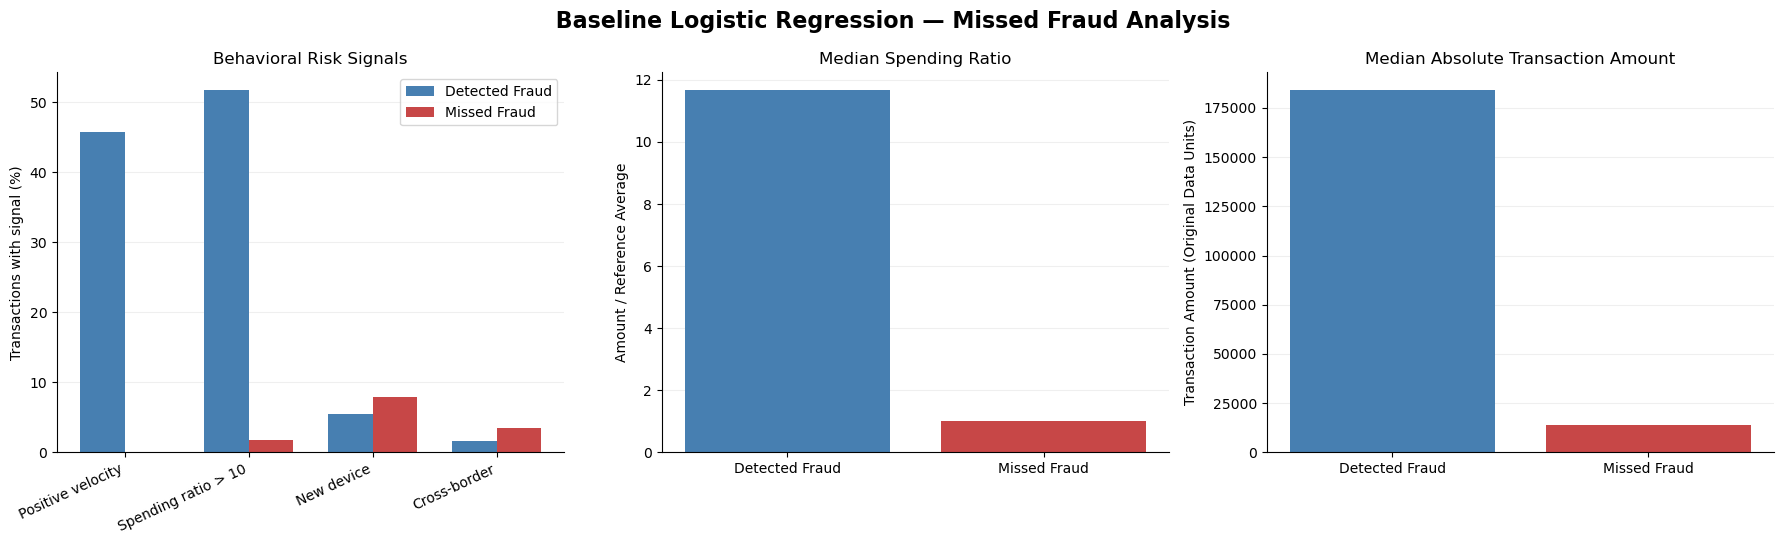

In [69]:

# STEP 5.17B: Visualize false-negative patterns


# Reuse the existing Step 5.17 results
plot_data = fraud_error_summary.set_index("Group")

groups = [
    "Detected Fraud (TP)",
    "Missed Fraud (FN)"
]

labels = ["Detected Fraud", "Missed Fraud"]

colors = ["#477FB1", "#C74747"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5.5)
)

# 1. Behavioral risk signals
signals = [
    "Positive Velocity (%)",
    "Ratio > 10 (%)",
    "New Device (%)",
    "Cross Border (%)"
]

signal_labels = [
    "Positive velocity",
    "Spending ratio > 10",
    "New device",
    "Cross-border"
]

x = np.arange(len(signals))
width = 0.36

for i, group in enumerate(groups):
    values = plot_data.loc[group, signals].astype(float).values

    axes[0].bar(
        x + (i - 0.5) * width,
        values,
        width,
        color=colors[i],
        label=labels[i]
    )

axes[0].set_xticks(x)
axes[0].set_xticklabels(
    signal_labels,
    rotation=25,
    ha="right"
)

axes[0].set_ylabel("Transactions with signal (%)")
axes[0].set_title("Behavioral Risk Signals")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.2)

# 2. Median spending ratio
ratio_values = plot_data.loc[
    groups,
    "Median Spending Ratio"
].astype(float).values

axes[1].bar(
    labels,
    ratio_values,
    color=colors
)

axes[1].set_title("Median Spending Ratio")
axes[1].set_ylabel("Amount / Reference Average")
axes[1].grid(axis="y", alpha=0.2)

# 3. Median transaction amount
amount_values = plot_data.loc[
    groups,
    "Median Amount"
].astype(float).values

axes[2].bar(
    labels,
    amount_values,
    color=colors
)

axes[2].set_title("Median Absolute Transaction Amount")
axes[2].set_ylabel("Transaction Amount (Original Data Units)")
axes[2].grid(axis="y", alpha=0.2)

# General styling
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_axisbelow(True)

fig.suptitle(
    " Baseline Logistic Regression — Missed Fraud Analysis",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



##### Visualization Findings — Missed Fraud Patterns

The false-negative visualizations compare 724 correctly detected fraudulent transactions against 114 missed fraudulent transactions from the original Logistic Regression baseline model.

**Key observations:**

- None of the missed fraudulent transactions had positive one-hour transaction velocity, compared with 45.72% of detected fraud.
- Only 1.75% of missed fraud had a spending ratio above 10, compared with 51.66% of detected fraud.
- Detected fraud had a median spending ratio of 11.66, while missed fraud had a median ratio of 1.00.
- Missed fraud had a substantially lower median recorded transaction amount than detected fraud.
- New-device and cross-border indicators were present in both groups but occurred slightly more frequently among missed cases.

**Interpretation:**

The model appears more successful at detecting fraud involving rapid transaction activity and substantial spending deviations.

Fraudulent transactions with less distinctive behavioral characteristics are more likely to escape detection.


**Conclusion:**

The visualization identifies low-anomaly fraudulent transactions as a priority area for further model investigation and independent validation.

In [70]:

# STEP 5.18: False-positive error analysis
#  Logistic Regression baseline — threshold 0.50


# Reuse error_data from Step 5.17
correct_legitimate = error_data[
    error_data["Outcome"] == "TN"
].copy()

false_positives = error_data[
    error_data["Outcome"] == "FP"
].copy()

print("\nLEGITIMATE TRANSACTION SUMMARY")
print("Total legitimate:", len(correct_legitimate) + len(false_positives))
print("Correctly ignored (TN):", len(correct_legitimate))
print("Incorrectly flagged (FP):", len(false_positives))

def summarize_legitimate_group(data, name):
    return {
        "Group": name,
        "Transactions": len(data),
        "Median Amount": data["amount"].abs().median(),
        "Median Spending Ratio": (
            data["amount_to_avg_ratio"].median()
        ),
        "Positive Velocity (%)": (
            (data["transaction_velocity_1h"] > 0).mean() * 100
        ),
        "Ratio > 10 (%)": (
            (data["amount_to_avg_ratio"] > 10).mean() * 100
        ),
        "New Device (%)": (
            (data["is_new_device"] == 1).mean() * 100
        ),
        "Cross Border (%)": (
            (data["is_cross_border"] == 1).mean() * 100
        ),
        "Median Fraud Score": data["Fraud_Score"].median()
    }

fp_summary = pd.DataFrame([
    summarize_legitimate_group(
        correct_legitimate,
        "Correct Legitimate (TN)"
    ),
    summarize_legitimate_group(
        false_positives,
        "False Positives (FP)"
    )
])

print("\nLEGITIMATE BEHAVIOR COMPARISON")
display(fp_summary.round(3))

print("\nFALSE-POSITIVE SCORE DISTRIBUTION")
display(
    false_positives["Fraud_Score"]
    .describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    )
    .round(4)
)

# Examine false positives by amount deviation
print("\nFALSE POSITIVES BY SPENDING-RATIO GROUP")

fp_ratio_summary = (
    false_positives
    .assign(
        Ratio_Group=np.where(
            false_positives["amount_to_avg_ratio"] > 10,
            "Ratio > 10",
            "Ratio <= 10"
        )
    )
    .groupby("Ratio_Group")
    .agg(
        Alerts=("is_fraud", "size"),
        Median_Score=("Fraud_Score", "median")
    )
    .reset_index()
)

display(fp_ratio_summary.round(4))




LEGITIMATE TRANSACTION SUMMARY
Total legitimate: 30662
Correctly ignored (TN): 28582
Incorrectly flagged (FP): 2080

LEGITIMATE BEHAVIOR COMPARISON


,Group,Transactions,Median Amount,Median Spending Ratio,Positive Velocity (%),Ratio > 10 (%),New Device (%),Cross Border (%),Median Fraud Score
0,Correct Legitimate (TN),28582,4488.95,0.800,0.000,0.248,2.663,2.019,0.098
1,False Positives (FP),2080,78948.37,15.125,1.298,75.913,6.106,3.510,0.682



FALSE-POSITIVE SCORE DISTRIBUTION


count    2080.0000
mean        0.7027
std         0.1400
min         0.5005
10%         0.5306
25%         0.5845
50%         0.6818
75%         0.8073
90%         0.9190
max         1.0000
Name: Fraud_Score, dtype: float64


FALSE POSITIVES BY SPENDING-RATIO GROUP


,Ratio_Group,Alerts,Median_Score
0,Ratio <= 10,501,0.5677
1,Ratio > 10,1579,0.7236


##### Findings — False-Positive Error Analysis

The original Logistic Regression baseline model incorrectly flagged 2,080 of 30,662 legitimate transactions at a classification threshold of 0.50, giving a false-positive rate of approximately 6.78%.

**Key observations:**

- False-positive transactions had a median absolute amount of 78,948.37, compared with 4,488.95 for correctly ignored legitimate transactions.
- The median spending ratio was 15.125 among false positives, compared with 0.800 among true negatives.
- A total of 1,579 false positives (75.91%) had spending ratios greater than 10.
- New-device activity was present in 6.11% of false positives, compared with 2.66% of true negatives.
- Cross-border activity was present in 3.51% of false positives, compared with 2.02% of true negatives.
- The median false-positive model score was 0.6818.

**Business interpretation:**

The baseline model may generate unnecessary alerts for legitimate transactions involving substantial spending deviations or unusually large recorded amounts.

False positives create investigation workload and could cause customer friction if alerts trigger additional verification or transaction interruptions.

**Limitations:**

These findings describe associations rather than the causal drivers of individual predictions. Cross-currency transaction amounts are not directly comparable without conversion, and historical validity of the spending baseline remains unverified.

**Conclusion:**

High spending deviation is the clearest observed characteristic associated with false-positive alerts. Improving the distinction between legitimate unusual spending and actual fraud is an important area for further investigation.

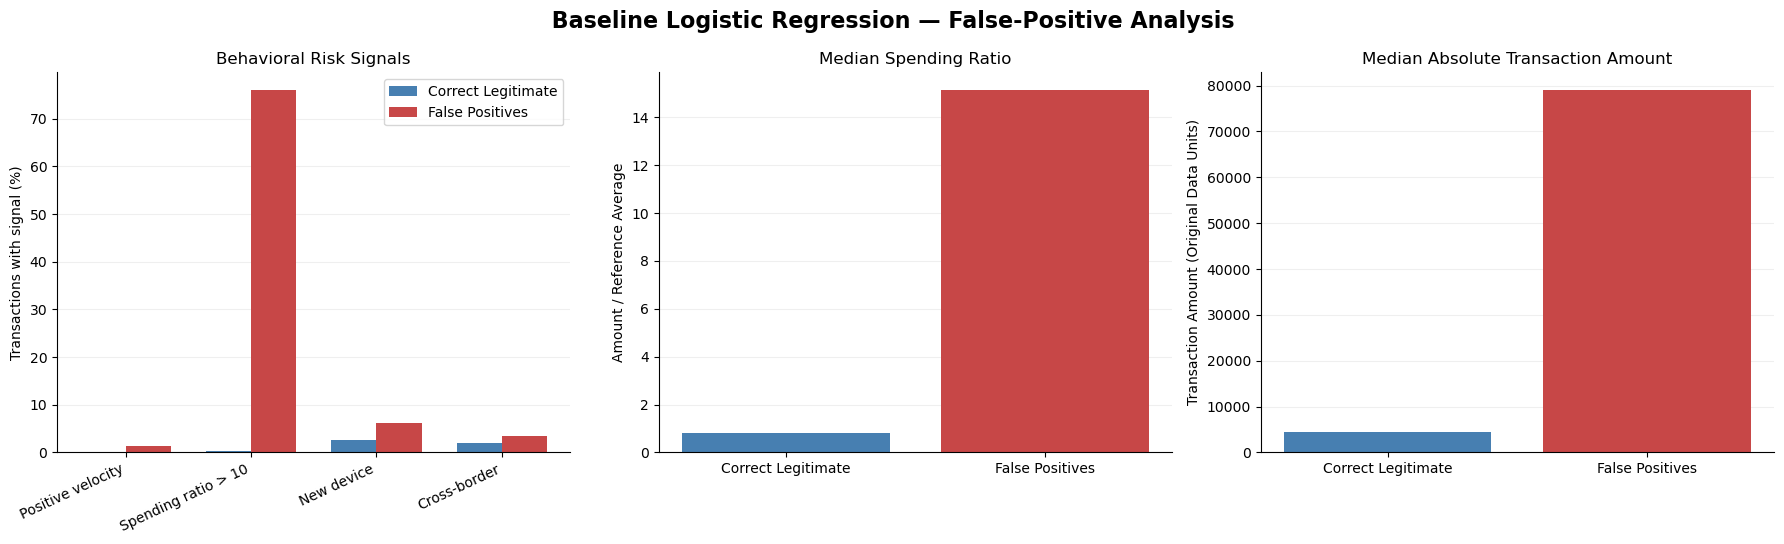

In [71]:

# STEP 5.18B: Visualize false-positive patterns


plot_data = fp_summary.set_index("Group")

groups = [
    "Correct Legitimate (TN)",
    "False Positives (FP)"
]

labels = [
    "Correct Legitimate",
    "False Positives"
]

colors = ["#477FB1", "#C74747"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5.5)
)

# Chart 1 — Behavioral risk signals
signals = [
    "Positive Velocity (%)",
    "Ratio > 10 (%)",
    "New Device (%)",
    "Cross Border (%)"
]

signal_labels = [
    "Positive velocity",
    "Spending ratio > 10",
    "New device",
    "Cross-border"
]

x = np.arange(len(signals))
width = 0.36

for i, group in enumerate(groups):

    values = (
        plot_data.loc[group, signals]
        .astype(float)
        .values
    )

    axes[0].bar(
        x + (i - 0.5) * width,
        values,
        width,
        color=colors[i],
        label=labels[i]
    )

axes[0].set_xticks(x)
axes[0].set_xticklabels(
    signal_labels,
    rotation=25,
    ha="right"
)

axes[0].set_ylabel("Transactions with signal (%)")
axes[0].set_title("Behavioral Risk Signals")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.2)

# Chart 2 — Median spending ratio
ratio_values = (
    plot_data.loc[
        groups,
        "Median Spending Ratio"
    ]
    .astype(float)
    .values
)

axes[1].bar(
    labels,
    ratio_values,
    color=colors
)

axes[1].set_title("Median Spending Ratio")
axes[1].set_ylabel("Amount / Reference Average")
axes[1].grid(axis="y", alpha=0.2)

# Chart 3 — Median absolute transaction amount
amount_values = (
    plot_data.loc[
        groups,
        "Median Amount"
    ]
    .astype(float)
    .values
)

axes[2].bar(
    labels,
    amount_values,
    color=colors
)

axes[2].set_title(
    "Median Absolute Transaction Amount"
)

axes[2].set_ylabel(
    "Transaction Amount (Original Data Units)"
)

axes[2].grid(axis="y", alpha=0.2)

# Formatting
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_axisbelow(True)

fig.suptitle(
    " Baseline Logistic Regression — False-Positive Analysis",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



##### Visualization Findings — False-Positive Patterns

The false-positive visualization compares 28,582 correctly ignored legitimate transactions with 2,080 legitimate transactions incorrectly flagged as fraudulent by the original Logistic Regression baseline model.

**Key observations:**

- A spending ratio greater than 10 was present in 75.91% of false positives, compared with only 0.25% of correctly ignored legitimate transactions.
- The median spending ratio was 15.125 for false positives, compared with 0.800 for true negatives.
- False-positive transactions had substantially larger median recorded amounts.
- New-device and cross-border indicators were more common among incorrectly flagged legitimate transactions.
- Positive one-hour transaction velocity remained relatively uncommon among legitimate transactions, including false positives.

**Business interpretation:**

The model is sensitive to unusually large spending deviations, which can lead to unnecessary investigations of legitimate customer activity.

This creates potential analyst workload and customer-friction risks.

**Limitations:**

The results are descriptive rather than causal. Cross-currency transaction values are not directly comparable without normalization, and the spending baseline remains subject to historical validation.

**Conclusion:**

Legitimate transactions involving unusual spending patterns represent an important source of false-positive alerts. Future model refinement should focus on improving fraud discrimination without increasing missed fraudulent transactions.

In [72]:

# STEP 5.19: Segment-level model performance
#  Logistic Regression baseline, threshold 0.50


segment_columns = [
    "account_type",
    "kyc_tier",
    "channel",
    "currency"
]

def calculate_segment_metrics(data, segment_column):

    results = []

    for segment_value, group in data.groupby(
        segment_column, dropna=False
    ):

        tp = int((group["Outcome"] == "TP").sum())
        tn = int((group["Outcome"] == "TN").sum())
        fp = int((group["Outcome"] == "FP").sum())
        fn = int((group["Outcome"] == "FN").sum())

        actual_fraud = tp + fn
        actual_legitimate = tn + fp

        precision = (
            tp / (tp + fp)
            if tp + fp > 0 else np.nan
        )

        recall = (
            tp / actual_fraud
            if actual_fraud > 0 else np.nan
        )

        false_positive_rate = (
            fp / actual_legitimate
            if actual_legitimate > 0 else np.nan
        )

        results.append({
            "Segment": segment_value,
            "Transactions": len(group),
            "Fraud Cases": actual_fraud,
            "Fraud Rate (%)": (
                actual_fraud / len(group) * 100
            ),
            "Precision (%)": precision * 100,
            "Recall (%)": recall * 100,
            "False Positive Rate (%)": (
                false_positive_rate * 100
            ),
            "False Positives": fp,
            "False Negatives": fn
        })

    return pd.DataFrame(results).sort_values(
        "Transactions",
        ascending=False
    ).reset_index(drop=True)

# Run all four segment analyses
segment_results = {}

for column in segment_columns:

    summary = calculate_segment_metrics(
        error_data,
        column
    )

    segment_results[column] = summary

    print(f"\nPERFORMANCE BY {column.upper()}")
    display(summary.round(2))

# Integrity checks: every transaction belongs to one segment
for column, summary in segment_results.items():
    assert summary["Transactions"].sum() == len(error_data)
    assert summary["False Positives"].sum() == (
        error_data["Outcome"] == "FP"
    ).sum()
    assert summary["False Negatives"].sum() == (
        error_data["Outcome"] == "FN"
    ).sum()




PERFORMANCE BY ACCOUNT_TYPE


,Segment,Transactions,Fraud Cases,Fraud Rate (%),Precision (%),Recall (%),False Positive Rate (%),False Positives,False Negatives
0,Individual,20577,415,2.02,21.73,80.48,5.97,1203,81
1,Business,10923,423,3.87,30.78,92.20,8.35,877,33



PERFORMANCE BY KYC_TIER


,Segment,Transactions,Fraud Cases,Fraud Rate (%),Precision (%),Recall (%),False Positive Rate (%),False Positives,False Negatives
0,Tier2_Verified,16049,447,2.79,28.59,86.80,6.21,969,59
1,Tier3_Enhanced,9828,214,2.18,21.82,87.38,6.97,670,27
2,Tier1_Basic,5623,177,3.15,25.25,84.18,8.10,441,28



PERFORMANCE BY CHANNEL


,Segment,Transactions,Fraud Cases,Fraud Rate (%),Precision (%),Recall (%),False Positive Rate (%),False Positives,False Negatives
0,Mobile App,10440,271,2.60,26.18,87.82,6.60,671,33
1,Web Dashboard,7746,243,3.14,29.50,87.65,6.78,509,30
2,Card Not Present,4422,114,2.58,25.48,80.70,6.24,269,22
3,Card Present,3714,82,2.21,20.18,80.49,7.19,261,16
4,API/Integration,3345,100,2.99,24.27,92.00,8.84,287,8
5,USSD,1833,28,1.53,21.70,82.14,4.60,83,5



PERFORMANCE BY CURRENCY


,Segment,Transactions,Fraud Cases,Fraud Rate (%),Precision (%),Recall (%),False Positive Rate (%),False Positives,False Negatives
0,NGN,15994,524,3.28,27.34,88.55,7.97,1233,60
1,USD,6259,126,2.01,24.64,81.75,5.14,315,23
2,GBP,4779,88,1.84,20.40,80.68,5.90,277,17
3,EUR,4468,100,2.24,25.22,86.00,5.84,255,14


##### Findings — Segment-Level Performance Analysis

The original Logistic Regression baseline model was evaluated at a 0.50 classification threshold across account type, KYC tier, transaction channel, and currency.

**Account type:** Individual accounts achieved 80.48% recall, compared with 92.20% for Business accounts. Business accounts had a higher false-positive rate of 8.35%, compared with 5.97% for Individual accounts.

**KYC tier:** Tier1_Basic had the lowest recall (84.18%) and highest false-positive rate (8.10%). Differences in recall across KYC tiers were smaller than those observed between account types.

**Transaction channel:** API/Integration achieved the highest observed recall (92.00%) but also had the highest false-positive rate (8.84%). Card Present and Card Not Present showed relatively low recall, at 80.49% and 80.70%, respectively.

**Currency:** NGN had the highest recall (88.55%) and false-positive rate (7.97%). GBP had the lowest recall (80.68%).

**Business interpretation:**

The model's error rates vary across account and transaction segments. These differences may affect fraud detection coverage, investigation workload, and customer experience.

**Limitations:**

- Differences are descriptive and do not establish causation or unfair treatment.
- Segment fraud prevalence and sample sizes vary.
- Smaller groups may have unstable metric estimates.
- Segments overlap and should not be treated as independent groups.
- The dataset is synthetic, so results may not generalize to real-world transactions.

**Conclusion:**

Individual accounts, card transaction channels, Tier1_Basic accounts, and GBP transactions warrant further examination for missed fraud. Business accounts, API/Integration transactions, and NGN transactions warrant examination for higher false-positive rates.

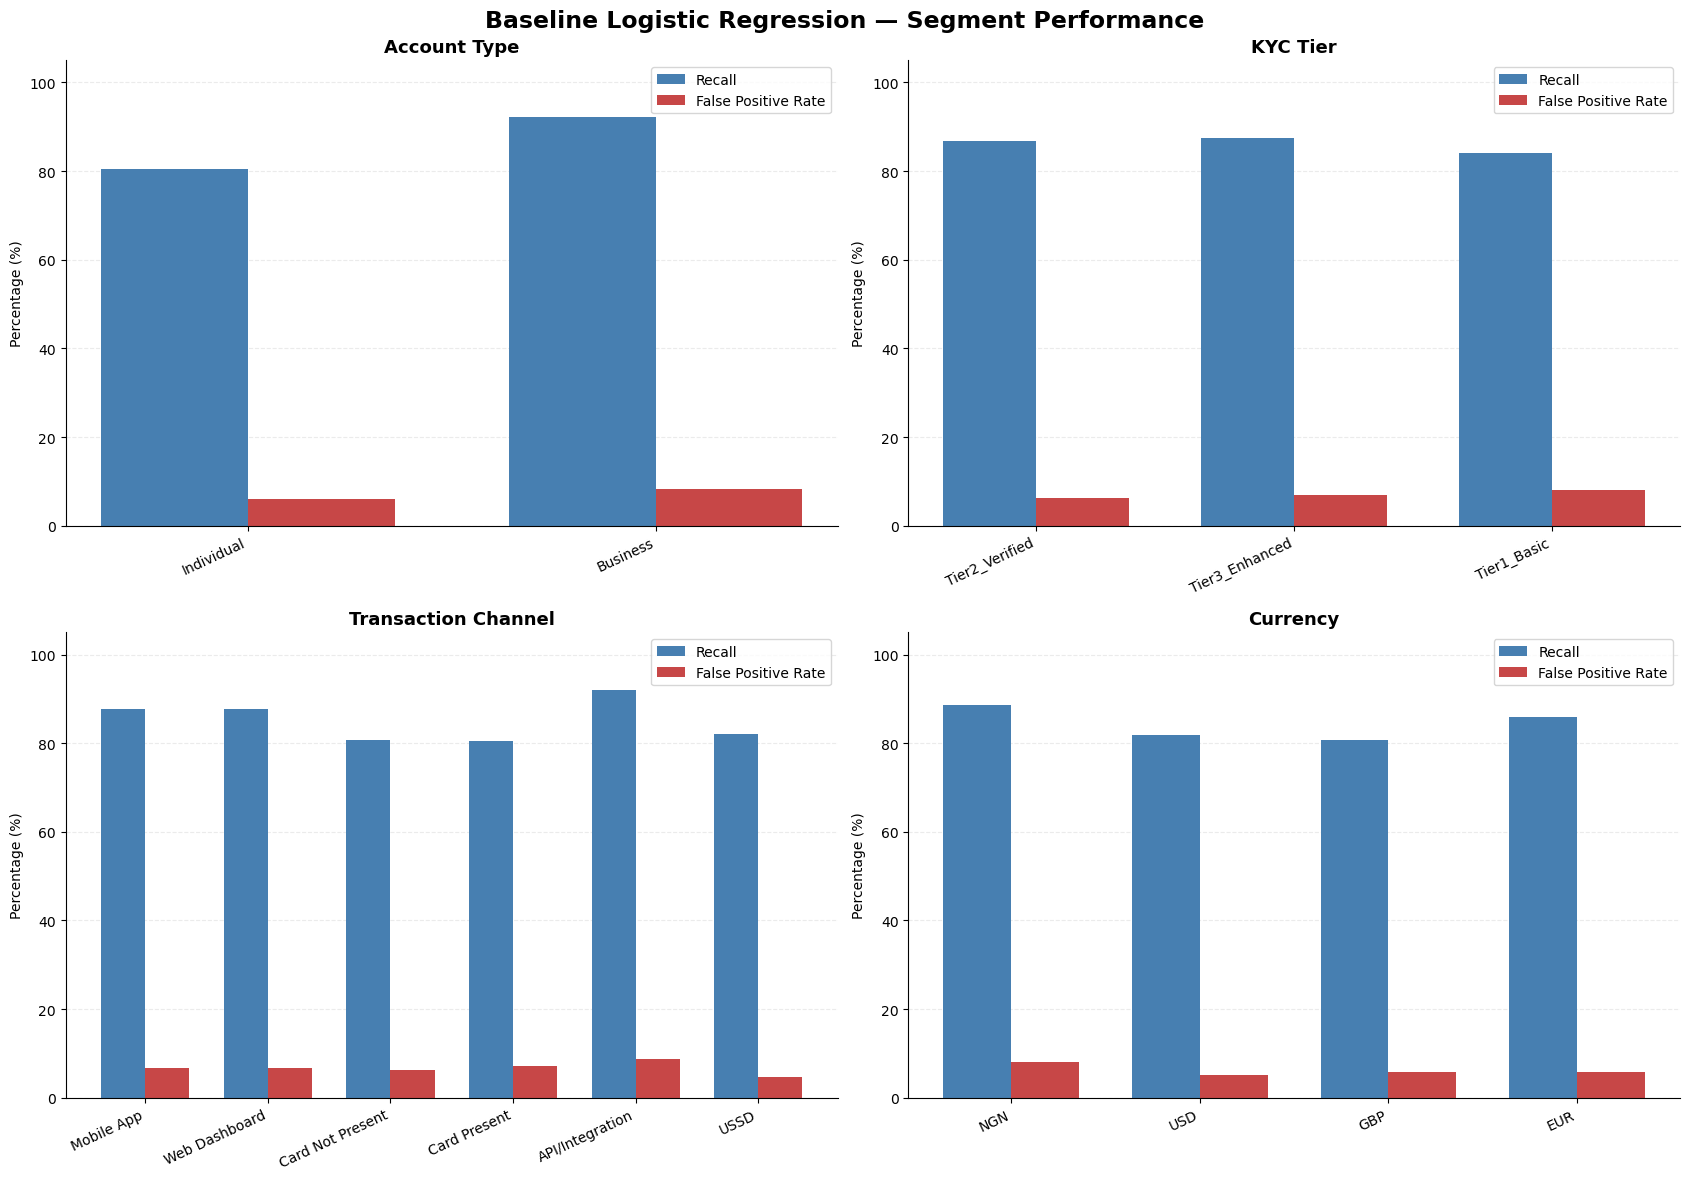

In [73]:

# STEP 5.19B: Visualize segment performance


segment_titles = {
    "account_type": "Account Type",
    "kyc_tier": "KYC Tier",
    "channel": "Transaction Channel",
    "currency": "Currency"
}

fig, axes = plt.subplots( 2, 2, figsize=(17, 12)
)

axes = axes.flatten()

for ax, (column, title) in zip(
    axes,
    segment_titles.items()
):

    data = segment_results[column].copy()

    labels = data["Segment"].astype(str).tolist()
    recall = data["Recall (%)"].values
    fpr = data["False Positive Rate (%)"].values

    x = np.arange(len(labels))
    width = 0.36

    ax.bar(
        x - width / 2,
        recall,
        width,
        label="Recall",
        color="#477FB1"
    )

    ax.bar(
        x + width / 2,
        fpr,
        width,
        label="False Positive Rate",
        color="#C74747"
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_ylabel("Percentage (%)")
    ax.set_ylim(0, 105)

    ax.set_xticks(x)
    ax.set_xticklabels(
        labels,
        rotation=25,
        ha="right"
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)
    ax.legend()

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

fig.suptitle(
    "Baseline Logistic Regression — Segment Performance",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



##### Visualization Findings — Segment-Level Model Performance

The four-panel visualization compares fraud recall and false-positive rates across account types, KYC tiers, transaction channels, and currencies.

**Key findings:**

- Business accounts achieved substantially higher recall than Individual accounts (92.20% versus 80.48%), but also had a higher false-positive rate.
- Tier1_Basic had the lowest recall and highest false-positive rate among KYC tiers.
- API/Integration achieved the highest recall among channels (92.00%) but also the highest channel false-positive rate (8.84%).
- Card Present and Card Not Present had comparatively low fraud recall.
- NGN had the highest recall and false-positive rate among currencies, while GBP had the lowest recall.

**Business interpretation:**

The model exhibits variation in fraud detection coverage and unnecessary alert rates across transaction segments.

These differences may influence investigation workload and the effectiveness of fraud monitoring for different transaction groups.

**Limitations:**

- Segment-level differences are descriptive, not causal.
- Fraud prevalence and sample sizes vary between groups.
- The same transaction belongs to multiple segment categories.
- The synthetic dataset may not represent real-world customer behavior.
- These findings do not establish whether the model treats customers unfairly.

**Conclusion:**

Individual accounts, card transaction channels, and GBP transactions should receive attention during further missed-fraud analysis. Business accounts, API/Integration transactions, and NGN transactions warrant investigation for higher false-positive rates.


TRAIN VS TEST PERFORMANCE


,Model,Split,Precision,Recall,F1,ROC-AUC,Average Precision
0,Logistic Regression,Train,0.2532,0.8564,0.3909,0.9348,0.6791
1,Logistic Regression,Test,0.2582,0.8640,0.3976,0.9394,0.7102
2,Random Forest,Train,0.3193,0.8512,0.4644,0.9661,0.7392
3,Random Forest,Test,0.3198,0.8258,0.4610,0.9317,0.5914



TRAIN-TEST PERFORMANCE GAPS


,Model,Precision Gap,Recall Gap,F1 Gap,ROC-AUC Gap,Average Precision Gap
0,Logistic Regression,-0.0050,-0.0076,-0.0067,-0.0047,-0.0311
1,Random Forest,-0.0005,0.0255,0.0034,0.0345,0.1478


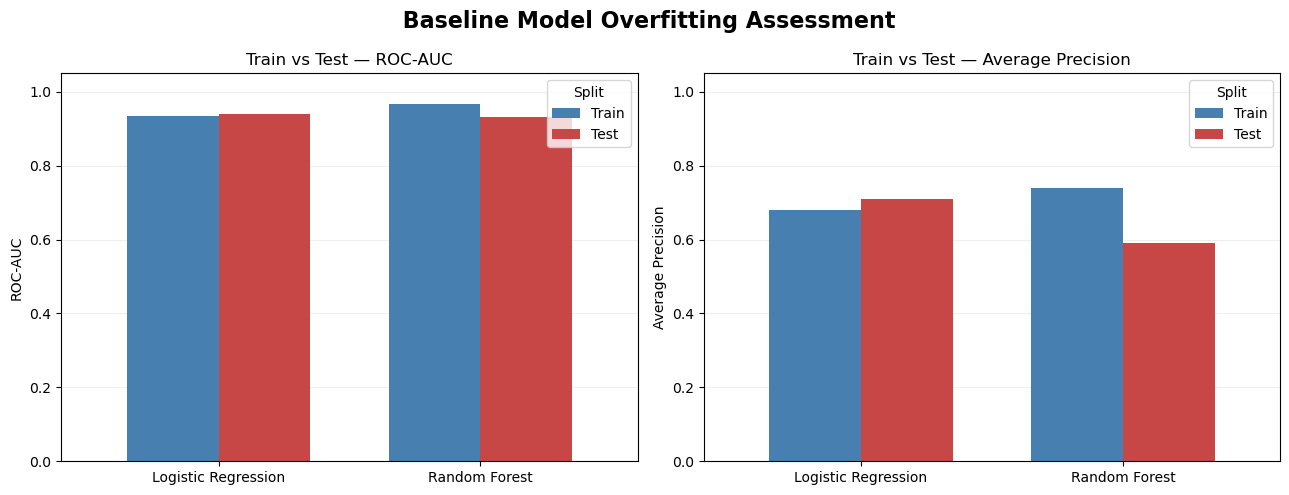

In [74]:

# STEP 5.20: Train vs test overfitting assessment
# Baseline models, threshold 0.50


baseline_models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

def evaluate_split(model, X, y, split_name):

    scores = model.predict_proba(X)[:, 1]

    predictions = (
        scores >= 0.50
    ).astype(int)

    return {
        "Split": split_name,
        "Precision": precision_score(
            y, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y, predictions, zero_division=0
        ),
        "F1": f1_score(
            y, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y, scores),
        "Average Precision": average_precision_score(
            y, scores
        )
    }

overfitting_rows = []

for model_name, model in baseline_models.items():

    train_metrics = evaluate_split(
        model,
        X_train_processed,
        y_train,
        "Train"
    )

    test_metrics = evaluate_split(
        model,
        X_test_processed,
        y_test,
        "Test"
    )

    for metrics in [train_metrics, test_metrics]:
        metrics["Model"] = model_name
        overfitting_rows.append(metrics)

overfitting_summary = pd.DataFrame(
    overfitting_rows
)

overfitting_summary = overfitting_summary[
    [
        "Model",
        "Split",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "Average Precision"
    ]
]

print("\nTRAIN VS TEST PERFORMANCE")

display(overfitting_summary.round(4))

# Calculate train-test gaps
gap_rows = []

metrics_to_compare = [
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "Average Precision"
]

for model_name in baseline_models:

    subset = overfitting_summary[
        overfitting_summary["Model"] == model_name
    ].set_index("Split")

    row = {"Model": model_name}

    for metric in metrics_to_compare:
        row[f"{metric} Gap"] = (
            subset.loc["Train", metric]
            - subset.loc["Test", metric]
        )

    gap_rows.append(row)

overfitting_gaps = pd.DataFrame(gap_rows)

print("\nTRAIN-TEST PERFORMANCE GAPS")
display(overfitting_gaps.round(4))

# Visualize ROC-AUC and Average Precision
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, metric in zip(
    axes,
    ["ROC-AUC", "Average Precision"]
):

    pivot = overfitting_summary.pivot(
        index="Model",
        columns="Split",
        values=metric
    )

    pivot[["Train", "Test"]].plot(
        kind="bar",
        ax=ax,
        color=["#477FB1", "#C74747"],
        width=0.7
    )

    ax.set_title(f"Train vs Test — {metric}")
    ax.set_ylabel(metric)
    ax.set_xlabel("")
    ax.set_ylim(0, 1.05)

    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

plt.suptitle(
    " Baseline Model Overfitting Assessment",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



##### Findings — Train vs. Test Performance and Overfitting

The original Logistic Regression and Random Forest baseline models were evaluated on their respective training and held-out test datasets.

**Logistic Regression:**

- Training ROC-AUC: 0.9348
- Test ROC-AUC: 0.9394
- Training Average Precision: 0.6791
- Test Average Precision: 0.7102

Logistic Regression shows no clear evidence of conventional overfitting on the random train–test split. The small differences between training and test metrics suggest relatively consistent performance across these samples.

**Random Forest:**

- Training ROC-AUC: 0.9661
- Test ROC-AUC: 0.9317
- Training Average Precision: 0.7392
- Test Average Precision: 0.5914

Random Forest exhibits a meaningful generalization gap, especially in Average Precision, which decreases by 0.1478 from training to testing.

**Business interpretation:**

Logistic Regression demonstrates more consistent performance across the random training and test datasets and may therefore provide a more dependable baseline for fraud-risk ranking.

Random Forest's larger performance gap suggests that it may be fitting patterns specific to the training sample.

**Limitations:**

- A random split does not fully evaluate future-period generalization.
- Repeated accounts may appear in both training and test samples.
- The dataset is synthetic.
- The 30-day spending-baseline feature has not yet been validated for point-in-time availability.

**Conclusion:**

Logistic Regression remains the provisional preferred baseline model. Random Forest displays evidence consistent with possible overfitting, while neither model is yet validated for production deployment.

##### Model Limitations and Risks

##### 1. Synthetic Data

The Finlora dataset is synthetic. Its transaction patterns, fraud labels, customer behaviors, and feature relationships may not accurately represent real financial activity.

Therefore, strong evaluation scores on this dataset do not guarantee comparable performance in production.

##### 2. Feature Validity and Potential Leakage

Transaction velocity and spending deviation are among the most influential model features.

Although transaction velocity has been reconstructed from preceding transactions, its unusually strong association with fraud may reflect how the synthetic data was generated.

The historical validity of `avg_transaction_amount_30d` remains unresolved. Without confirming that this value was available at transaction time, the project cannot rule out potential look-ahead leakage.

##### 3. Missed Fraud

At the original Logistic Regression baseline threshold of 0.50, the model missed 114 of 838 fraudulent test transactions.

Missed fraud was associated with zero positive one-hour transaction velocity and spending ratios close to the stored account baseline.

This indicates that fraud without obvious behavioral anomalies may be difficult for the model to detect.

##### 4. False-Positive Alerts

The baseline Logistic Regression model incorrectly flagged 2,080 legitimate test transactions.

Many false positives involved unusually high spending deviations.

In an operational environment, these alerts could increase investigation workload and create unnecessary customer friction.

##### 5. Uneven Segment Performance

Fraud recall and false-positive rates varied across account types, KYC tiers, transaction channels, and currencies.

Individual accounts and certain card transaction channels had comparatively lower recall, while Business accounts and API/Integration transactions had higher false-positive rates.

These differences require further monitoring but do not independently establish bias or discrimination.

##### 6. Generalization and Overfitting

Random Forest showed a substantial train–test Average Precision gap, suggesting possible overfitting.

Logistic Regression displayed more consistent performance across the random training and test samples.

However, random-split performance does not establish future-period robustness, particularly when accounts appear in both datasets.

##### 7. Threshold and Workload Uncertainty

The proposed Logistic Regression operating threshold was selected using a validation-trained model and should not automatically be transferred to the original full-training baseline estimator.

Daily alert volumes and analyst staffing estimates are illustrative averages based on assumptions about historical transaction volume and investigation time.

Actual operational workload may differ substantially.

##### 8. Real-World Deployment Requirements

Before deployment, Finlora would need to verify real-time feature availability, confirm data quality, assess score calibration, test on representative chronological data, evaluate rule-model overlap, and establish monitoring procedures for changes in transaction behavior.

##### Overall Conclusion

The Finlora Fraud Risk Scoring System demonstrates promising experimental fraud-detection performance, especially with Logistic Regression.

However, its results are limited by synthetic data, unresolved spending-baseline history, possible synthetic feature artifacts, missed low-anomaly fraud, false-positive workload, segment variation, and uncertain real-world generalization.

In [75]:

# STEP 5.21: Model IMPROVEMENT Create validation split from original training data

from pathlib import Path


# Load original cleaned transactions
cleaned_data = pd.read_csv(
    Path("../Clean Data/finlora_transactions_clean.csv")
)

# Reconstruct training rows using saved transaction IDs
train_ids = metadata_train["transaction_id"]

raw_train = (
    cleaned_data
    .set_index("transaction_id")
    .loc[train_ids]
    .reset_index()
)

# Check that labels match the saved training labels
assert np.array_equal(
    raw_train["is_fraud"].to_numpy(),
    y_train
), "Training labels are misaligned!"

# Split original training rows into fitting and validation sets
fit_idx, val_idx = train_test_split(
    np.arange(len(raw_train)),
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

raw_fit = raw_train.iloc[fit_idx].copy()
raw_val = raw_train.iloc[val_idx].copy()

y_fit = y_train[fit_idx]
y_val = y_train[val_idx]

print("VALIDATION SPLIT")
print("-" * 50)

print("Model-fitting transactions:", len(raw_fit))
print("Validation transactions:", len(raw_val))
print("Original test transactions:", len(y_test))

print("\nFRAUD DISTRIBUTION")
print("Model-fitting fraud cases:", y_fit.sum())
print("Validation fraud cases:", y_val.sum())

print("\nFRAUD RATES")
print(f"Model-fitting: {y_fit.mean() * 100:.2f}%")
print(f"Validation: {y_val.mean() * 100:.2f}%")
print(f"Final test: {y_test.mean() * 100:.2f}%")

# Verify the validation split
assert len(raw_fit) == 75600
assert len(raw_val) == 18900

assert set(raw_fit["transaction_id"]).isdisjoint(
    set(raw_val["transaction_id"])
)

assert set(raw_val["transaction_id"]).isdisjoint(
    set(metadata_test["transaction_id"])
)

print("\nValidation split checks passed.")


VALIDATION SPLIT
--------------------------------------------------
Model-fitting transactions: 75600
Validation transactions: 18900
Original test transactions: 31500

FRAUD DISTRIBUTION
Model-fitting fraud cases: 2011
Validation fraud cases: 503

FRAUD RATES
Model-fitting: 2.66%
Validation: 2.66%
Final test: 2.66%

Validation split checks passed.


In [76]:

# STEP 5.22: Rebuild preprocessing for validation


from sklearn.base import clone

# Use the same 15 input features as the original models
validation_features = [
    "signed_log_amount",
    "log_spending_ratio",
    "transaction_velocity_1h",
    "hour_sin",
    "hour_cos",
    "is_cross_border",
    "device_info_missing",
    "is_negative_amount",
    "is_negative_baseline",
    "currency",
    "account_type",
    "kyc_tier",
    "merchant_category",
    "channel",
    "is_new_device"
]

def build_validation_features(data):
    # Work on a copy
    features = data.copy()

    # Signed logarithmic amount
    features["signed_log_amount"] = (
        np.sign(features["amount"])
        * np.log1p(np.abs(features["amount"]))
    )

    # Logarithmic spending ratio
    features["log_spending_ratio"] = np.log1p(
        features["amount_to_avg_ratio"]
    )

    # Cyclical hour encoding
    features["hour_sin"] = np.sin(
        2 * np.pi * features["hour_of_day"] / 24
    )

    features["hour_cos"] = np.cos(
        2 * np.pi * features["hour_of_day"] / 24
    )

    # Preserve device novelty categories
    features["is_new_device"] = (
        features["is_new_device"]
        .map({0.0: "Known", 1.0: "New"})
        .fillna("Unknown")
    )

    return features[validation_features].copy()


# Reconstruct selected features
X_fit_raw = build_validation_features(raw_fit)
X_val_raw = build_validation_features(raw_val)

# Clone the original preprocessing configuration
# This creates a fresh, unfitted transformer.
validation_preprocessor = clone(preprocessor)

# Fit only on model-fitting transactions
X_fit_processed = validation_preprocessor.fit_transform(
    X_fit_raw
)

# Transform validation transactions without refitting
X_val_processed = validation_preprocessor.transform(
    X_val_raw
)

print("VALIDATION PREPROCESSING")
print("-" * 50)

print("Model-fitting features:", X_fit_processed.shape)
print("Validation features:", X_val_processed.shape)

print("\nINPUT FEATURE COUNT:", len(validation_features))

print(
    "Processed feature count:",
    len(validation_preprocessor.get_feature_names_out())
)

print("\nVALIDATION CHECKS")

assert X_fit_processed.shape[0] == len(y_fit)
assert X_val_processed.shape[0] == len(y_val)

assert (
    X_fit_processed.shape[1]
    == X_val_processed.shape[1]
)

from scipy import sparse

for matrix in [X_fit_processed, X_val_processed]:
    values = matrix.data if sparse.issparse(matrix) else matrix
    assert np.isfinite(values).all(), \
        "Invalid numerical values detected!"



VALIDATION PREPROCESSING
--------------------------------------------------
Model-fitting features: (75600, 42)
Validation features: (18900, 42)

INPUT FEATURE COUNT: 15
Processed feature count: 42

VALIDATION CHECKS


In [77]:

# STEP 5.23: Train validation models


# Create fresh models using the original configurations
logistic_val_model = clone(logistic_model)
rf_val_model = clone(random_forest_model)

# Train Logistic Regression
logistic_val_model.fit(
    X_fit_processed,
    y_fit
)

print("Logistic Regression validation model trained.")

# Train Random Forest
rf_val_model.fit(
    X_fit_processed,
    y_fit
)

print("Random Forest validation model trained.")

# Predict fraud probabilities on validation data
logistic_val_probabilities = (
    logistic_val_model.predict_proba(X_val_processed)[:, 1]
)

rf_val_probabilities = (
    rf_val_model.predict_proba(X_val_processed)[:, 1]
)

# Validate outputs
assert len(logistic_val_probabilities) == len(y_val)
assert len(rf_val_probabilities) == len(y_val)

assert np.isfinite(logistic_val_probabilities).all()
assert np.isfinite(rf_val_probabilities).all()

assert np.all(
    (logistic_val_probabilities >= 0)
    & (logistic_val_probabilities <= 1)
)

assert np.all(
    (rf_val_probabilities >= 0)
    & (rf_val_probabilities <= 1)
)

print("\nVALIDATION MODEL INFORMATION")
print("Model-fitting transactions:", len(y_fit))
print("Validation transactions:", len(y_val))
print("Processed features:", X_fit_processed.shape[1])

print("\nVALIDATION PROBABILITY SCORES")
print(
    "Logistic Regression:",
    len(logistic_val_probabilities)
)
print(
    "Random Forest:",
    len(rf_val_probabilities)
)



Logistic Regression validation model trained.
Random Forest validation model trained.

VALIDATION MODEL INFORMATION
Model-fitting transactions: 75600
Validation transactions: 18900
Processed features: 42

VALIDATION PROBABILITY SCORES
Logistic Regression: 18900
Random Forest: 18900


In [78]:

# STEP 5.24: Evaluate validation-selected thresholds on test data

# Reconstruct test rows in saved metadata order
test_ids = metadata_test["transaction_id"]

raw_test = (
    cleaned_data
    .set_index("transaction_id")
    .loc[test_ids]
    .reset_index()
)

# Verify original test labels
assert np.array_equal(
    raw_test["is_fraud"].to_numpy(),
    y_test
), "Test labels are misaligned!"

# Recreate features with the same fixed transformations
X_test_raw = build_validation_features(raw_test)

# Use the preprocessor fitted on model-fitting data
X_test_validation = validation_preprocessor.transform(
    X_test_raw
)

# Generate test scores using validation-trained models
test_scores = {
    "Logistic Regression":
        logistic_val_model.predict_proba(
            X_test_validation
        )[:, 1],

    "Random Forest":
        rf_val_model.predict_proba(
            X_test_validation
        )[:, 1]
}

results = []

for _, row in threshold_summary.iterrows():

    model_name = row["Model"]
    target_recall = row["Target Recall"]
    threshold = row["Threshold"]

    # Apply the fixed validation-selected threshold
    predictions = (
        test_scores[model_name] >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    results.append({
        "Model": model_name,
        "Target Recall": target_recall,
        "Threshold": threshold,
        "Test Recall": tp / (tp + fn),
        "Test Precision": tp / (tp + fp) if tp + fp else 0,
        "True Positives": tp,
        "False Positives": fp,
        "False Negatives": fn,
        "Total Alerts": tp + fp
    })

test_threshold_summary = pd.DataFrame(results)

print("TEST THRESHOLD EVALUATION")
print("-" * 55)

display(
    test_threshold_summary.round({
        "Threshold": 4,
        "Test Recall": 4,
        "Test Precision": 4
    })
)

print("\nTEST EVALUATION COMPLETED")


TEST THRESHOLD EVALUATION
-------------------------------------------------------


,Model,Target Recall,Threshold,Test Recall,Test Precision,True Positives,False Positives,False Negatives,Total Alerts
0,Logistic Regression,70%,0.8848,0.6993,0.6607,586,301,252,887
1,Logistic Regression,80%,0.7055,0.7947,0.4194,666,922,172,1588
2,Logistic Regression,90%,0.3185,0.8986,0.1569,753,4047,85,4800
3,Random Forest,70%,0.7055,0.6933,0.5523,581,471,257,1052
4,Random Forest,80%,0.5627,0.8043,0.3778,674,1110,164,1784
5,Random Forest,90%,0.2461,0.9141,0.1086,766,6286,72,7052



TEST EVALUATION COMPLETED


##### Findings — Test Evaluation of Selected Fraud Thresholds

The validation-selected fraud detection thresholds were applied to 31,500 test transactions containing 838 fraudulent cases.

**Key findings:**

- Logistic Regression achieved 69.93%, 79.47%, and 89.86% recall at thresholds targeting 70%, 80%, and 90%, respectively.
- Random Forest achieved 69.33%, 80.43%, and 91.41% recall at the corresponding targets.
- Logistic Regression demonstrated higher precision and fewer false-positive alerts at all three operating points.
- Increasing the recall target substantially increased the number of transactions requiring investigation.

**Business implications:**

Logistic Regression appears promising for Finlora's transaction review queue because it provides a favorable balance between fraud detection and investigation workload.

**Limitations:**

The evaluation used a stratified random split. It does not establish how well the models generalize to future transactions. Spending ratio and transaction velocity also require further availability and leakage validation.

**Conclusion:**

Logistic Regression is the provisional preferred model, with the nominal 80% recall threshold retained as a candidate for additional evaluation. No production threshold has been finalized.

In [79]:

# STEP 5.25: Prepare chronological train-test split


# Worked on a separate copy of the cleaned data
chrono_data = cleaned_data.copy()

# Standardize timestamps
chrono_data["timestamp"] = pd.to_datetime(
    chrono_data["timestamp"],
    utc=True
)

# Sort transactions chronologically
chrono_data = chrono_data.sort_values(
    ["timestamp", "transaction_id"]
).reset_index(drop=True)

# Select the timestamp at the 75% boundary
split_position = int(len(chrono_data) * 0.75)
cutoff = chrono_data.loc[split_position, "timestamp"]

# Prevent identical timestamps from crossing the split
chrono_train = chrono_data[
    chrono_data["timestamp"] < cutoff
].copy()

chrono_test = chrono_data[
    chrono_data["timestamp"] >= cutoff
].copy()

print("CHRONOLOGICAL DATA SPLIT")
print("-" * 55)

print("Total transactions:", len(chrono_data))
print("Training transactions:", len(chrono_train))
print("Testing transactions:", len(chrono_test))

print("\nTRAINING PERIOD")
print("Start:", chrono_train["timestamp"].min())
print("End:", chrono_train["timestamp"].max())

print("\nTESTING PERIOD")
print("Start:", chrono_test["timestamp"].min())
print("End:", chrono_test["timestamp"].max())

print("\nFRAUD DISTRIBUTION")

chrono_summary = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Transactions": [len(chrono_train), len(chrono_test)],
    "Fraud Cases": [
        chrono_train["is_fraud"].sum(),
        chrono_test["is_fraud"].sum()
    ],
    "Fraud Rate (%)": [
        chrono_train["is_fraud"].mean() * 100,
        chrono_test["is_fraud"].mean() * 100
    ]
})

display(chrono_summary.round(2))

# Check account overlap
train_accounts = set(chrono_train["account_id"])
test_accounts = set(chrono_test["account_id"])

overlap = train_accounts.intersection(test_accounts)

print("\nACCOUNT OVERLAP")
print("Training accounts:", len(train_accounts))
print("Testing accounts:", len(test_accounts))
print("Accounts in both periods:", len(overlap))

# Validate chronological separation
assert len(chrono_train) + len(chrono_test) == 126000
assert chrono_train["timestamp"].max() < (
    chrono_test["timestamp"].min()
)

assert set(chrono_train["transaction_id"]).isdisjoint(
    set(chrono_test["transaction_id"])
)

assert chrono_train["is_fraud"].nunique() == 2
assert chrono_test["is_fraud"].nunique() == 2

print("\nChronological split checks passed.")


CHRONOLOGICAL DATA SPLIT
-------------------------------------------------------
Total transactions: 126000
Training transactions: 94500
Testing transactions: 31500

TRAINING PERIOD
Start: 2025-02-01 00:05:31+00:00
End: 2026-03-24 12:33:41+00:00

TESTING PERIOD
Start: 2026-03-24 12:35:08+00:00
End: 2026-08-30 23:33:21+00:00

FRAUD DISTRIBUTION


,Dataset,Transactions,Fraud Cases,Fraud Rate (%)
0,Training,94500,2629,2.78
1,Testing,31500,723,2.30



ACCOUNT OVERLAP
Training accounts: 7075
Testing accounts: 6060
Accounts in both periods: 5991

Chronological split checks passed.


##### Findings — Chronological Data Split

The Finlora transaction dataset was divided chronologically to simulate training on historical transactions and evaluating future transactions.

**Training period:** February 1, 2025 – March 24, 2026
- Transactions: 94,500
- Fraud cases: 2,629
- Fraud rate: 2.78%

**Testing period:** March 24, 2026 – August 30, 2026
- Transactions: 31,500
- Fraud cases: 723
- Fraud rate: 2.30%

**Key observations:**

- The training and testing periods are chronologically separated.
- Fraud prevalence decreases from 2.78% to 2.30%.
- There are 5,991 accounts appearing in both periods.
- The split supports evaluation on later transactions but does not independently measure generalization to previously unseen accounts.

**Important modeling limitation:**

Chronological separation alone does not eliminate feature leakage. Transaction velocity, average-spending ratios, and other behavioral predictors must be verified to ensure their values were available when each transaction occurred.

**Conclusion:**

The chronological datasets are ready for preprocessing and model training, subject to continued feature-availability checks.

In [80]:

# STEP 5.26: Chronological feature preprocessing

from scipy import sparse


print("CHRONOLOGICAL PREPROCESSING")
print("-" * 55)

# Reuse the feature engineering function from Step 5.9
X_chrono_train_raw = build_validation_features(
    chrono_train
)

X_chrono_test_raw = build_validation_features(
    chrono_test
)

# Extract chronological labels
y_chrono_train = chrono_train["is_fraud"].to_numpy()
y_chrono_test = chrono_test["is_fraud"].to_numpy()

# Create a new unfitted preprocessing pipeline
chrono_preprocessor = clone(preprocessor)

# Fit using historical training transactions only
X_chrono_train = chrono_preprocessor.fit_transform(
    X_chrono_train_raw
)

# Transform future test transactions without refitting
X_chrono_test = chrono_preprocessor.transform(
    X_chrono_test_raw
)

print("Chronological training matrix:", X_chrono_train.shape)
print("Chronological testing matrix:", X_chrono_test.shape)

print("\nFEATURE INFORMATION")
print("Raw input features:", X_chrono_train_raw.shape[1])
print(
    "Processed features:",
    len(chrono_preprocessor.get_feature_names_out())
)

# Check for invalid numerical values
for name, matrix in [
    ("Training", X_chrono_train),
    ("Testing", X_chrono_test)
]:
    values = matrix.data if sparse.issparse(matrix) else matrix

    assert np.isfinite(values).all(), (
        f"{name} matrix contains invalid values!"
    )

# Validate dimensions
assert X_chrono_train.shape[0] == len(y_chrono_train)
assert X_chrono_test.shape[0] == len(y_chrono_test)

assert X_chrono_train.shape[1] == X_chrono_test.shape[1]



CHRONOLOGICAL PREPROCESSING
-------------------------------------------------------
Chronological training matrix: (94500, 42)
Chronological testing matrix: (31500, 42)

FEATURE INFORMATION
Raw input features: 15
Processed features: 42


In [81]:

# STEP 5.26: Chronological model training and evaluation


print("CHRONOLOGICAL MODEL EVALUATION")
print("-" * 60)

# Create fresh models using the previously established settings
chrono_logistic_model = clone(logistic_val_model)
chrono_rf_model = clone(rf_val_model)

# Train on historical transactions only
chrono_logistic_model.fit(
    X_chrono_train,
    y_chrono_train
)

print("Chronological Logistic Regression trained.")

chrono_rf_model.fit(
    X_chrono_train,
    y_chrono_train
)

print("Chronological Random Forest trained.")

# Generate fraud scores for future transactions
chrono_logistic_scores = (
    chrono_logistic_model.predict_proba(
        X_chrono_test
    )[:, 1]
)

chrono_rf_scores = (
    chrono_rf_model.predict_proba(
        X_chrono_test
    )[:, 1]
)

# Evaluate at the default 0.50 threshold
def evaluate_chronological_model(name, scores):
    predictions = (scores >= 0.50).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_chrono_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "Model": name,
        "Precision": precision_score(
            y_chrono_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_chrono_test, predictions
        ),
        "F1-score": f1_score(
            y_chrono_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_chrono_test, scores
        ),
        "Average Precision": average_precision_score(
            y_chrono_test, scores
        ),
        "True Positives": tp,
        "False Positives": fp,
        "False Negatives": fn,
        "Total Alerts": tp + fp
    }


chrono_results = pd.DataFrame([
    evaluate_chronological_model(
        "Logistic Regression",
        chrono_logistic_scores
    ),
    evaluate_chronological_model(
        "Random Forest",
        chrono_rf_scores
    )
])

display(
    chrono_results.round({
        "Precision": 4,
        "Recall": 4,
        "F1-score": 4,
        "ROC-AUC": 4,
        "Average Precision": 4
    })
)

# Sanity checks
assert len(chrono_logistic_scores) == len(y_chrono_test)
assert len(chrono_rf_scores) == len(y_chrono_test)
assert np.isfinite(chrono_logistic_scores).all()
assert np.isfinite(chrono_rf_scores).all()

print("\nChronological model evaluation completed.")


CHRONOLOGICAL MODEL EVALUATION
------------------------------------------------------------
Chronological Logistic Regression trained.
Chronological Random Forest trained.


,Model,Precision,Recall,F1-score,ROC-AUC,Average Precision,True Positives,False Positives,False Negatives,Total Alerts
0,Logistic Regression,0.2261,0.8423,0.3565,0.9227,0.6587,609,2085,114,2694
1,Random Forest,0.2691,0.8188,0.4051,0.9185,0.5567,592,1608,131,2200



Chronological model evaluation completed.


##### Findings — Chronological Model Evaluation

Both Logistic Regression and Random Forest were trained using 94,500 historical transactions and evaluated using 31,500 later transactions.

**Chronological Logistic Regression results:**
- Precision: 22.61%
- Recall: 84.23%
- F1-score: 0.3565
- ROC-AUC: 0.9227
- Average Precision: 0.6587
- Fraud detected: 609 of 723
- False-positive alerts: 2,085

**Chronological Random Forest results:**
- Precision: 26.91%
- Recall: 81.88%
- F1-score: 0.4051
- ROC-AUC: 0.9185
- Average Precision: 0.5567
- Fraud detected: 592 of 723
- False-positive alerts: 1,608

**Key findings:**

- Both models demonstrate lower performance on chronological evaluation than on random-split evaluation.
- Logistic Regression achieves higher recall, ROC-AUC, and Average Precision.
- Random Forest achieves higher precision and F1-score at the default threshold of 0.50.
- Logistic Regression detects 17 more fraud cases but generates 477 additional false-positive alerts.

**Business implications:**

Logistic Regression remains a promising candidate for prioritizing suspicious transactions. However, the additional fraud detected must be weighed against the increased investigation workload.

**Important limitations:**

Performance changes may reflect different fraud prevalence, transaction patterns, and temporal distribution shifts. Point-in-time availability of behavioral features has not yet been established.

**Conclusion:**

Both models demonstrate promising chronological performance, but further investigation of potentially leaked behavioral features is necessary before final model selection.

In [82]:

# STEP 5.27: Behavioral feature audit


print("BEHAVIORAL FEATURE AUDIT")
print("-" * 60)

def audit_behavioral_features(data, dataset_name):

    print(f"\nDATASET: {dataset_name}")
    print("-" * 50)

    # Examine transaction velocity
    velocity_group = np.select(
        [
            data["transaction_velocity_1h"].isna(),
            data["transaction_velocity_1h"] == 0,
            data["transaction_velocity_1h"] > 0
        ],
        [
            "Missing",
            "Zero velocity",
            "Positive velocity"
        ],
        default="Other"
    )

    velocity_summary = (
        data.assign(Velocity_Group=velocity_group)
        .groupby("Velocity_Group")["is_fraud"]
        .agg(
            Transactions="count",
            Fraud_Cases="sum",
            Fraud_Rate="mean"
        )
        .reset_index()
    )

    velocity_summary["Fraud_Rate"] *= 100

    print("\nTRANSACTION VELOCITY VS FRAUD")
    display(velocity_summary.round(2))

    # Examine spending ratio distribution
    ratio = data["amount_to_avg_ratio"]

    print("\nSPENDING RATIO DISTRIBUTION")

    display(
        ratio.describe(
            percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
        ).round(2)
    )

    # Compare high spending ratios to fraud occurrence
    ratio_summary = (
        data.assign(
            High_Spending_Ratio=ratio > 10
        )
        .groupby("High_Spending_Ratio")["is_fraud"]
        .agg(
            Transactions="count",
            Fraud_Cases="sum",
            Fraud_Rate="mean"
        )
        .reset_index()
    )

    ratio_summary["Fraud_Rate"] *= 100

    print("\nHIGH SPENDING RATIO (>10) VS FRAUD")
    display(ratio_summary.round(2))


# Audit both chronological periods
audit_behavioral_features(
    chrono_train,
    "Chronological Training"
)

audit_behavioral_features(
    chrono_test,
    "Chronological Testing"
)



BEHAVIORAL FEATURE AUDIT
------------------------------------------------------------

DATASET: Chronological Training
--------------------------------------------------

TRANSACTION VELOCITY VS FRAUD


,Velocity_Group,Transactions,Fraud_Cases,Fraud_Rate
0,Positive velocity,1120,1033,92.23
1,Zero velocity,93380,1596,1.71



SPENDING RATIO DISTRIBUTION


count    94500.00
mean         7.84
std        154.95
min          0.00
50%          0.99
75%          1.83
90%          6.24
95%         13.85
99%         75.72
max      31762.69
Name: amount_to_avg_ratio, dtype: float64


HIGH SPENDING RATIO (>10) VS FRAUD


,High_Spending_Ratio,Transactions,Fraud_Cases,Fraud_Rate
0,False,88150,1427,1.62
1,True,6350,1202,18.93


... (2 outputs left out)


SPENDING RATIO DISTRIBUTION


count    31500.00
mean         8.18
std        149.35
min          0.00
50%          0.93
75%          1.83
90%          6.05
95%         12.90
99%         71.57
max      17784.99
Name: amount_to_avg_ratio, dtype: float64


HIGH SPENDING RATIO (>10) VS FRAUD


,High_Spending_Ratio,Transactions,Fraud_Cases,Fraud_Rate
0,False,29504,378,1.28
1,True,1996,345,17.28


In [83]:

# STEP 5.28: Chronological feature ablation experiment


from sklearn.base import clone
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Define feature configurations
ablation_configs = {
    "Full model": [],
    "Without velocity": ["transaction_velocity_1h"],
    "Without spending ratio": ["log_spending_ratio"],
    "Without both": [
        "transaction_velocity_1h",
        "log_spending_ratio"
    ]
}

def make_ablation_preprocessor(original, excluded):
    """Clone the original ColumnTransformer with selected columns removed."""
    transformer_specs = []

    for name, transformer, columns in original.transformers:
        if not isinstance(columns, (list, tuple, np.ndarray, pd.Index)):
            raise ValueError(
                f"Transformer '{name}' uses a column selector "
                "that needs manual adjustment."
            )

        kept_columns = [
            col for col in columns
            if col not in excluded
        ]

        if kept_columns:
            transformer_specs.append(
                (name, clone(transformer), kept_columns)
                if transformer not in ("drop", "passthrough")
                else (name, transformer, kept_columns)
            )

    result = clone(original)
    result.set_params(transformers=transformer_specs)
    return result


ablation_results = []

for config_name, excluded_features in ablation_configs.items():

    print(f"\nRunning: {config_name}")

    # Remove excluded columns from the raw feature tables
    X_train_ablation = X_chrono_train_raw.drop(
        columns=excluded_features
    )

    X_test_ablation = X_chrono_test_raw.drop(
        columns=excluded_features
    )

    # Fit fresh preprocessing on chronological training data
    ablation_preprocessor = make_ablation_preprocessor(
        preprocessor,
        excluded_features
    )

    X_train_ready = ablation_preprocessor.fit_transform(
        X_train_ablation
    )

    X_test_ready = ablation_preprocessor.transform(
        X_test_ablation
    )

    # Train and evaluate both models
    models = {
        "Logistic Regression": clone(logistic_val_model),
        "Random Forest": clone(rf_val_model)
    }

    for model_name, model in models.items():

        model.fit(X_train_ready, y_chrono_train)

        scores = model.predict_proba(X_test_ready)[:, 1]
        predictions = (scores >= 0.50).astype(int)

        ablation_results.append({
            "Configuration": config_name,
            "Model": model_name,
            "Input Features": X_train_ablation.shape[1],
            "Precision": precision_score(
                y_chrono_test, predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                y_chrono_test, predictions,
                zero_division=0
            ),
            "F1-score": f1_score(
                y_chrono_test, predictions,
                zero_division=0
            ),
            "ROC-AUC": roc_auc_score(
                y_chrono_test, scores
            ),
            "Average Precision": average_precision_score(
                y_chrono_test, scores
            )
        })

        print(f"  {model_name}: completed")

# Display results
ablation_summary = pd.DataFrame(ablation_results)

print("\nFEATURE ABLATION RESULTS")
print("-" * 65)

display(
    ablation_summary.round({
        "Precision": 4,
        "Recall": 4,
        "F1-score": 4,
        "ROC-AUC": 4,
        "Average Precision": 4
    })
)




Running: Full model
  Logistic Regression: completed
  Random Forest: completed

Running: Without velocity
  Logistic Regression: completed
  Random Forest: completed

Running: Without spending ratio
  Logistic Regression: completed
  Random Forest: completed

Running: Without both
  Logistic Regression: completed
  Random Forest: completed

FEATURE ABLATION RESULTS
-----------------------------------------------------------------


,Configuration,Model,Input Features,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Full model,Logistic Regression,15,0.2261,0.8423,0.3565,0.9227,0.6587
1,Full model,Random Forest,15,0.2691,0.8188,0.4051,0.9185,0.5567
2,Without velocity,Logistic Regression,14,0.0685,0.6224,0.1234,0.7701,0.2850
3,Without velocity,Random Forest,14,0.0918,0.6058,0.1595,0.7943,0.2466
4,Without spending ratio,Logistic Regression,14,0.0858,0.7510,0.1540,0.8593,0.4423
5,Without spending ratio,Random Forest,14,0.0983,0.6846,0.1719,0.8550,0.4154
6,Without both,Logistic Regression,13,0.0466,0.6432,0.0868,0.7163,0.0645
7,Without both,Random Forest,13,0.0535,0.5408,0.0974,0.7200,0.0540


##### Findings — Behavioral Feature Ablation

A chronological feature ablation experiment was conducted to assess the contribution of transaction velocity and spending-ratio features.

**Key findings:**

- Removing transaction velocity reduces Logistic Regression Average Precision from 0.6587 to 0.2850.
- Removing spending ratio reduces Logistic Regression Average Precision from 0.6587 to 0.4423.
- Removing both features reduces Logistic Regression Average Precision to 0.0645.
- Random Forest exhibits a similar pattern, with Average Precision decreasing from 0.5567 to 0.0540 when both features are excluded.
- Both models depend substantially on the investigated behavioral features.

**Business implications:**

The full models achieve substantially stronger fraud prediction when behavioral transaction features are included.

However, these results cannot be considered deployment-ready until those features are shown to be available at the time each transaction is scored.

**Risk assessment:**

Transaction velocity is a particularly important feature to investigate because positive velocity is associated with fraud rates exceeding 92% in both chronological periods.

**Conclusion:**

Behavioral features are responsible for a substantial portion of model discrimination. A point-in-time feature audit is required before accepting the full-model evaluation as representative of real-world fraud detection.

In [84]:

# STEP 5.29: Reconstruct account-level historical velocity

from collections import deque

print("POINT-IN-TIME VELOCITY AUDIT")
print("-" * 60)

velocity_audit = cleaned_data[
    [
        "transaction_id",
        "account_id",
        "timestamp",
        "transaction_velocity_1h",
        "is_fraud"
    ]
].copy()

velocity_audit["timestamp"] = pd.to_datetime(
    velocity_audit["timestamp"],
    utc=True
)

# Sort by account and timestamp
velocity_audit = velocity_audit.sort_values(
    ["account_id", "timestamp", "transaction_id"]
).reset_index(drop=True)

# Count previous transactions within 60 minutes
reconstructed_counts = np.zeros(
    len(velocity_audit),
    dtype=int
)

window = pd.Timedelta(hours=1)

for _, group in velocity_audit.groupby(
    "account_id", sort=False
):

    previous_times = deque()

    for idx, timestamp in zip(
        group.index,
        group["timestamp"]
    ):

        # Remove transactions outside the one-hour window
        while (
            previous_times
            and timestamp - previous_times[0] >= window
        ):
            previous_times.popleft()

        # Count earlier transactions only
        reconstructed_counts[idx] = len(previous_times)

        # Add current transaction after counting it
        previous_times.append(timestamp)

velocity_audit["reconstructed_velocity_1h"] = (
    reconstructed_counts
)

# Compare supplied values against reconstructed history
supplied = velocity_audit["transaction_velocity_1h"]
reconstructed = velocity_audit["reconstructed_velocity_1h"]

comparison = pd.DataFrame({
    "Check": [
        "Total transactions",
        "Supplied positive velocity",
        "Reconstructed positive velocity",
        "Exact matches",
        "Mismatches",
        "Missing supplied values"
    ],
    "Count": [
        len(velocity_audit),
        int((supplied > 0).sum()),
        int((reconstructed > 0).sum()),
        int((supplied == reconstructed).sum()),
        int(
            (supplied.notna() & (supplied != reconstructed)).sum()
        ),
        int(supplied.isna().sum())
    ]
})

display(comparison)

# Examine whether positive-velocity flags agree
velocity_audit["supplied_positive"] = supplied > 0
velocity_audit["reconstructed_positive"] = reconstructed > 0

positive_comparison = pd.crosstab(
    velocity_audit["supplied_positive"],
    velocity_audit["reconstructed_positive"],
    rownames=["Supplied positive"],
    colnames=["Reconstructed positive"]
)

print("\nPOSITIVE-VELOCITY COMPARISON")
display(positive_comparison)

# Examine fraud rates for the reconstructed indicator
fraud_summary = (
    velocity_audit
    .groupby("reconstructed_positive")["is_fraud"]
    .agg(
        Transactions="count",
        Fraud_Cases="sum",
        Fraud_Rate="mean"
    )
    .reset_index()
)

fraud_summary["Fraud_Rate"] *= 100

print("\nRECONSTRUCTED VELOCITY VS FRAUD")
display(fraud_summary.round(2))

print("\nVelocity audit completed.")


POINT-IN-TIME VELOCITY AUDIT
------------------------------------------------------------


,Check,Count
0,Total transactions,126000
1,Supplied positive velocity,1386
2,Reconstructed positive velocity,1386
3,Exact matches,126000
4,Mismatches,0
5,Missing supplied values,0



POSITIVE-VELOCITY COMPARISON


Reconstructed positive,False,True
Supplied positive,,
False,124614,0
True,0,1386



RECONSTRUCTED VELOCITY VS FRAUD


,reconstructed_positive,Transactions,Fraud_Cases,Fraud_Rate
0,False,124614,2071,1.66
1,True,1386,1281,92.42



Velocity audit completed.


##### Findings — Point-in-Time Transaction Velocity Audit

The supplied `transaction_velocity_1h` feature was compared against an independently reconstructed account-level transaction count using preceding transactions within a rolling 60-minute window.

**Audit results:**

- Total transactions examined: 126,000
- Exact matches: 126,000 (100%)
- Mismatches: 0
- Supplied positive-velocity transactions: 1,386
- Reconstructed positive-velocity transactions: 1,386

**Fraud association:**

- Positive velocity: 92.42% fraud rate
- Zero velocity: 1.66% fraud rate

**Interpretation:**

The supplied velocity feature is fully consistent with the historical reconstruction under the audit's transaction-ordering assumptions.

This substantially reduces concern that the feature was calculated using future transactions.

However, the unusually strong relationship with fraud may reflect characteristics of the dataset's generation process and should not automatically be expected in real-world banking transactions.

**Remaining considerations:**

- Verify event ordering for transactions with identical timestamps.
- Confirm that transaction history is accessible at scoring time.
- Assess performance on additional independent or real-world datasets where available.

**Conclusion:**

Transaction velocity passes the historical reconstruction consistency check. It remains a provisionally acceptable modeling feature, subject to operational and data-generation validation.

In [85]:

# STEP 5.30: Investigate spending-ratio source columns


# Find relevant transaction fields
keywords = [
    "amount",
    "avg",
    "average",
    "baseline",
    "spend",
    "ratio"
]

candidate_columns = [
    col for col in cleaned_data.columns
    if any(
        keyword in col.lower()
        for keyword in keywords
    )
]

print("\nRELEVANT TRANSACTION COLUMNS")
print(candidate_columns)

# Show a small sample of the source values
print("\nSAMPLE TRANSACTION VALUES")

display(
    cleaned_data[
        candidate_columns
    ].head(10)
)

# Check ratio completeness and validity
ratio = cleaned_data["amount_to_avg_ratio"]

print("\nSPENDING RATIO QUALITY CHECKS")
print("Total transactions:", len(ratio))
print("Missing ratios:", ratio.isna().sum())
print("Negative ratios:", (ratio < 0).sum())
print("Zero ratios:", (ratio == 0).sum())
print("Infinite ratios:", np.isinf(ratio).sum())

print("\nSPENDING RATIO SUMMARY")
display(
    ratio.describe(
        percentiles=[0.50, 0.90, 0.95, 0.99]
    ).round(2)
)




RELEVANT TRANSACTION COLUMNS
['amount', 'amount_to_avg_ratio', 'avg_transaction_amount_30d', 'is_negative_amount', 'is_negative_baseline']

SAMPLE TRANSACTION VALUES


,amount,amount_to_avg_ratio,avg_transaction_amount_30d,is_negative_amount,is_negative_baseline
0,84233.00,9.21,9143.33,0,0
1,9143.33,1.00,9143.33,0,0
2,20639.00,2.26,9143.33,0,0
3,3177.43,0.21,14891.16,0,0
4,97839.52,1.97,49609.59,0,0
5,49609.59,1.00,49609.59,0,0
6,206814.22,4.17,49609.59,0,0
7,6010.89,0.03,206814.22,0,0
8,31458.32,1.00,31458.32,0,0
9,6525.42,0.21,31458.32,0,0



SPENDING RATIO QUALITY CHECKS
Total transactions: 126000
Missing ratios: 0
Negative ratios: 0
Zero ratios: 1014
Infinite ratios: 0

SPENDING RATIO SUMMARY


count    126000.00
mean          7.92
std         153.57
min           0.00
50%           0.98
90%           6.19
95%          13.63
99%          74.58
max       31762.69
Name: amount_to_avg_ratio, dtype: float64

In [86]:

# STEP 5.31BA: Identify spending-ratio source columns

keywords = [
    "amount",
    "avg",
    "average",
    "baseline",
    "spend",
    "ratio"
]

candidate_columns = [
    col for col in cleaned_data.columns
    if any(keyword in col.lower() for keyword in keywords)
]

print("SPENDING RATIO SOURCE INVESTIGATION")
print("-" * 55)

print("\nRELEVANT TRANSACTION COLUMNS:")
for col in candidate_columns:
    print("-", col)

print("\nFIRST 10 TRANSACTIONS:")
display(
    cleaned_data[candidate_columns].head(10)
)


SPENDING RATIO SOURCE INVESTIGATION
-------------------------------------------------------

RELEVANT TRANSACTION COLUMNS:
- amount
- amount_to_avg_ratio
- avg_transaction_amount_30d
- is_negative_amount
- is_negative_baseline

FIRST 10 TRANSACTIONS:


,amount,amount_to_avg_ratio,avg_transaction_amount_30d,is_negative_amount,is_negative_baseline
0,84233.00,9.21,9143.33,0,0
1,9143.33,1.00,9143.33,0,0
2,20639.00,2.26,9143.33,0,0
3,3177.43,0.21,14891.16,0,0
4,97839.52,1.97,49609.59,0,0
5,49609.59,1.00,49609.59,0,0
6,206814.22,4.17,49609.59,0,0
7,6010.89,0.03,206814.22,0,0
8,31458.32,1.00,31458.32,0,0
9,6525.42,0.21,31458.32,0,0


In [87]:

# STEP 5.31C: Spending ratio calculation audit

audit = cleaned_data[
    [
        "amount",
        "amount_to_avg_ratio",
        "avg_transaction_amount_30d"
    ]
].copy()

amount = audit["amount"]
baseline = audit["avg_transaction_amount_30d"]
reported = audit["amount_to_avg_ratio"]

# Divide only where the baseline is positive.
valid_baseline = baseline.notna() & (baseline > 0)

calculated = pd.Series(
    np.nan,
    index=audit.index,
    dtype=float
)

calculated.loc[valid_baseline] = (
    amount.loc[valid_baseline]
    / baseline.loc[valid_baseline]
)

# Compare with tolerance for rounded source values.
matches = np.isclose(
    reported,
    calculated,
    rtol=0.01,
    atol=0.01,
    equal_nan=False
)

# Summarize results
print("\nBASELINE QUALITY")
print("Total transactions:", len(audit))
print("Positive baselines:", valid_baseline.sum())
print("Zero baselines:", (baseline == 0).sum())
print("Negative baselines:", (baseline < 0).sum())
print("Missing baselines:", baseline.isna().sum())

print("\nRATIO COMPARISON")
print("Matches (valid baselines):", matches.sum())

mismatches = valid_baseline & ~matches

print(
    "Mismatches (valid baselines):",
    mismatches.sum()
)

# Show the largest differences
audit["Recalculated_Ratio"] = calculated
audit["Absolute_Difference"] = (
    reported - calculated
).abs()

print("\nTOP 10 RATIO DIFFERENCES")
display(
    audit.loc[valid_baseline]
    .sort_values(
        "Absolute_Difference",
        ascending=False
    )
    .head(10)
    .round(4)
)




BASELINE QUALITY
Total transactions: 126000
Positive baselines: 125853
Zero baselines: 3
Negative baselines: 144
Missing baselines: 0

RATIO COMPARISON
Matches (valid baselines): 125417
Mismatches (valid baselines): 436

TOP 10 RATIO DIFFERENCES


,amount,amount_to_avg_ratio,avg_transaction_amount_30d,Recalculated_Ratio,Absolute_Difference
8199,483.40,483.40,0.44,1098.6364,615.2364
95989,64.00,64.00,0.15,426.6667,362.6667
27897,17.00,17.00,0.06,283.3333,266.3333
41560,247.00,247.00,0.53,466.0377,219.0377
122793,133.00,133.00,0.43,309.3023,176.3023
53197,69.51,69.51,0.30,231.7000,162.1900
1556,21.76,21.76,0.12,181.3333,159.5733
97393,28.12,28.12,0.17,165.4118,137.2918
63927,398.83,398.83,0.76,524.7763,125.9463
112872,187.36,187.36,0.63,297.3968,110.0368


##### Findings — Spending Ratio Calculation Audit

The supplied `amount_to_avg_ratio` feature was compared with ratios recalculated from transaction amount and the stored 30-day average spending baseline.

**Audit findings:**

- Total transactions: 126,000
- Transactions with positive baselines: 125,853
- Matching ratios: 125,417
- Mismatching ratios: 436
- Zero baselines: 3
- Negative baselines: 144

**Interpretation:**

Approximately 99.65% of transactions with positive baselines agree with the straightforward ratio calculation within the chosen numerical tolerance.

Several large discrepancies occur when the stored average spending baseline is smaller than 1. In these cases, the reported ratio appears to equal the transaction amount.

This suggests that Finlora may apply a minimum denominator when calculating the spending ratio.

**Important considerations:**

- The minimum-denominator hypothesis requires verification.
- Nonpositive baseline handling must be investigated.
- Mathematical agreement does not establish that the underlying 30-day average was historically available.

**Conclusion:**

The spending ratio is largely mathematically consistent, but its denominator-handling rules and historical validity require further verification.

In [88]:

# STEP 5.31D: Test minimum-denominator hypothesis


print("SPENDING RATIO DENOMINATOR AUDIT")
print("-" * 60)

amount = cleaned_data["amount"]
baseline = cleaned_data["avg_transaction_amount_30d"]
reported = cleaned_data["amount_to_avg_ratio"]

# Hypothesis: the denominator is never smaller than 1
adjusted_baseline = baseline.clip(lower=1)

hypothesized_ratio = amount / adjusted_baseline

# Compare with the reported ratio
matches = np.isclose(
    reported,
    hypothesized_ratio,
    rtol=0.01,
    atol=0.01,
    equal_nan=False
)

print("Total transactions:", len(cleaned_data))
print("Matching ratios:", matches.sum())
print("Mismatching ratios:", (~matches).sum())

# Examine agreement by baseline category
baseline_group = np.select(
    [
        baseline < 0,
        baseline == 0,
        (baseline > 0) & (baseline < 1),
        baseline >= 1
    ],
    [
        "Negative baseline",
        "Zero baseline",
        "Positive baseline < 1",
        "Baseline >= 1"
    ],
    default="Missing"
)

audit_summary = pd.DataFrame({
    "Baseline Group": baseline_group,
    "Match": matches
})

group_summary = (
    audit_summary
    .groupby("Baseline Group")
    .agg(
        Transactions=("Match", "size"),
        Matches=("Match", "sum")
    )
    .reset_index()
)

group_summary["Mismatches"] = (
    group_summary["Transactions"]
    - group_summary["Matches"]
)

group_summary["Match Rate (%)"] = (
    group_summary["Matches"]
    / group_summary["Transactions"]
    * 100
)

print("\nAGREEMENT BY BASELINE GROUP")
display(group_summary.round(2))

# Inspect remaining discrepancies
comparison = cleaned_data[
    [
        "amount",
        "avg_transaction_amount_30d",
        "amount_to_avg_ratio"
    ]
].copy()

comparison["Hypothesized_Ratio"] = hypothesized_ratio
comparison["Absolute_Difference"] = (
    reported - hypothesized_ratio
).abs()

print("\nTOP 10 REMAINING MISMATCHES")
display(
    comparison.loc[~matches]
    .sort_values(
        "Absolute_Difference",
        ascending=False
    )
    .head(10)
    .round(4)
)



SPENDING RATIO DENOMINATOR AUDIT
------------------------------------------------------------
Total transactions: 126000
Matching ratios: 125604
Mismatching ratios: 396

AGREEMENT BY BASELINE GROUP


,Baseline Group,Transactions,Matches,Mismatches,Match Rate (%)
0,Baseline >= 1,125666,125413,253,99.80
1,Negative baseline,144,1,143,0.69
2,Positive baseline < 1,187,187,0,100.00
3,Zero baseline,3,3,0,100.00



TOP 10 REMAINING MISMATCHES


,amount,avg_transaction_amount_30d,amount_to_avg_ratio,Hypothesized_Ratio,Absolute_Difference
4133,15397962.62,-163006.50,94.46,15397962.62,15397868.16
96971,8436697.07,-1669153.21,5.05,8436697.07,8436692.02
69294,8095246.77,-14038.47,576.65,8095246.77,8094670.12
4135,7335499.00,-163006.50,45.00,7335499.00,7335454.00
4132,5311245.00,-163006.50,32.58,5311245.00,5311212.42
61347,4870273.00,-1301224.99,3.74,4870273.00,4870269.26
7430,2844416.97,-124309.90,22.88,2844416.97,2844394.09
3279,2148742.80,-97753.42,21.98,2148742.80,2148720.82
42175,1979558.47,-68803.26,28.77,1979558.47,1979529.70
7427,1423280.44,-284732.75,5.00,1423280.44,1423275.44


In [89]:

# STEP 5.31E: Verify absolute-value denominator handling


print(" FINAL SPENDING RATIO FORMULA AUDIT")
print("-" * 60)

amount = cleaned_data["amount"]
baseline = cleaned_data["avg_transaction_amount_30d"]
reported = cleaned_data["amount_to_avg_ratio"]

# Protect against very small or zero baseline values
denominator = baseline.abs().clip(lower=1)

# Test two candidate formulas
signed_ratio = amount / denominator
absolute_ratio = amount.abs() / denominator

signed_matches = np.isclose(
    reported, signed_ratio,
    rtol=0.01, atol=0.01
)

absolute_matches = np.isclose(
    reported, absolute_ratio,
    rtol=0.01, atol=0.01
)

print("\nFORMULA COMPARISON")

formula_summary = pd.DataFrame({
    "Formula": [
        "Signed amount / max(abs(baseline), 1)",
        "Absolute amount / max(abs(baseline), 1)"
    ],
    "Matches": [
        int(signed_matches.sum()),
        int(absolute_matches.sum())
    ],
    "Mismatches": [
        int((~signed_matches).sum()),
        int((~absolute_matches).sum())
    ]
})

display(formula_summary)

# Examine matches by transaction amount sign
amount_group = np.select(
    [
        amount < 0,
        amount == 0,
        amount > 0
    ],
    [
        "Negative amount",
        "Zero amount",
        "Positive amount"
    ],
    default="Other"
)

sign_summary = pd.DataFrame({
    "Amount Group": amount_group,
    "Signed Match": signed_matches,
    "Absolute Match": absolute_matches
}).groupby("Amount Group").agg(
    Transactions=("Signed Match", "size"),
    Signed_Matches=("Signed Match", "sum"),
    Absolute_Matches=("Absolute Match", "sum")
).reset_index()

print("\nAGREEMENT BY TRANSACTION AMOUNT")
display(sign_summary)

# Inspect mismatches for the absolute-amount candidate
comparison = cleaned_data[
    [
        "amount",
        "avg_transaction_amount_30d",
        "amount_to_avg_ratio"
    ]
].copy()

comparison["Candidate_Ratio"] = absolute_ratio
comparison["Absolute_Difference"] = (
    reported - absolute_ratio
).abs()

print("\nTOP 10 REMAINING MISMATCHES")
display(
    comparison.loc[~absolute_matches]
    .sort_values(
        "Absolute_Difference",
        ascending=False
    )
    .head(10)
    .round(4)
)



 FINAL SPENDING RATIO FORMULA AUDIT
------------------------------------------------------------

FORMULA COMPARISON


,Formula,Matches,Mismatches
0,"Signed amount / max(abs(baseline), 1)",125712,288
1,"Absolute amount / max(abs(baseline), 1)",126000,0



AGREEMENT BY TRANSACTION AMOUNT


,Amount Group,Transactions,Signed_Matches,Absolute_Matches
0,Negative amount,291,3,291
1,Positive amount,125706,125706,125706
2,Zero amount,3,3,3



TOP 10 REMAINING MISMATCHES


,amount,avg_transaction_amount_30d,amount_to_avg_ratio,Candidate_Ratio,Absolute_Difference


##### Findings — Final Spending Ratio Formula Audit

The supplied `amount_to_avg_ratio` feature was tested against alternative calculations using the transaction amount and the stored 30-day average spending baseline.

**Verified formula:**

`abs(amount) / max(abs(avg_transaction_amount_30d), 1)`

**Audit results:**

- Total transactions: 126,000
- Matching transactions: 126,000
- Remaining mismatches: 0
- Negative transaction amounts: 291
- Zero transaction amounts: 3

**Key findings:**

- The calculation uses the absolute transaction amount.
- The 30-day spending baseline is also treated using its absolute value.
- The denominator has a minimum value of 1.
- All transactions agree with this calculation within the numerical tolerance.

**Interpretation:**

The spending-ratio formula is mathematically consistent throughout the dataset.

**Remaining limitation:**

This audit does not establish whether `avg_transaction_amount_30d` was derived exclusively from transactions occurring before the transaction being scored.

**Conclusion:**

The spending-ratio calculation is verified. The next step is to investigate the historical availability of its 30-day spending baseline.

#### 5.36 — Final Error Analysis and Model Limitations Summary

##### Objective

Evaluate the reliability of Finlora's fraud detection models by examining classification errors, segment-level performance, generalization gaps, and deployment limitations.

The primary error analysis uses the original Logistic Regression baseline model at a classification threshold of 0.50, evaluated on 31,500 transactions from the stratified random test dataset.

##### 1. Overall Classification Errors

| Metric | Result |
|---|---:|
| Test transactions | 31,500 |
| Actual fraudulent transactions | 838 |
| True positives | 724 |
| False negatives | 114 |
| False positives | 2,080 |
| True negatives | 28,582 |
| Precision | 25.82% |
| Recall | 86.40% |
| False-positive rate | 6.78% |

The model detects most fraudulent transactions but produces a substantial number of unnecessary alerts.

##### 2. False-Negative Findings

The model missed 114 fraudulent transactions, representing 13.60% of actual fraud cases.

Missed fraud exhibited less distinctive behavioral characteristics:

- None of the missed fraud cases had positive one-hour transaction velocity.
- Median spending ratio was 1.00 for missed fraud, compared with 11.66 for detected fraud.
- Median recorded transaction amount was substantially lower among missed fraud.
- Median fraud score for missed cases was 0.1554.

These findings suggest that fraudulent transactions resembling ordinary account behavior are more difficult for the model to identify.

##### 3. False-Positive Findings

The model incorrectly flagged 2,080 legitimate transactions.

The false-positive analysis revealed that:

- 75.91% of false positives had spending ratios greater than 10.
- False positives had a median spending ratio of 15.125, compared with 0.800 among correctly classified legitimate transactions.
- False-positive transactions had substantially larger median recorded amounts.
- New-device and cross-border activity were somewhat more common among false positives.

These findings suggest that the model may mistake legitimate spending anomalies for fraud, increasing investigation workload and potentially causing customer friction.

##### 4. Segment-Level Performance

Model performance differed across account type, KYC tier, transaction channel, and currency.

| Segment dimension | Notable finding |
|---|---|
| Account type | Individual recall: 80.48%; Business recall: 92.20% |
| KYC tier | Tier1_Basic had the lowest recall and highest false-positive rate among KYC tiers |
| Channel | API/Integration had 92.00% recall and an 8.84% false-positive rate |
| Currency | NGN had the highest false-positive rate at 7.97%; GBP had the lowest recall at 80.68% |

These differences identify areas for further investigation but do not establish causation or unfair treatment.

##### 5. Overfitting and Generalization

Logistic Regression demonstrated relatively consistent performance across the random training and test datasets.

| Metric | Logistic Regression Train | Logistic Regression Test |
|---|---:|---:|
| ROC-AUC | 0.9348 | 0.9394 |
| Average Precision | 0.6791 | 0.7102 |

Random Forest exhibited a larger generalization gap:

| Metric | Random Forest Train | Random Forest Test |
|---|---:|---:|
| ROC-AUC | 0.9661 | 0.9317 |
| Average Precision | 0.7392 | 0.5914 |

The Random Forest results are consistent with possible overfitting, especially in its ability to rank fraudulent transactions.

Logistic Regression remains the provisional preferred baseline model.

##### 6. Main Limitations and Risks

**Synthetic dataset:** Finlora's transaction data is synthetic. Fraud behavior and feature relationships may not represent real financial transactions, so reported performance cannot be assumed to transfer to production.

**Potential feature leakage:** The historical validity of the 30-day average transaction amount remains unresolved. This creates uncertainty about whether spending-based features would be available at prediction time.

**Synthetic feature artifacts:** Transaction velocity is exceptionally predictive in this dataset and may reflect data-generation patterns rather than stable real-world fraud behavior.

**Missed subtle fraud:** Fraudulent transactions with ordinary spending characteristics and no recent repeated activity are more difficult to detect.

**False-positive workload:** Legitimate transactions with unusual spending patterns can generate unnecessary fraud alerts and potentially disrupt customer activity.

**Uneven segment performance:** Differences in recall and false-positive rates across customer and transaction groups require further examination and monitoring.

**Generalization uncertainty:** Random train–test evaluation cannot fully establish future-period reliability. The Random Forest model also showed evidence of a train–test performance gap.

**Operational uncertainty:** Threshold selection, fraud-score calibration, analyst capacity, and real-time feature availability require further validation.

##### 7. Final Assessment

The Finlora Fraud Risk Scoring System demonstrates promising experimental fraud-detection performance, particularly with Logistic Regression.

However, error analysis reveals important weaknesses involving low-anomaly fraudulent transactions, legitimate spending deviations, unequal segment-level performance, and model generalization.

The project's most significant limitation remains its reliance on synthetic data, together with unresolved historical validation of the spending-baseline feature.

**Recommendation:** Retain Logistic Regression as the provisional preferred model, complete the remaining feature-validity checks, and perform independent chronological validation before considering operational deployment.

In [90]:

# STEP 5.32: Point-in-time spending baseline reconstruction

from collections import deque


print(" 30-DAY SPENDING BASELINE AUDIT")
print("-" * 60)

spending_audit = cleaned_data[
    [
        "transaction_id",
        "account_id",
        "timestamp",
        "amount",
        "avg_transaction_amount_30d"
    ]
].copy()

spending_audit["timestamp"] = pd.to_datetime(
    spending_audit["timestamp"],
    utc=True
)

spending_audit = spending_audit.sort_values(
    ["account_id", "timestamp", "transaction_id"]
).reset_index(drop=True)

n = len(spending_audit)

historical_signed_mean = np.full(n, np.nan)
historical_absolute_mean = np.full(n, np.nan)
historical_count = np.zeros(n, dtype=int)

window = pd.Timedelta(days=30)

for account_id, account_data in spending_audit.groupby(
    "account_id",
    sort=False
):
    history = deque()
    signed_sum = 0.0
    absolute_sum = 0.0

    # Transactions with identical timestamps are processed together
    # so they cannot influence one another's historical features.
    for timestamp, same_time in account_data.groupby(
        "timestamp",
        sort=True
    ):

        # Remove transactions older than 30 days
        while history and timestamp - history[0][0] > window:
            old_time, old_amount = history.popleft()

            signed_sum -= old_amount
            absolute_sum -= abs(old_amount)

        count = len(history)

        if count > 0:
            historical_signed_mean[same_time.index] = (
                signed_sum / count
            )

            historical_absolute_mean[same_time.index] = (
                absolute_sum / count
            )

        historical_count[same_time.index] = count

        # Add current-timestamp transactions only AFTER
        # recording their historical averages.
        for amount in same_time["amount"]:
            history.append((timestamp, amount))
            signed_sum += amount
            absolute_sum += abs(amount)

spending_audit["Historical_Count"] = historical_count

spending_audit["Historical_Signed_Mean"] = (
    historical_signed_mean
)

spending_audit["Historical_Absolute_Mean"] = (
    historical_absolute_mean
)

stored = spending_audit["avg_transaction_amount_30d"]

eligible = spending_audit["Historical_Count"] > 0

signed_match = np.isclose(
    stored,
    historical_signed_mean,
    rtol=0.01,
    atol=0.01,
    equal_nan=False
)

absolute_match = np.isclose(
    stored,
    historical_absolute_mean,
    rtol=0.01,
    atol=0.01,
    equal_nan=False
)

print("\nHISTORICAL COVERAGE")
print("Total transactions:", n)
print("Transactions with prior 30-day history:", eligible.sum())
print("Transactions without prior 30-day history:", (~eligible).sum())

print("\nBASELINE CONSISTENCY")

audit_results = pd.DataFrame({
    "Reconstruction Method": [
        "Historical signed mean",
        "Historical absolute mean"
    ],
    "Eligible Transactions": [
        int(eligible.sum()),
        int(eligible.sum())
    ],
    "Matching Transactions": [
        int((signed_match & eligible).sum()),
        int((absolute_match & eligible).sum())
    ],
    "Match Rate (%)": [
        100 * signed_match[eligible].mean()
        if eligible.any() else np.nan,

        100 * absolute_match[eligible].mean()
        if eligible.any() else np.nan
    ]
})

display(audit_results.round(2))

print("\nSAMPLE COMPARISON")

sample_columns = [
    "transaction_id",
    "account_id",
    "timestamp",
    "amount",
    "Historical_Count",
    "avg_transaction_amount_30d",
    "Historical_Signed_Mean",
    "Historical_Absolute_Mean"
]

display(
    spending_audit.loc[
        eligible,
        sample_columns
    ].head(10).round(2)
)

print("\nSpending baseline audit completed.")


 30-DAY SPENDING BASELINE AUDIT
------------------------------------------------------------

HISTORICAL COVERAGE
Total transactions: 126000
Transactions with prior 30-day history: 89976
Transactions without prior 30-day history: 36024

BASELINE CONSISTENCY


,Reconstruction Method,Eligible Transactions,Matching Transactions,Match Rate (%)
0,Historical signed mean,89976,89976,100.00
1,Historical absolute mean,89976,88970,98.88



SAMPLE COMPARISON


,transaction_id,account_id,timestamp,amount,Historical_Count,avg_transaction_amount_30d,Historical_Signed_Mean,Historical_Absolute_Mean
2,FLR250424154897,FLR-ACC-100000,2025-04-24 12:30:34+00:00,20639.00,1,9143.33,9143.33,9143.33
3,FLR250428101772,FLR-ACC-100000,2025-04-28 14:41:59+00:00,3177.43,2,14891.16,14891.16,14891.16
6,FLR250924142173,FLR-ACC-100000,2025-09-24 17:46:28+00:00,206814.22,1,49609.59,49609.59,49609.59
7,FLR250928113373,FLR-ACC-100000,2025-09-28 19:53:02+00:00,6010.89,1,206814.22,206814.22,206814.22
9,FLR251122148229,FLR-ACC-100000,2025-11-22 22:23:26+00:00,6525.42,1,31458.32,31458.32,31458.32
10,FLR251218213918,FLR-ACC-100000,2025-12-18 20:50:17+00:00,122562.23,1,6525.42,6525.42,6525.42
13,FLR260724188954,FLR-ACC-100000,2026-07-24 09:49:47+00:00,2741.00,1,14362.55,14362.55,14362.55
15,FLR251011114918,FLR-ACC-100001,2025-10-11 21:38:42+00:00,68402.46,1,7049844.86,7049844.86,7049844.86
16,FLR251028139294,FLR-ACC-100001,2025-10-28 14:38:27+00:00,8122548.63,2,3559123.66,3559123.66,3559123.66
21,FLR251208214741,FLR-ACC-100002,2025-12-08 08:56:49+00:00,376.82,1,3140.92,3140.92,3140.92



Spending baseline audit completed.


##### Findings — Point-in-Time Spending Baseline Reconstruction

The stored `avg_transaction_amount_30d` feature was compared against independently reconstructed 30-day historical transaction averages for all 126,000 transactions.

**Results:**

- Total transactions: 126,000
- Transactions with preceding 30-day history: 89,976 (71.41%)
- Transactions without preceding 30-day history: 36,024 (28.59%)
- Historical signed-mean matches: 89,976 (100% of eligible transactions)
- Historical absolute-mean matches: 88,970 (98.88% of eligible transactions)

**Interpretation:**

The stored spending baseline is fully consistent, within the chosen numerical tolerance, with a preceding 30-day signed transaction average wherever sufficient historical data is available.

This provides strong evidence that the stored baseline uses historical transaction information for eligible cases.

The lower absolute-mean match rate indicates that signed transaction values are relevant to the baseline calculation.

**Remaining limitation:**

The calculation has not been established for 36,024 transactions lacking preceding 30-day history in the available dataset.

Further investigation is necessary to determine whether these transactions use a fallback value, account history outside the dataset, or another calculation method.

**Conclusion:**

Point-in-time reconstruction supports the historical validity of the spending baseline for transactions with observable preceding history. Complete feature validation remains pending investigation of transactions without such history.

In [91]:

# STEP 5.32A: Audit spending baseline when no prior 30-day history


print("SPENDING BASELINE COLD-START AUDIT")
print("-" * 60)

no_history = spending_audit.loc[
    spending_audit["Historical_Count"] == 0
].copy()

stored = no_history["avg_transaction_amount_30d"]
current_amount = no_history["amount"]

# Compare stored baseline to current transaction amount
matches_current_signed = np.isclose(
    stored,
    current_amount,
    rtol=0.01,
    atol=0.01,
    equal_nan=False
)

matches_current_absolute = np.isclose(
    stored,
    current_amount.abs(),
    rtol=0.01,
    atol=0.01,
    equal_nan=False
)

# Check common fallback patterns
summary = pd.DataFrame({
    "Check": [
        "No prior 30-day history",
        "Stored baseline missing",
        "Stored baseline equals zero",
        "Stored baseline equals current signed amount",
        "Stored baseline equals current absolute amount",
        "Stored baseline nonzero"
    ],
    "Transactions": [
        len(no_history),
        int(stored.isna().sum()),
        int((stored == 0).sum()),
        int(matches_current_signed.sum()),
        int(matches_current_absolute.sum()),
        int((stored.notna() & (stored != 0)).sum())
    ]
})

summary["Percentage (%)"] = (
    summary["Transactions"]
    / len(no_history)
    * 100
)

print("\nCOLD-START BASELINE SUMMARY")
display(summary.round(2))

print("\nSTORED BASELINE DISTRIBUTION")
display(
    stored.describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    ).round(2)
)

print("\nSAMPLE TRANSACTIONS WITHOUT PRIOR HISTORY")

display(
    no_history[
        [
            "transaction_id",
            "account_id",
            "timestamp",
            "amount",
            "avg_transaction_amount_30d",
            "Historical_Count"
        ]
    ].head(15).round(2)
)

assert len(no_history) == 36024



SPENDING BASELINE COLD-START AUDIT
------------------------------------------------------------

COLD-START BASELINE SUMMARY


,Check,Transactions,Percentage (%)
0,No prior 30-day history,36024,100.00
1,Stored baseline missing,0,0.00
2,Stored baseline equals zero,2,0.01
3,Stored baseline equals current signed amount,17075,47.40
4,Stored baseline equals current absolute amount,17040,47.30
5,Stored baseline nonzero,36022,99.99



STORED BASELINE DISTRIBUTION


count    3.602400e+04
mean     6.634028e+05
std      3.597236e+06
min     -2.847328e+05
10%      1.584000e+01
25%      9.750000e+01
50%      5.942240e+03
75%      8.359664e+04
90%      7.816945e+05
max      1.733621e+08
Name: avg_transaction_amount_30d, dtype: float64


SAMPLE TRANSACTIONS WITHOUT PRIOR HISTORY


,transaction_id,account_id,timestamp,amount,avg_transaction_amount_30d,Historical_Count
0,FLR250216186265,FLR-ACC-100000,2025-02-16 14:55:35+00:00,84233.00,9143.33,0
1,FLR250423143305,FLR-ACC-100000,2025-04-23 13:35:40+00:00,9143.33,9143.33,0
4,FLR250628102827,FLR-ACC-100000,2025-06-28 16:15:47+00:00,97839.52,49609.59,0
5,FLR250826178973,FLR-ACC-100000,2025-08-26 12:48:44+00:00,49609.59,49609.59,0
8,FLR251118136208,FLR-ACC-100000,2025-11-18 20:21:36+00:00,31458.32,31458.32,0
11,FLR260531222795,FLR-ACC-100000,2026-05-31 16:13:54+00:00,104729.00,14362.55,0
12,FLR260704180973,FLR-ACC-100000,2026-07-04 10:12:33+00:00,14362.55,14362.55,0
14,FLR251001102695,FLR-ACC-100001,2025-10-01 15:57:00+00:00,7049844.86,7049844.86,0
17,FLR260429102156,FLR-ACC-100001,2026-04-29 18:05:45+00:00,9173558.42,5304484.26,0
18,FLR250220130662,FLR-ACC-100002,2025-02-20 07:09:36+00:00,137.23,3140.92,0


In [92]:

# STEP 5.32B: Cold-start future-transaction audit


print(" COLD-START FUTURE-INFORMATION AUDIT")
print("-" * 60)

audit = spending_audit.copy()

audit["timestamp"] = pd.to_datetime(
    audit["timestamp"], utc=True
)

audit = audit.sort_values(
    ["account_id", "timestamp", "transaction_id"]
).reset_index(drop=True)

cold = audit[
    audit["Historical_Count"] == 0
].copy()

# Indicators aligned with cold dataframe index
past_outside_match = pd.Series(False, index=cold.index)
future_match = pd.Series(False, index=cold.index)
future_30d_match = pd.Series(False, index=cold.index)
first_recorded = pd.Series(False, index=cold.index)

window = pd.Timedelta(days=30)

for account_id, group in audit.groupby(
    "account_id", sort=False
):
    group = group.sort_values(
        ["timestamp", "transaction_id"]
    )

    times = group["timestamp"]
    amounts = group["amount"].to_numpy(dtype=float)

    cold_indices = group.index[
        group["Historical_Count"] == 0
    ]

    earliest_time = times.min()

    for idx in cold_indices:

        current_time = audit.at[idx, "timestamp"]
        stored_value = audit.at[
            idx, "avg_transaction_amount_30d"
        ]

        first_recorded.at[idx] = (
            current_time == earliest_time
        )

        # Strictly earlier amounts, more than 30 days old
        old_mask = (
            times < current_time - window
        ).to_numpy()

        # Strictly future amounts
        future_mask = (
            times > current_time
        ).to_numpy()

        # Future amounts within 30 days
        future_30_mask = (
            (times > current_time)
            & (times <= current_time + window)
        ).to_numpy()

        def has_amount_match(mask):
            values = amounts[mask]

            return bool(
                np.isclose(
                    values,
                    stored_value,
                    rtol=0.01,
                    atol=0.01
                ).any()
            )

        past_outside_match.at[idx] = (
            has_amount_match(old_mask)
        )

        future_match.at[idx] = (
            has_amount_match(future_mask)
        )

        future_30d_match.at[idx] = (
            has_amount_match(future_30_mask)
        )

cold["Matches_Past_Outside_30d"] = (
    past_outside_match
)

cold["Matches_Any_Future_Amount"] = (
    future_match
)

cold["Matches_Future_Within_30d"] = (
    future_30d_match
)

cold["First_Recorded_Transaction"] = (
    first_recorded
)

cold["Matches_Current_Amount"] = np.isclose(
    cold["avg_transaction_amount_30d"],
    cold["amount"],
    rtol=0.01,
    atol=0.01
)

def summarize_matches(data, group_name):
    n = len(data)

    return {
        "Group": group_name,
        "Transactions": n,
        "Current Amount Match (%)":
            100 * data["Matches_Current_Amount"].mean(),
        "Past Outside 30d Match (%)":
            100 * data["Matches_Past_Outside_30d"].mean(),
        "Any Future Amount Match (%)":
            100 * data["Matches_Any_Future_Amount"].mean(),
        "Future Within 30d Match (%)":
            100 * data["Matches_Future_Within_30d"].mean()
    }

results = pd.DataFrame([
    summarize_matches(cold, "All cold-start transactions"),
    summarize_matches(
        cold[cold["First_Recorded_Transaction"]],
        "First recorded transactions"
    ),
    summarize_matches(
        cold[~cold["First_Recorded_Transaction"]],
        "Later cold-start transactions"
    ),
    summarize_matches(
        cold[~cold["Matches_Current_Amount"]],
        "Cold-start baselines differing from current amount"
    )
])

print("\nPAST VS FUTURE MATCH COMPARISON")
display(results.round(2))

# Focus on cases with no observed past 30-day history
# and a baseline matching a future amount
suspicious = cold[
    cold["Matches_Any_Future_Amount"]
    & ~cold["Matches_Current_Amount"]
    & ~cold["Matches_Past_Outside_30d"]
].copy()

print("\nFUTURE-MATCH CASES WITHOUT CURRENT/OLDER-AMOUNT MATCH")
print("Transactions:", len(suspicious))

display(
    suspicious[
        [
            "transaction_id",
            "account_id",
            "timestamp",
            "amount",
            "avg_transaction_amount_30d",
            "First_Recorded_Transaction",
            "Matches_Future_Within_30d"
        ]
    ].head(15).round(2)
)



 COLD-START FUTURE-INFORMATION AUDIT
------------------------------------------------------------

PAST VS FUTURE MATCH COMPARISON


,Group,Transactions,Current Amount Match (%),Past Outside 30d Match (%),Any Future Amount Match (%),Future Within 30d Match (%)
0,All cold-start transactions,36024,47.40,6.73,30.06,0.39
1,First recorded transactions,7144,42.96,0.00,43.32,0.41
2,Later cold-start transactions,28880,48.50,8.39,26.78,0.39
3,Cold-start baselines differing from current am...,18949,0.00,9.48,51.82,0.00



FUTURE-MATCH CASES WITHOUT CURRENT/OLDER-AMOUNT MATCH
Transactions: 9637


,transaction_id,account_id,timestamp,amount,avg_transaction_amount_30d,First_Recorded_Transaction,Matches_Future_Within_30d
0,FLR250216186265,FLR-ACC-100000,2025-02-16 14:55:35+00:00,84233.00,9143.33,True,False
4,FLR250628102827,FLR-ACC-100000,2025-06-28 16:15:47+00:00,97839.52,49609.59,False,False
11,FLR260531222795,FLR-ACC-100000,2026-05-31 16:13:54+00:00,104729.00,14362.55,False,False
18,FLR250220130662,FLR-ACC-100002,2025-02-20 07:09:36+00:00,137.23,3140.92,True,False
19,FLR250809151743,FLR-ACC-100002,2025-08-09 01:32:52+00:00,2105.44,3140.92,False,False
30,FLR251211219395,FLR-ACC-100003,2025-12-11 07:11:33+00:00,8908.29,19271.21,False,False
31,FLR260401174168,FLR-ACC-100003,2026-04-01 17:04:55+00:00,169434.02,19271.21,False,False
48,FLR250729212401,FLR-ACC-100004,2025-07-29 18:39:39+00:00,45174.09,22800.00,False,False
49,FLR250911133294,FLR-ACC-100004,2025-09-11 10:23:18+00:00,20864.93,22800.00,False,False
54,FLR260117121552,FLR-ACC-100004,2026-01-17 12:30:54+00:00,197005.43,1660.39,False,False


##### Findings — Cold-Start Future-Information Audit

Of 36,024 transactions without observable prior 30-day history, 17,075 (47.40%) had stored spending baselines matching their current signed transaction amounts.

The audit also identified 9,637 transactions whose stored baselines matched a future transaction amount without matching the current amount or an earlier transaction amount outside the 30-day window.

Among first recorded account transactions, 43.32% had baselines matching later transaction amounts.

However, only 0.39% of all cold-start transactions matched a future amount within the following 30 days.

**Interpretation:**

The findings indicate that the spending baseline may incorporate synthetic fallback values or account-level reference amounts that also appear in future transactions.

This raises a material concern about whether the stored values would be available when transactions are scored in real time.

**Conclusion:**

Historical validity is strongly supported for the 89,976 transactions with observable preceding 30-day history. The remaining 36,024 cold-start transactions require additional investigation.

Future-amount matching alone does not establish look-ahead leakage. The feature-generation logic or equivalent data lineage must be verified before production use.

In [93]:

# STEP 5.32C: Account-level cold-start baseline analysis

print(" ACCOUNT-LEVEL BASELINE CONSISTENCY")
print("-" * 60)

cold_account_summary = (
    cold.groupby("account_id")
    .agg(
        Cold_Start_Transactions=("transaction_id", "size"),
        Distinct_Baselines=("avg_transaction_amount_30d", "nunique"),
        First_Transaction=("timestamp", "min"),
        Last_Transaction=("timestamp", "max")
    )
    .reset_index()
)

cold_account_summary["Span_Days"] = (
    cold_account_summary["Last_Transaction"]
    - cold_account_summary["First_Transaction"]
).dt.total_seconds() / 86400

# Identify accounts with repeated cold-start observations
multiple = cold_account_summary[
    cold_account_summary["Cold_Start_Transactions"] >= 2
].copy()

# One identical baseline for every cold-start transaction
constant_baseline = (
    multiple["Distinct_Baselines"] == 1
)

summary = pd.DataFrame({
    "Metric": [
        "Accounts with cold-start transactions",
        "Accounts with multiple cold-start transactions",
        "Multiple-cold-start accounts with one baseline",
        "Multiple-cold-start accounts with varying baselines",
        "One-baseline accounts spanning over 30 days"
    ],
    "Count": [
        len(cold_account_summary),
        len(multiple),
        int(constant_baseline.sum()),
        int((~constant_baseline).sum()),
        int((
            constant_baseline
            & (multiple["Span_Days"] > 30)
        ).sum())
    ]
})

print("\nACCOUNT-LEVEL SUMMARY")
display(summary)

print("\nPERCENTAGE OF MULTIPLE-COLD-START ACCOUNTS")
print(
    "Constant baseline:",
    f"{constant_baseline.mean() * 100:.2f}%"
    if len(multiple) else "N/A"
)

print("\nDISTINCT BASELINES PER ACCOUNT")
display(
    multiple["Distinct_Baselines"]
    .describe()
    .round(2)
)

# Show accounts with one recurring baseline over a long period
examples = multiple[
    (multiple["Distinct_Baselines"] == 1)
    & (multiple["Span_Days"] > 30)
].sort_values(
    "Span_Days", ascending=False
).head(5)

print("\nEXAMPLE ACCOUNTS WITH REPEATED BASELINES")
display(
    examples[
        [
            "account_id",
            "Cold_Start_Transactions",
            "Distinct_Baselines",
            "Span_Days"
        ]
    ].round(2)
)

if len(examples):
    print("\nEXAMPLE TRANSACTION HISTORY")
    selected_accounts = examples["account_id"].tolist()

    display(
        cold[
            cold["account_id"].isin(selected_accounts)
        ][
            [
                "account_id",
                "timestamp",
                "amount",
                "avg_transaction_amount_30d",
                "Historical_Count"
            ]
        ].sort_values(
            ["account_id", "timestamp"]
        ).head(25).round(2)
    )



 ACCOUNT-LEVEL BASELINE CONSISTENCY
------------------------------------------------------------

ACCOUNT-LEVEL SUMMARY


,Metric,Count
0,Accounts with cold-start transactions,7144
1,Accounts with multiple cold-start transactions,6781
2,Multiple-cold-start accounts with one baseline,2130
3,Multiple-cold-start accounts with varying base...,4651
4,One-baseline accounts spanning over 30 days,2130



PERCENTAGE OF MULTIPLE-COLD-START ACCOUNTS
Constant baseline: 31.41%

DISTINCT BASELINES PER ACCOUNT


count    6781.00
mean        2.96
std         1.77
min         1.00
25%         1.00
50%         3.00
75%         4.00
max         9.00
Name: Distinct_Baselines, dtype: float64


EXAMPLE ACCOUNTS WITH REPEATED BASELINES


,account_id,Cold_Start_Transactions,Distinct_Baselines,Span_Days
5964,FLR-ACC-106007,5,1,569.76
1626,FLR-ACC-101637,8,1,568.85
5734,FLR-ACC-105774,7,1,564.27
852,FLR-ACC-100858,2,1,564.18
5860,FLR-ACC-105902,5,1,563.83



EXAMPLE TRANSACTION HISTORY


,account_id,timestamp,amount,avg_transaction_amount_30d,Historical_Count
15259,FLR-ACC-100858,2025-02-04 11:17:32+00:00,1.684941e+07,3.387257e+06,0
15260,FLR-ACC-100858,2026-08-22 15:33:17+00:00,3.387257e+06,3.387257e+06,0
30945,FLR-ACC-101637,2025-02-05 16:49:15+00:00,3.394946e+07,1.083462e+08,0
30946,FLR-ACC-101637,2025-04-25 07:51:52+00:00,1.056689e+07,1.083462e+08,0
30947,FLR-ACC-101637,2025-07-12 09:06:20+00:00,4.354202e+07,1.083462e+08,0
30948,FLR-ACC-101637,2025-08-15 11:17:42+00:00,4.147259e+07,1.083462e+08,0
30949,FLR-ACC-101637,2025-11-23 15:04:12+00:00,3.455822e+06,1.083462e+08,0
30950,FLR-ACC-101637,2026-01-28 17:35:33+00:00,1.083462e+08,1.083462e+08,0
30952,FLR-ACC-101637,2026-04-25 06:52:17+00:00,2.691614e+08,1.083462e+08,0
30953,FLR-ACC-101637,2026-08-28 13:11:07+00:00,6.335875e+07,1.083462e+08,0


##### Findings — Account-Level Cold-Start Baseline Consistency

The audit examined 7,144 accounts containing transactions without preceding 30-day transaction history.

Of these accounts, 6,781 had multiple cold-start transactions.

**Key results:**

- 2,130 accounts (31.41%) maintained a single identical baseline across multiple cold-start transactions.
- All 2,130 constant-baseline accounts had cold-start observations spanning more than 30 days.
- 4,651 accounts (68.59%) had varying cold-start baseline values.
- Some accounts reused identical baselines across periods exceeding 560 days.

**Interpretation:**

The results support the possibility that Finlora's synthetic dataset uses persistent account-level reference values or another fallback mechanism when recent transaction history is unavailable.

However, no single fallback rule has been established for all accounts.

Previous audits also identified stored baselines matching future transaction amounts, creating uncertainty about whether these values would have been available at transaction time.

**Conclusion:**

The 30-day historical signed-average calculation is validated within tolerance for 89,976 transactions with observable prior history.

The remaining 36,024 cold-start transactions require additional validation of their fallback values and historical availability.

The evidence does not establish confirmed look-ahead leakage, but it is insufficient to approve the stored spending baseline for real-time deployment.

In [95]:

# STEP 5.32D: Model performance by spending-baseline validity


print(" SPENDING BASELINE EXPOSURE ANALYSIS")
print("-" * 60)

# Historical coverage for all transactions
history_flags = spending_audit[
    ["transaction_id", "Historical_Count"]
].copy()

# Future-match diagnostic from Step 5.20B
future_flags = cold[
    ["transaction_id", "Matches_Any_Future_Amount",
     "Matches_Current_Amount", "Matches_Past_Outside_30d"]
].copy()

future_flags["Future_Match_Concern"] = (
    future_flags["Matches_Any_Future_Amount"]
    & ~future_flags["Matches_Current_Amount"]
    & ~future_flags["Matches_Past_Outside_30d"]
)

# Join to original Logistic Regression test predictions
baseline_exposure = error_data.merge(
    history_flags,
    on="transaction_id",
    how="left",
    validate="one_to_one"
).merge(
    future_flags[["transaction_id", "Future_Match_Concern"]],
    on="transaction_id",
    how="left",
    validate="one_to_one"
)

assert baseline_exposure["Historical_Count"].notna().all()

baseline_exposure["Future_Match_Concern"] = (
    baseline_exposure["Future_Match_Concern"]
    .astype("boolean")
    .fillna(False)
    .astype(bool)
)


baseline_exposure["History_Status"] = np.where(
    baseline_exposure["Historical_Count"] > 0,
    "Prior 30-day history",
    "Cold start / no prior 30-day history"
)

def exposure_metrics(group, label):
    tp = int((group["Outcome"] == "TP").sum())
    fp = int((group["Outcome"] == "FP").sum())
    fn = int((group["Outcome"] == "FN").sum())
    tn = int((group["Outcome"] == "TN").sum())

    fraud = tp + fn
    legitimate = fp + tn
    alerts = tp + fp

    return {
        "Group": label,
        "Transactions": len(group),
        "Fraud Cases": fraud,
        "Fraud Rate (%)": 100 * fraud / len(group),
        "Precision (%)": (
            100 * tp / alerts if alerts else np.nan
        ),
        "Recall (%)": (
            100 * tp / fraud if fraud else np.nan
        ),
        "False Positive Rate (%)": (
            100 * fp / legitimate if legitimate else np.nan
        ),
        "Average Precision": (
            average_precision_score(
                group["is_fraud"], group["Fraud_Score"]
            ) if group["is_fraud"].nunique() == 2 else np.nan
        ),
        "False Positives": fp,
        "False Negatives": fn
    }

groups = [
    (baseline_exposure, "All baseline test transactions"),

    (
        baseline_exposure[
            baseline_exposure["Historical_Count"] > 0
        ],
        "Prior 30-day history"
    ),

    (
        baseline_exposure[
            baseline_exposure["Historical_Count"] == 0
        ],
        "Cold start"
    ),

    (
        baseline_exposure[
            baseline_exposure["Future_Match_Concern"]
        ],
        "Cold start: future-match concern"
    )
]

exposure_summary = pd.DataFrame([
    exposure_metrics(data, name)
    for data, name in groups
])

print("\nMODEL PERFORMANCE BY HISTORY STATUS")
display(exposure_summary.round(3))

print("\nEXPOSURE IN ORIGINAL TEST DATA")
print(
    "Cold-start transactions:",
    int((baseline_exposure["Historical_Count"] == 0).sum())
)
print(
    "Future-match concern:",
    int(baseline_exposure["Future_Match_Concern"].sum())
)

# Confirm historical and cold-start groups partition the test set
assert (
    exposure_summary.loc[1, "Transactions"]
    + exposure_summary.loc[2, "Transactions"]
    == len(error_data)
)



 SPENDING BASELINE EXPOSURE ANALYSIS
------------------------------------------------------------

MODEL PERFORMANCE BY HISTORY STATUS


,Group,Transactions,Fraud Cases,Fraud Rate (%),Precision (%),Recall (%),False Positive Rate (%),Average Precision,False Positives,False Negatives
0,All baseline test transactions,31500,838,2.660,25.820,86.396,6.784,0.710,2080,114
1,Prior 30-day history,22438,618,2.754,26.215,86.408,6.888,0.747,1503,84
2,Cold start,9062,220,2.428,24.772,86.364,6.526,0.611,577,30
3,Cold start: future-match concern,2423,63,2.600,16.814,90.476,11.949,0.458,282,6



EXPOSURE IN ORIGINAL TEST DATA
Cold-start transactions: 9062
Future-match concern: 2423


##### Findings — Model Performance by Spending-Baseline Availability

The original Logistic Regression baseline model was evaluated across transactions with observable preceding 30-day history and transactions without such history.

**Key results:**

- 22,438 test transactions had observable preceding 30-day history.
- 9,062 test transactions were cold starts.
- 2,423 test transactions belonged to the cold-start future-match concern subgroup.

**Model performance:**

| Group | Precision | Recall | False-Positive Rate | Average Precision |
|---|---:|---:|---:|---:|
| Prior 30-day history | 26.22% | 86.41% | 6.89% | 0.747 |
| Cold start | 24.77% | 86.36% | 6.53% | 0.611 |
| Future-match concern | 16.81% | 90.48% | 11.95% | 0.458 |

**Interpretation:**

Transactions with observable preceding history demonstrate stronger fraud-ranking performance than cold-start transactions.

The future-match concern subgroup has particularly low precision and a high false-positive rate. It accounts for 282 false positives, despite containing only 2,423 transactions.

These results identify a concentration of classification errors in transactions with unresolved baseline provenance.

**Limitations:**

The results do not establish that future information caused the prediction errors. The groups differ in composition, and the future-match indicator is diagnostic rather than proof of look-ahead leakage.

**Conclusion:**

The unresolved cold-start spending baseline represents a material feature-validity risk. Further investigation is required before the feature can be approved for real-time use.

In [96]:

# STEP 5.32E: Mutually exclusive baseline-risk comparison


print("BASELINE RISK GROUP COMPARISON")
print("-" * 60)

data = baseline_exposure.copy()

conditions = [
    data["Historical_Count"] > 0,
    (data["Historical_Count"] == 0)
    & ~data["Future_Match_Concern"],
    (data["Historical_Count"] == 0)
    & data["Future_Match_Concern"]
]

labels = [
    "Prior 30-day history",
    "Cold start: no future-match concern",
    "Cold start: future-match concern"
]

data["Baseline_Risk_Group"] = np.select(
    conditions,
    labels,
    default="Unclassified"
)

assert (data["Baseline_Risk_Group"] != "Unclassified").all()

results = []

for label in labels:

    group = data[
        data["Baseline_Risk_Group"] == label
    ]

    tp = int((group["Outcome"] == "TP").sum())
    fp = int((group["Outcome"] == "FP").sum())
    tn = int((group["Outcome"] == "TN").sum())
    fn = int((group["Outcome"] == "FN").sum())

    results.append({
        "Group": label,
        "Transactions": len(group),
        "Fraud Cases": tp + fn,
        "True Positives": tp,
        "False Positives": fp,
        "False Negatives": fn,
        "Precision (%)": (
            100 * tp / (tp + fp)
            if tp + fp else np.nan
        ),
        "Recall (%)": (
            100 * tp / (tp + fn)
            if tp + fn else np.nan
        ),
        "False Positive Rate (%)": (
            100 * fp / (fp + tn)
            if fp + tn else np.nan
        ),
        "Average Precision": (
            average_precision_score(
                group["is_fraud"],
                group["Fraud_Score"]
            )
            if group["is_fraud"].nunique() == 2
            else np.nan
        )
    })

risk_group_summary = pd.DataFrame(results)

print("\nMUTUALLY EXCLUSIVE GROUP PERFORMANCE")
display(risk_group_summary.round(3))

# Validate that the groups partition the entire test set
assert risk_group_summary["Transactions"].sum() == len(data)
assert risk_group_summary["False Positives"].sum() == 2080
assert risk_group_summary["False Negatives"].sum() == 114


BASELINE RISK GROUP COMPARISON
------------------------------------------------------------

MUTUALLY EXCLUSIVE GROUP PERFORMANCE


,Group,Transactions,Fraud Cases,True Positives,False Positives,False Negatives,Precision (%),Recall (%),False Positive Rate (%),Average Precision
0,Prior 30-day history,22438,618,534,1503,84,26.215,86.408,6.888,0.747
1,Cold start: no future-match concern,6639,157,133,295,24,31.075,84.713,4.551,0.654
2,Cold start: future-match concern,2423,63,57,282,6,16.814,90.476,11.949,0.458


##### Findings — Mutually Exclusive Spending-Baseline Risk Groups

The original Logistic Regression baseline model was evaluated at a 0.50 classification threshold across three mutually exclusive historical-availability groups.

**Results:**

| Group | Transactions | Precision | Recall | False-Positive Rate | Average Precision |
|---|---:|---:|---:|---:|---:|
| Prior 30-day history | 22,438 | 26.22% | 86.41% | 6.89% | 0.747 |
| Cold start without future-match concern | 6,639 | 31.08% | 84.71% | 4.55% | 0.654 |
| Cold start with future-match concern | 2,423 | 16.81% | 90.48% | 11.95% | 0.458 |

**Key findings:**

- The future-match concern group has the highest false-positive rate, at 11.95%.
- Its false-positive rate is approximately 2.63 times that of the other cold-start group.
- It has the lowest precision and Average Precision.
- Transactions with observable prior 30-day history have the highest Average Precision.
- The three groups account for all 31,500 original test transactions.

**Business interpretation:**

The results identify a concentration of unnecessary fraud alerts among transactions with unresolved spending-baseline provenance.

**Limitations:**

Future-amount matching does not prove that future information was used to create the feature. The observed differences may also reflect group composition or synthetic-data generation patterns.

**Conclusion:**

The historical spending-baseline calculation is supported for transactions with preceding 30-day history. The cold-start fallback remains unverified and should not be assumed safe for production use.

In [98]:

# STEP 6.1 — Package Random Forest for Streamlit

from pathlib import Path
import joblib
import sklearn


print("FINLORA — RANDOM FOREST MODEL PACKAGING")
print("-" * 60)

# Directory for app deployment artifacts
deployment_dir = Path("../Streamlit App/artifacts")
deployment_dir.mkdir(parents=True, exist_ok=True)

model_path = deployment_dir / "finlora_rf_pipeline.joblib"

# Confirm model and preprocessor are compatible
expected_features = list(preprocessor.feature_names_in_)

assert hasattr(random_forest_model, "predict_proba")
assert hasattr(preprocessor, "transform")

assert (
    random_forest_model.n_features_in_
    == X_test_processed.shape[1]
), "Model input dimensions do not match!"

# Save model and fitted preprocessing together
package = {
    "model": random_forest_model,
    "preprocessor": preprocessor,
    "input_features": expected_features,
    "model_name": "Finlora Random Forest Baseline",
    "decision_threshold": 0.50,
    "sklearn_version": sklearn.__version__,
    "prototype_only": True
}

joblib.dump(package, model_path)

print("\nMODEL PACKAGE SAVED")
print("Path:", model_path.resolve())
print("Input features:", len(expected_features))
print("Processed features:", X_test_processed.shape[1])
print("scikit-learn version:", sklearn.__version__)

# Reload and verify model predictions
loaded_package = joblib.load(model_path)
loaded_model = loaded_package["model"]

original_scores = random_forest_model.predict_proba(
    X_test_processed[:10]
)[:, 1]

reloaded_scores = loaded_model.predict_proba(
    X_test_processed[:10]
)[:, 1]

assert np.allclose(
    original_scores,
    reloaded_scores
), "Predictions changed after serialization!"

print("\nMODEL RELOAD TEST")
print("Prediction consistency: PASSED")
print("Saved package verified successfully.")

print("\nEXPECTED INPUT FEATURES")
for feature in expected_features:
    print(" -", feature)


FINLORA — RANDOM FOREST MODEL PACKAGING
------------------------------------------------------------

MODEL PACKAGE SAVED
Path: C:\Users\osato\OneDrive\Dokumente\Documents\Amdari\Project 1\Streamlit App\artifacts\finlora_rf_pipeline.joblib
Input features: 18
Processed features: 42
scikit-learn version: 1.7.2

MODEL RELOAD TEST
Prediction consistency: PASSED
Saved package verified successfully.

EXPECTED INPUT FEATURES
 - amount
 - amount_to_avg_ratio
 - transaction_velocity_1h
 - hour_of_day
 - is_cross_border
 - is_new_device
 - device_info_missing
 - is_negative_amount
 - is_negative_baseline
 - currency
 - account_type
 - kyc_tier
 - merchant_category
 - channel
 - signed_log_amount
 - log_spending_ratio
 - hour_sin
 - hour_cos


In [104]:

# STEP 6.2 — Complete Streamlit input and scoring verification

from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from scipy import sparse

print(" STREAMLIT INPUT VERIFICATION")
print("-" * 60)

# 1. Load the package saved in Step 6.1
model_path = Path(
    "../Streamlit App/artifacts/finlora_rf_pipeline.joblib"
)

package = joblib.load(model_path)

rf_model = package["model"]
rf_preprocessor = package["preprocessor"]
input_features = list(package["input_features"])

# 2. Verify the complete input schema
engineered_features = [
    "signed_log_amount",
    "log_spending_ratio",
    "hour_sin",
    "hour_cos"
]

schema = pd.DataFrame({
    "Feature": input_features,
    "Source": [
        "Engineered"
        if feature in engineered_features
        else "Cleaned transaction data"
        for feature in input_features
    ],
    "Available in Cleaned Data": [
        feature in cleaned_data.columns
        for feature in input_features
    ]
})

print("\nMODEL INPUT SCHEMA")
display(schema)

assert len(input_features) == 18
assert all(
    feature in cleaned_data.columns
    for feature in input_features
    if feature not in engineered_features
)

# 3. Reconstruct original test transactions in saved order
sample_size = 100

sample_ids = (
    metadata_test["transaction_id"]
    .iloc[:sample_size]
    .tolist()
)

sample_raw = (
    cleaned_data
    .set_index("transaction_id")
    .loc[sample_ids]
    .copy()
)

# Confirm test-row alignment
assert np.array_equal(
    sample_raw["is_fraud"].to_numpy(),
    np.asarray(y_test)[:sample_size]
), "Test rows are not aligned!"

# 4. Recreate numerical engineered features
sample_raw["signed_log_amount"] = (
    np.sign(sample_raw["amount"])
    * np.log1p(sample_raw["amount"].abs())
)

sample_raw["log_spending_ratio"] = np.log1p(
    sample_raw["amount_to_avg_ratio"]
)

sample_raw["hour_sin"] = np.sin(
    2 * np.pi * sample_raw["hour_of_day"] / 24
)

sample_raw["hour_cos"] = np.cos(
    2 * np.pi * sample_raw["hour_of_day"] / 24
)

# 5. Restore original device-category encoding
device_numeric = pd.to_numeric(
    sample_raw["is_new_device"],
    errors="coerce"
)

assert device_numeric.dropna().isin([0, 1]).all(), (
    "Unexpected device values found."
)

sample_raw["is_new_device"] = (
    device_numeric
    .map({0: "Known", 1: "New"})
    .fillna("Unknown")
)

# 6. Apply the packaged preprocessor
sample_input = sample_raw[input_features].copy()

recreated_processed = rf_preprocessor.transform(
    sample_input
)

original_processed = X_test_processed[:sample_size]

def to_dense(matrix):
    if sparse.issparse(matrix):
        return matrix.toarray()
    return np.asarray(matrix)

recreated_array = to_dense(recreated_processed)
original_array = to_dense(original_processed)

assert recreated_array.shape == original_array.shape

features_match = np.allclose(
    recreated_array,
    original_array,
    rtol=1e-6,
    atol=1e-8,
    equal_nan=True
)

# 7. Compare model prediction scores
recreated_scores = rf_model.predict_proba(
    recreated_processed
)[:, 1]

original_scores = rf_model.predict_proba(
    original_processed
)[:, 1]

scores_match = np.allclose(
    recreated_scores,
    original_scores,
    rtol=1e-6,
    atol=1e-8
)

max_score_difference = float(
    np.max(np.abs(recreated_scores - original_scores))
)

print("\nVERIFICATION RESULTS")
print("Transactions tested:", sample_size)
print("Expected input features:", len(input_features))
print("Processed features:", recreated_array.shape[1])
print("Original processed matrix shape:", original_array.shape)
print("Engineered features match:", features_match)
print("Prediction scores match:", scores_match)
print("Maximum score difference:", max_score_difference)

print("\nDEVICE CATEGORY DISTRIBUTION")
display(sample_input["is_new_device"].value_counts())

print("\nSAMPLE PREDICTION COMPARISON")
display(
    pd.DataFrame({
        "Original Score": original_scores[:5],
        "Streamlit-Ready Score": recreated_scores[:5]
    }).round(6)
)

# 8. Final integrity checks
assert recreated_array.shape[1] == rf_model.n_features_in_
assert features_match, "Processed feature mismatch!"
assert scores_match, "Prediction score mismatch!"

print("\nALL CHECKS PASSED")
print("Streamlit input reconstruction verified.")


 STREAMLIT INPUT VERIFICATION
------------------------------------------------------------

MODEL INPUT SCHEMA


,Feature,Source,Available in Cleaned Data
0,amount,Cleaned transaction data,True
1,amount_to_avg_ratio,Cleaned transaction data,True
2,transaction_velocity_1h,Cleaned transaction data,True
3,hour_of_day,Cleaned transaction data,True
4,is_cross_border,Cleaned transaction data,True
5,is_new_device,Cleaned transaction data,True
6,device_info_missing,Cleaned transaction data,True
7,is_negative_amount,Cleaned transaction data,True
8,is_negative_baseline,Cleaned transaction data,True
9,currency,Cleaned transaction data,True



VERIFICATION RESULTS
Transactions tested: 100
Expected input features: 18
Processed features: 42
Original processed matrix shape: (100, 42)
Engineered features match: True
Prediction scores match: True
Maximum score difference: 3.3306690738754696e-16

DEVICE CATEGORY DISTRIBUTION


is_new_device
Known      88
Unknown     9
New         3
Name: count, dtype: int64


SAMPLE PREDICTION COMPARISON


,Original Score,Streamlit-Ready Score
0,0.201867,0.201867
1,0.123344,0.123344
2,0.121700,0.121700
3,0.117096,0.117096
4,0.134194,0.134194



ALL CHECKS PASSED
Streamlit input reconstruction verified.
